# Notebook elaborado por Kymie Saito — SINAN/NR-1: qualidade da base e seleção de variáveis preditoras

Este notebook mantém a lógica do notebook anterior, mas reduz a poluição analítica. O foco é:

1. carregar a base;
2. verificar duplicatas;
3. avaliar valores ausentes;
4. construir o desfecho binário;
5. escolher variáveis preditoras defensáveis;
6. gerar uma base tratada pronta para modelagem.

**Este notebook não treina o modelo ainda.** A ideia é chegar em uma base mais limpa e cientificamente justificável antes de rodar LightGBM, Random Forest ou outros modelos.

Este bloco importa a biblioteca `pandas` para manipulação de dados e carrega o arquivo Parquet 'sinan_transtornos_mentais_legivel.parquet' em um DataFrame chamado `df_sinan_legivel`. Em seguida, ele exibe as dimensões do DataFrame (número de linhas e colunas).

In [50]:
%pip install -U pandas pyarrow

Note: you may need to restart the kernel to use updated packages.


In [51]:
%pip install pandas numpy matplotlib scikit-learn lightgbm 

Note: you may need to restart the kernel to use updated packages.


In [52]:
import sys
import pandas as pd
import pyarrow as pa

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("PyArrow:", pa.__version__)
print("Ambiente:", sys.executable)

Python: 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
Pandas: 3.0.5
PyArrow: 25.0.1
Ambiente: c:\Users\kymie\OneDrive\Desktop\projeto_TCC_Kymie_Saito\.venv\Scripts\python.exe


In [53]:

df_sinan_legivel = pd.read_parquet(
    "sinan_transtornos_mentais_2017_2026.parquet"
)


df_sinan_legivel.info()

<class 'pandas.DataFrame'>
RangeIndex: 24356 entries, 0 to 24355
Data columns (total 65 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   TP_NOT         24356 non-null  str  
 1   ID_AGRAVO      24356 non-null  str  
 2   DT_NOTIFIC     24356 non-null  str  
 3   SEM_NOT        24356 non-null  str  
 4   NU_ANO         24356 non-null  str  
 5   SG_UF_NOT      24356 non-null  str  
 6   ID_MUNICIP     24356 non-null  str  
 7   ID_REGIONA     24356 non-null  str  
 8   ID_UNIDADE     24356 non-null  str  
 9   DT_DIAG        24356 non-null  str  
 10  SEM_DIAG       24356 non-null  str  
 11  NU_IDADE_N     24356 non-null  str  
 12  CS_SEXO        24356 non-null  str  
 13  CS_GESTANT     24356 non-null  str  
 14  CS_RACA        24356 non-null  str  
 15  CS_ESCOL_N     24356 non-null  str  
 16  SG_UF          24356 non-null  str  
 17  ID_MN_RESI     24356 non-null  str  
 18  ID_RG_RESI     24356 non-null  str  
 19  ID_PAIS        

Este bloco verifica se as bibliotecas `lightgbm` e `shap` estão instaladas e as instala se necessário. Ele utiliza `subprocess` para executar comandos `pip install` de forma programática.

In [54]:
df_sinan_legivel.head()

,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_DIAG,...,ANO_NASC,NU_LOTE_I,DT_TRANSUS,DT_TRANSDM,DT_TRANSSM,DT_TRANSRM,DT_TRANSRS,DT_TRANSSE,NU_LOTE_V,NU_LOTE_H
0,2,F99,20140102,201401,2014,25,2507507,1377,5326672,20131227,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,F99,20140102,201401,2014,17,1705557,,2370808,20131214,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,F99,20140102,201401,2014,41,4113700,1371,2579324,20140102,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,F99,20140102,201401,2014,29,2910800,1381,3291022,20130730,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,F99,20140103,201401,2014,35,3548708,1332,2025582,20131029,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [55]:
df_sinan_legivel["NU_ANO"].unique()

<ArrowStringArray>
['2014', '2015', '2016', '2017', '2018', '2019', '2022', '2023', '2024',
 '2025']
Length: 10, dtype: str

In [56]:

# ============================================================
# BLOCO 1 — Instalação das bibliotecas necessárias
# ============================================================
# Rode esta célula somente se LightGBM ou SHAP não estiverem instalados.
# No Google Colab, geralmente funciona direto.

import sys
import subprocess
import importlib.util

def instalar_se_necessario(pacote):
    if importlib.util.find_spec(pacote) is None:
        print(f"Instalando {pacote}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pacote])
    else:
        print(f"{pacote} já está instalado.")

instalar_se_necessario("lightgbm")
instalar_se_necessario("shap")


lightgbm já está instalado.
shap já está instalado.


Este bloco realiza a importação de todas as bibliotecas necessárias para as etapas de análise, pré-processamento, modelagem e avaliação. Inclui `pandas` e `numpy` para manipulação de dados, `matplotlib` para visualização, diversas ferramentas do `sklearn` para modelagem e pré-processamento, e `lightgbm` para o algoritmo de boosting. Ele também desativa avisos para evitar poluição da saída.

In [57]:

# ============================================================
# BLOCO 2 — Imports
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, accuracy_score, recall_score, precision_score, f1_score,
    confusion_matrix, classification_report, RocCurveDisplay, PrecisionRecallDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings("ignore")


Este bloco é responsável por carregar a base de dados principal. Ele define o caminho para o arquivo Parquet (`sinan_transtornos_mentais_legivel.parquet`), verifica se o arquivo existe e, se sim, carrega-o em um DataFrame chamado `df`. Por fim, exibe as dimensões da base e as cinco primeiras linhas.

In [58]:
# ============================================================
# BLOCO 3 — Carregar a base
# ============================================================

import os
import pandas as pd

# Nome do arquivo (faça upload dele para o Colab antes)
CAMINHO_BASE = "sinan_transtornos_mentais_2017_2026.parquet"

if not os.path.exists(CAMINHO_BASE):
    raise FileNotFoundError(
        f"O arquivo '{CAMINHO_BASE}' não foi encontrado.\n\n"
        "Faça upload do arquivo .parquet para o Colab "
        "ou altere o caminho corretamente."
    )

# Ler o arquivo Parquet
df = pd.read_parquet(CAMINHO_BASE)

print("Dimensão da base:", df.shape)
display(df.head())


Dimensão da base: (24356, 65)


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_DIAG,...,ANO_NASC,NU_LOTE_I,DT_TRANSUS,DT_TRANSDM,DT_TRANSSM,DT_TRANSRM,DT_TRANSRS,DT_TRANSSE,NU_LOTE_V,NU_LOTE_H
0,2,F99,20140102,201401,2014,25,2507507,1377,5326672,20131227,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,F99,20140102,201401,2014,17,1705557,,2370808,20131214,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,F99,20140102,201401,2014,41,4113700,1371,2579324,20140102,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,F99,20140102,201401,2014,29,2910800,1381,3291022,20130730,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,F99,20140103,201401,2014,35,3548708,1332,2025582,20131029,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Este bloco exibe um resumo conciso das informações do DataFrame `df`, incluindo o número de entradas, o número de colunas, a contagem de valores não nulos para cada coluna e os tipos de dados de cada coluna. É útil para uma inspeção rápida da qualidade e estrutura dos dados.

In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24356 entries, 0 to 24355
Data columns (total 65 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   TP_NOT         24356 non-null  str  
 1   ID_AGRAVO      24356 non-null  str  
 2   DT_NOTIFIC     24356 non-null  str  
 3   SEM_NOT        24356 non-null  str  
 4   NU_ANO         24356 non-null  str  
 5   SG_UF_NOT      24356 non-null  str  
 6   ID_MUNICIP     24356 non-null  str  
 7   ID_REGIONA     24356 non-null  str  
 8   ID_UNIDADE     24356 non-null  str  
 9   DT_DIAG        24356 non-null  str  
 10  SEM_DIAG       24356 non-null  str  
 11  NU_IDADE_N     24356 non-null  str  
 12  CS_SEXO        24356 non-null  str  
 13  CS_GESTANT     24356 non-null  str  
 14  CS_RACA        24356 non-null  str  
 15  CS_ESCOL_N     24356 non-null  str  
 16  SG_UF          24356 non-null  str  
 17  ID_MN_RESI     24356 non-null  str  
 18  ID_RG_RESI     24356 non-null  str  
 19  ID_PAIS        

Este bloco define dicionários de variáveis e mapas de categorias para algumas das colunas do DataFrame. O `dicionario_variaveis` fornece descrições textuais para as colunas, enquanto os `mapa_sexo`, `mapa_raca`, `mapa_escolaridade`, `mapa_trab_doe` e `mapa_evolucao` são usados para traduzir códigos numéricos ou alfanuméricos em descrições mais legíveis, facilitando a interpretação dos dados.

In [60]:
# ============================================================
# DICIONÁRIO DE VARIÁVEIS — SINAN
# Fonte: Dicionário de Dados SINAN NET, versão 5.0
# ============================================================

dicionario_variaveis = {
    'DT_NOTIFIC': 'Data de preenchimento da ficha de notificação',
    'DT_DIAG': 'Data dos primeiros sintomas, diagnóstico ou acidente',
    'NU_ANO': 'Ano da notificação',
    'SG_UF_NOT': 'Unidade Federativa de notificação',
    'SG_UF': 'Unidade Federativa de residência',
    'ID_MUNICIP': 'Município de notificação',
    'ID_MN_RESI': 'Município de residência',
    'NU_IDADE_N': 'Idade registrada no SINAN',
    'idade': 'Idade em anos',
    'faixa_etaria': 'Faixa etária derivada da idade',
    'CS_SEXO': 'Sexo do paciente',
    'CS_RACA': 'Raça/cor declarada',
    'raca_cor': 'Raça/cor recodificada',
    'CS_ESCOL_N': 'Escolaridade',
    'CS_GESTANT': 'Situação gestacional',
    'ID_OCUPA_N': 'Ocupação',
    'ID_AGRAVO': 'Código do agravo notificado',
    'DIAG_ESP': 'Diagnóstico específico',
    'TRAB_DOE': 'Doença relacionada ao trabalho',
    'EVOLUCAO': 'Evolução clínica do caso'
}

# ============================================================
# MAPAS DE CATEGORIAS — VARIÁVEIS PRINCIPAIS
# ============================================================

mapa_sexo = {
    'M': 'Masculino',
    'F': 'Feminino',
    'I': 'Ignorado'
}

mapa_raca = {
    1: 'Branca',
    2: 'Preta',
    3: 'Amarela',
    4: 'Parda',
    5: 'Indígena',
    9: 'Ignorado'
}

mapa_escolaridade = {
    0: 'Analfabeto',
    1: '1ª a 4ª série incompleta do ensino fundamental',
    2: '4ª série completa do ensino fundamental',
    3: '5ª a 8ª série incompleta do ensino fundamental',
    4: 'Ensino fundamental completo',
    5: 'Ensino médio incompleto',
    6: 'Ensino médio completo',
    7: 'Educação superior incompleta',
    8: 'Educação superior completa',
    9: 'Ignorado',
    10: 'Não se aplica'
}

mapa_trab_doe = {
    1: 'Sim',
    2: 'Não',
    9: 'Ignorado'
}

mapa_evolucao = {
    1: 'Cura',
    2: 'Cura não confirmada',
    3: 'Incapacidade temporária',
    4: 'Incapacidade permanente parcial',
    5: 'Incapacidade permanente total',
    6: 'Óbito por doença relacionada ao trabalho',
    7: 'Óbito por outras causas',
    8: 'Outro',
    9: 'Ignorado'
}

# ============================================================
# MAPAS DE CATEGORIAS — VARIÁVEIS PRINCIPAIS
# ============================================================

mapa_sexo = {
    'M': 'Masculino',
    'F': 'Feminino',
    'I': 'Ignorado'
}

mapa_raca = {
    1: 'Branca',
    2: 'Preta',
    3: 'Amarela',
    4: 'Parda',
    5: 'Indígena',
    9: 'Ignorado'
}

mapa_escolaridade = {
    0: 'Analfabeto',
    1: '1ª a 4ª série incompleta do ensino fundamental',
    2: '4ª série completa do ensino fundamental',
    3: '5ª a 8ª série incompleta do ensino fundamental',
    4: 'Ensino fundamental completo',
    5: 'Ensino médio incompleto',
    6: 'Ensino médio completo',
    7: 'Educação superior incompleta',
    8: 'Educação superior completa',
    9: 'Ignorado',
    10: 'Não se aplica'
}

mapa_trab_doe = {
    1: 'Sim',
    2: 'Não',
    9: 'Ignorado'
}

mapa_evolucao = {
    1: 'Cura',
    2: 'Cura não confirmada',
    3: 'Incapacidade temporária',
    4: 'Incapacidade permanente parcial',
    5: 'Incapacidade permanente total',
    6: 'Óbito por doença relacionada ao trabalho',
    7: 'Óbito por outras causas',
    8: 'Outro',
    9: 'Ignorado'
}

Este bloco exibe as dimensões da base de dados, as primeiras linhas e uma lista completa das colunas com seus respectivos números. Em seguida, mostra os tipos de dados de cada variável, auxiliando na compreensão da estrutura e conteúdo do DataFrame.

In [61]:

# ============================================================
# BLOCO 4 — Estrutura inicial da base
# ============================================================

print("Dimensão da base:")
print(df.shape)

print("\nPrimeiras linhas:")
print('BASE EPIDEMIOLÓGICA COM CIDs ELEGÍVEIS')(df.head())

print("\nColunas da base:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d} - {col}")

print("\nTipos das variáveis:")
display(df.dtypes.reset_index().rename(columns={"index": "variavel", 0: "tipo"}))

Dimensão da base:
(24356, 65)

Primeiras linhas:


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_DIAG,...,ANO_NASC,NU_LOTE_I,DT_TRANSUS,DT_TRANSDM,DT_TRANSSM,DT_TRANSRM,DT_TRANSRS,DT_TRANSSE,NU_LOTE_V,NU_LOTE_H
0,2,F99,20140102,201401,2014,25,2507507,1377,5326672,20131227,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,F99,20140102,201401,2014,17,1705557,,2370808,20131214,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,F99,20140102,201401,2014,41,4113700,1371,2579324,20140102,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,F99,20140102,201401,2014,29,2910800,1381,3291022,20130730,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,F99,20140103,201401,2014,35,3548708,1332,2025582,20131029,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Colunas da base:
01 - TP_NOT
02 - ID_AGRAVO
03 - DT_NOTIFIC
04 - SEM_NOT
05 - NU_ANO
06 - SG_UF_NOT
07 - ID_MUNICIP
08 - ID_REGIONA
09 - ID_UNIDADE
10 - DT_DIAG
11 - SEM_DIAG
12 - NU_IDADE_N
13 - CS_SEXO
14 - CS_GESTANT
15 - CS_RACA
16 - CS_ESCOL_N
17 - SG_UF
18 - ID_MN_RESI
19 - ID_RG_RESI
20 - ID_PAIS
21 - ID_OCUPA_N
22 - SIT_TRAB
23 - NUTEMPO
24 - TPTEMPO
25 - CNAE
26 - UF_EMP
27 - MUN_EMP
28 - TERCEIRIZA
29 - NUTEMPORIS
30 - TPTEMPORIS
31 - REGIME
32 - DIAG_ESP
33 - ALCOOL
34 - PSICO_FARM
35 - DROGAS
36 - FUMA
37 - TEMPO_FUMA
38 - TP_TEMP_FU
39 - AFAST_DESG
40 - INDIVIDUAL
41 - MUDA_TRAB
42 - NENHUM
43 - COLETIVA
44 - AFAST_TRAB
45 - CONDUTA
46 - TRAB_DOE
47 - CAPES
48 - DT_OBITO
49 - CAT
50 - EVOLUCAO
51 - CONDUT_DES
52 - DT_DIGITA
53 - agravo_codigo
54 - agravo_nome
55 - ano_base
56 - ANO_NASC
57 - NU_LOTE_I
58 - DT_TRANSUS
59 - DT_TRANSDM
60 - DT_TRANSSM
61 - DT_TRANSRM
62 - DT_TRANSRS
63 - DT_TRANSSE
64 - NU_LOTE_V
65 - NU_LOTE_H

Tipos das variáveis:


,variavel,tipo
0,TP_NOT,str
1,ID_AGRAVO,str
2,DT_NOTIFIC,str
3,SEM_NOT,str
4,NU_ANO,str
...,...,...
60,DT_TRANSRM,str
61,DT_TRANSRS,str
62,DT_TRANSSE,str
63,NU_LOTE_V,str


Este bloco realiza uma padronização inicial dos tipos de dados para algumas colunas, convertendo colunas categóricas sugeridas para o tipo 'string' e tratando representações de valores ausentes ('nan', 'None', ''). Para as colunas numéricas sugeridas, ele tenta convertê-las para tipos numéricos, forçando valores inválidos a se tornarem NaN.

In [39]:
# ============================================================
# BLOCO 5 — Padronização mínima de tipos
# ============================================================

colunas_categoricas_sugeridas = [
    'SG_UF_NOT',
    'SG_UF',
    'UF_EMP',

    'CS_SEXO',
    'CS_RACA',
    'CS_ESCOL_N',
    'CS_GESTANT',

    'ID_OCUPA_N',
    'SIT_TRAB',
    'REGIME',
    'TERCEIRIZA',

    'TPTEMPO',
    'TPTEMPORIS',

    'ID_AGRAVO',
    'DIAG_ESP',

    'ALCOOL',
    'PSICO_FARM',
    'DROGAS',
    'FUMA',

    'TRAB_DOE',
    'AFAST_TRAB',
    'MUDA_TRAB',
    'CAT',

    'CAPES',
    'CONDUTA',

    'INDIVIDUAL',
    'COLETIVA',
    'NENHUM',

    'EVOLUCAO'
]

for col in colunas_categoricas_sugeridas:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype('string')
            .str.strip()
            .replace({
                'nan': pd.NA,
                'None': pd.NA,
                '': pd.NA
            })
        )

colunas_numericas = [
    'NU_ANO',
    'ano_coleta',
    'NU_IDADE_N',
    'idade',
    'NUTEMPO',
    'NUTEMPORIS',
    'TEMPO_FUMA'
]

for col in colunas_numericas:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors='coerce'
        )

print('Padronização mínima concluída.')

Padronização mínima concluída.


Este bloco realiza uma análise de duplicatas na base de dados. Primeiro, identifica e remove duplicatas exatas (linhas completamente idênticas). Em seguida, busca por *possíveis* duplicatas epidemiológicas usando uma chave de identificação composta por várias colunas. Essas duplicatas epidemiológicas são apenas inspecionadas e não removidas automaticamente para evitar a exclusão indevida de notificações distintas. Por fim, o DataFrame principal (`df`) é atualizado com a remoção das duplicatas exatas.

In [40]:
# ============================================================
# BLOCO 6 — Análise de qualidade e duplicatas
# ============================================================

print('='*70)
print('ANÁLISE DE DUPLICATAS')
print('='*70)

print(f'Total inicial de registros: {len(df):,}')
print(f'Total inicial de colunas: {df.shape[1]:,}')

# ------------------------------------------------------------
# 1) Duplicatas exatas
# ------------------------------------------------------------
# Linhas completamente idênticas em todas as colunas.
duplicatas_exatas = df.duplicated(keep=False)
n_dup_exatas = duplicatas_exatas.sum()

print(f'\nDuplicatas exatas encontradas: {n_dup_exatas:,}')

if n_dup_exatas > 0:
    display(df.loc[duplicatas_exatas].head(20))

# ------------------------------------------------------------
# 2) Possíveis duplicatas epidemiológicas
# ------------------------------------------------------------
# Atenção: esses casos NÃO serão removidos automaticamente.
# Eles apenas indicam registros muito semelhantes.
chave_dup = [
    'DT_NOTIFIC',
    'DT_DIAG',
    'NU_IDADE_N',
    'CS_SEXO',
    'ID_AGRAVO',
    'DIAG_ESP',
    'SG_UF_NOT'
]

chave_dup = [c for c in chave_dup if c in df.columns]

if len(chave_dup) > 0:
    duplicatas_chave = df.duplicated(
        subset=chave_dup,
        keep=False
    )
else:
    duplicatas_chave = pd.Series(False, index=df.index)

n_dup_chave = duplicatas_chave.sum()

print(f'\nChave epidemiológica utilizada:')
print(chave_dup)

print(f'\nPossíveis duplicatas epidemiológicas encontradas: {n_dup_chave:,}')

if n_dup_chave > 0:
    display(
        df.loc[duplicatas_chave]
          .sort_values(chave_dup)
          .head(30)
    )

# ------------------------------------------------------------
# 3) Decisão metodológica
# ------------------------------------------------------------
# Para evitar exclusão indevida de notificações distintas,
# serão removidas apenas duplicatas exatas.
df_sem_duplicatas = df.drop_duplicates().copy()

print('\n' + '='*70)
print('DECISÃO METODOLÓGICA')
print('='*70)

print('Foram removidas apenas duplicatas exatas.')
print('Possíveis duplicatas epidemiológicas foram apenas inspecionadas.')
print('Elas não foram excluídas automaticamente.')

print(f'\nRegistros antes da remoção: {len(df):,}')
print(f'Registros após remoção de duplicatas exatas: {len(df_sem_duplicatas):,}')
print(f'Registros removidos: {len(df) - len(df_sem_duplicatas):,}')

# Atualiza a base principal somente após registrar a decisão.
df = df_sem_duplicatas.copy()

ANÁLISE DE DUPLICATAS
Total inicial de registros: 24,356
Total inicial de colunas: 65

Duplicatas exatas encontradas: 10


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_DIAG,...,ANO_NASC,NU_LOTE_I,DT_TRANSUS,DT_TRANSDM,DT_TRANSSM,DT_TRANSRM,DT_TRANSRS,DT_TRANSSE,NU_LOTE_V,NU_LOTE_H
2991,2,F99,20160811,201632,2016,24,2408102,1416,3617327,20160302,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2992,2,F99,20160811,201632,2016,24,2408102,1416,3617327,20160302,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16825,2,F99,20240304,202410,2024,35,3534104,1344,3057747,20240304,...,1998,,,,,,,,,
16826,2,F99,20240304,202410,2024,35,3534104,1344,3057747,20240304,...,1998,,,,,,,,,
21775,2,F99,20250303,202510,2025,43,4304606,1592,3508528,20230725,...,1991,,,,,,,,,
21776,2,F99,20250303,202510,2025,43,4304606,1592,3508528,20230725,...,1991,,,,,,,,,
21827,2,F99,20250307,202510,2025,43,4314407,1593,2254131,20200519,...,1979,,,,,,,,,
21828,2,F99,20250307,202510,2025,43,4314407,1593,2254131,20200519,...,1979,,,,,,,,,
23318,2,F99,20250606,202523,2025,35,3550308,1331,2086794,20250529,...,1973,,,,,,,,,
23320,2,F99,20250606,202523,2025,35,3550308,1331,2086794,20250529,...,1973,,,,,,,,,



Chave epidemiológica utilizada:
['DT_NOTIFIC', 'DT_DIAG', 'NU_IDADE_N', 'CS_SEXO', 'ID_AGRAVO', 'DIAG_ESP', 'SG_UF_NOT']

Possíveis duplicatas epidemiológicas encontradas: 159


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_DIAG,...,ANO_NASC,NU_LOTE_I,DT_TRANSUS,DT_TRANSDM,DT_TRANSSM,DT_TRANSRM,DT_TRANSRS,DT_TRANSSE,NU_LOTE_V,NU_LOTE_H
28,2,F99,20140114,201403,2014,35,3548708,1332,2025582,20100504,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29,2,F99,20140114,201403,2014,35,3548708,1332,2025582,20100504,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
117,2,F99,20140221,201408,2014,35,3525904,1342,2716798,20140221,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
118,2,F99,20140221,201408,2014,35,3525904,1342,2716798,20140221,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
188,2,F99,20140331,201414,2014,23,2305233,5596,2481596,20140318,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
189,2,F99,20140331,201414,2014,23,2305233,5596,2481596,20140318,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
431,2,F99,20140709,201428,2014,23,2305233,5596,3685853,20140421,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
432,2,F99,20140709,201428,2014,23,2305233,5596,3685853,20140421,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
471,2,F99,20140728,201431,2014,29,2927408,1380,2557894,20140728,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
472,2,F99,20140728,201431,2014,29,2927408,1380,2557894,20140728,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



DECISÃO METODOLÓGICA
Foram removidas apenas duplicatas exatas.
Possíveis duplicatas epidemiológicas foram apenas inspecionadas.
Elas não foram excluídas automaticamente.

Registros antes da remoção: 24,356
Registros após remoção de duplicatas exatas: 24,351
Registros removidos: 5


Este bloco gera um resumo dos valores ausentes para cada variável no DataFrame, exibindo a quantidade e o percentual de nulos, além do número de valores únicos. Ele também identifica variáveis com alto percentual de missing (maior ou igual a 40% e 90%), que podem ser candidatas à exclusão ou tratamento especial.

In [41]:
# ============================================================
# BLOCO 7 — Análise de valores ausentes
# ============================================================

print('='*70)
print('ANÁLISE DE VALORES AUSENTES')
print('='*70)

resumo_nulos = (
    pd.DataFrame({
        'variavel': df.columns,
        'qtd_nulos': df.isna().sum().values,
        'perc_nulos': (df.isna().mean()*100).round(2).values,
        'n_unicos': [df[c].nunique(dropna=True) for c in df.columns]
    })
    .sort_values('perc_nulos', ascending=False)
    .reset_index(drop=True)
)

display(resumo_nulos)

# ------------------------------------------------------------
# Variáveis com missing elevado
# ------------------------------------------------------------

limite_missing_alto = 40

variaveis_missing_alto = resumo_nulos.loc[
    resumo_nulos['perc_nulos'] >= limite_missing_alto,
    'variavel'
].tolist()

print(f'\nVariáveis com missing >= {limite_missing_alto}%:')
print(variaveis_missing_alto)

# ------------------------------------------------------------
# Variáveis praticamente inviáveis para modelagem
# ------------------------------------------------------------

limite_missing_critico = 90

variaveis_missing_critico = resumo_nulos.loc[
    resumo_nulos['perc_nulos'] >= limite_missing_critico,
    'variavel'
].tolist()

print(f'\nVariáveis com missing >= {limite_missing_critico}%:')
print(variaveis_missing_critico)

ANÁLISE DE VALORES AUSENTES


,variavel,qtd_nulos,perc_nulos,n_unicos
0,CONDUTA,10970,45.05,2
1,NENHUM,10265,42.15,2
2,TPTEMPORIS,7340,30.14,4
3,COLETIVA,7221,29.65,2
4,INDIVIDUAL,6933,28.47,2
...,...,...,...,...
60,agravo_nome,0,0.00,1
61,CONDUT_DES,0,0.00,994
62,ano_base,0,0.00,10
63,DT_DIGITA,0,0.00,2398



Variáveis com missing >= 40%:
['CONDUTA', 'NENHUM']

Variáveis com missing >= 90%:
[]


Este bloco exibe novamente as informações detalhadas do DataFrame `df` após a análise de duplicatas e a padronização mínima de tipos. Isso permite verificar as alterações nos tipos de dados e na contagem de valores não nulos.

In [42]:
df.info()

<class 'pandas.DataFrame'>
Index: 24351 entries, 0 to 24355
Data columns (total 65 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   TP_NOT         24351 non-null  str   
 1   ID_AGRAVO      24351 non-null  string
 2   DT_NOTIFIC     24351 non-null  str   
 3   SEM_NOT        24351 non-null  str   
 4   NU_ANO         24351 non-null  int64 
 5   SG_UF_NOT      24351 non-null  string
 6   ID_MUNICIP     24351 non-null  str   
 7   ID_REGIONA     24351 non-null  str   
 8   ID_UNIDADE     24351 non-null  str   
 9   DT_DIAG        24351 non-null  str   
 10  SEM_DIAG       24351 non-null  str   
 11  NU_IDADE_N     24351 non-null  int64 
 12  CS_SEXO        24351 non-null  string
 13  CS_GESTANT     24351 non-null  string
 14  CS_RACA        23683 non-null  string
 15  CS_ESCOL_N     23091 non-null  string
 16  SG_UF          24351 non-null  string
 17  ID_MN_RESI     24351 non-null  str   
 18  ID_RG_RESI     24351 non-null  str   
 19 

Este bloco confere a existência de variáveis redundantes na base de dados. Ele verifica se 'idade' e 'NU_IDADE_N' são praticamente iguais, e se 'raca_cor' e 'faixa_etaria' são derivadas de outras colunas. O objetivo é tomar decisões metodológicas sobre quais variáveis manter para modelagem e quais usar para descrição, evitando colinearidade e complexidade desnecessária.

In [43]:
# ============================================================
# BLOCO 8 — Conferência de variáveis redundantes
# ============================================================

print('='*70)
print('CONFERÊNCIA DE REDUNDÂNCIA')
print('='*70)

# idade e NU_IDADE_N geralmente representam a mesma informação.
if {'idade', 'NU_IDADE_N'}.issubset(df.columns):
    comp_idade = (df['idade'] == df['NU_IDADE_N']).mean() * 100
    print(f'Percentual de igualdade entre idade e NU_IDADE_N: {comp_idade:.2f}%')

    if comp_idade > 95:
        print("Decisão: manter 'idade' para modelagem e usar 'NU_IDADE_N' apenas como variável original de conferência.")

# raca_cor é derivada de CS_RACA.
if {'raca_cor', 'CS_RACA'}.issubset(df.columns):
    print("raca_cor: variável derivada de CS_RACA.")
    print("Decisão: manter 'raca_cor' para descrição e 'CS_RACA' para modelagem.")

# faixa_etaria é derivada da idade.
if {'faixa_etaria', 'idade'}.issubset(df.columns):
    print("faixa_etaria: variável derivada de idade.")
    print("Decisão: manter 'faixa_etaria' para descrição e 'idade' para modelagem.")

CONFERÊNCIA DE REDUNDÂNCIA


Este bloco exclui variáveis com alta porcentagem de valores ausentes que foram consideradas inviáveis para modelagem. Ele lista as variáveis candidatas à exclusão, mostra o percentual de missing para cada uma e, em seguida, remove-as do DataFrame `df`, exibindo a dimensão da base antes e depois da exclusão.

In [44]:
# ============================================================
# BLOCO 9 — Exclusão de variáveis com alta ausência
# ============================================================

print('='*70)
print('EXCLUSÃO DE VARIÁVEIS COM ALTA AUSÊNCIA')
print('='*70)

variaveis_excluir_missing = [
    'TP_TEMP_FU',   # 95,23% de valores ausentes
    'CONDUT_DES',  # texto livre e 88,29% de valores ausentes
    'CONDUTA',     # 45,93% de valores ausentes
    # 'CNAE',       # manter para modelagem; imputador tratará ausentes
    'NENHUM'        # 43,20% de valores ausentes
]

print('Variáveis candidatas à exclusão:')
for var in variaveis_excluir_missing:
    if var in df.columns:
        perc = df[var].isna().mean() * 100
        print(f'- {var}: {perc:.2f}% de valores ausentes')
    else:
        print(f'- {var}: não encontrada na base')

variaveis_excluir_missing = [
    var for var in variaveis_excluir_missing
    if var in df.columns
]

df_antes_exclusao_missing = df.copy()

print('\nDimensão antes da exclusão:')
print(df.shape)

df = df.drop(
    columns=variaveis_excluir_missing,
    errors='ignore'
).copy()

print('\nDimensão após exclusão:')
print(df.shape)

print('\nCNAE foi mantida?', 'CNAE' in df.columns)

print('\nDimensão após exclusão:')
print(df.shape)

print('\nVariáveis removidas:')
print(variaveis_excluir_missing)

print('\nVariáveis restantes na base:')
for i, col in enumerate(df.columns, start=1):
    print(f'{i:02d} - {col}')

EXCLUSÃO DE VARIÁVEIS COM ALTA AUSÊNCIA
Variáveis candidatas à exclusão:
- TP_TEMP_FU: 0.00% de valores ausentes
- CONDUT_DES: 0.00% de valores ausentes
- CONDUTA: 45.05% de valores ausentes
- NENHUM: 42.15% de valores ausentes

Dimensão antes da exclusão:
(24351, 65)

Dimensão após exclusão:
(24351, 61)

CNAE foi mantida? True

Dimensão após exclusão:
(24351, 61)

Variáveis removidas:
['TP_TEMP_FU', 'CONDUT_DES', 'CONDUTA', 'NENHUM']

Variáveis restantes na base:
01 - TP_NOT
02 - ID_AGRAVO
03 - DT_NOTIFIC
04 - SEM_NOT
05 - NU_ANO
06 - SG_UF_NOT
07 - ID_MUNICIP
08 - ID_REGIONA
09 - ID_UNIDADE
10 - DT_DIAG
11 - SEM_DIAG
12 - NU_IDADE_N
13 - CS_SEXO
14 - CS_GESTANT
15 - CS_RACA
16 - CS_ESCOL_N
17 - SG_UF
18 - ID_MN_RESI
19 - ID_RG_RESI
20 - ID_PAIS
21 - ID_OCUPA_N
22 - SIT_TRAB
23 - NUTEMPO
24 - TPTEMPO
25 - CNAE
26 - UF_EMP
27 - MUN_EMP
28 - TERCEIRIZA
29 - NUTEMPORIS
30 - TPTEMPORIS
31 - REGIME
32 - DIAG_ESP
33 - ALCOOL
34 - PSICO_FARM
35 - DROGAS
36 - FUMA
37 - TEMPO_FUMA
38 - AFAST_D

Este bloco exibe as informações detalhadas do DataFrame `df` novamente, agora após a exclusão das variáveis com alta ausência. Isso permite verificar as mudanças na estrutura e no número de colunas do DataFrame.

Este bloco imprime a quantidade total de colunas no DataFrame `df` e lista as colunas cujos nomes contêm termos relacionados a 'diagnóstico' ou 'CID'. Isso ajuda a identificar e inspecionar variáveis que descrevem a condição médica dos pacientes.

In [45]:
print('Quantidade de colunas:', len(df.columns))
print('\nColunas relacionadas a diagnóstico ou CID:')

colunas_possiveis = [
    col for col in df.columns
    if any(termo in str(col).upper()
           for termo in ['DIAG', 'CID', 'DOENCA', 'TRANST'])
]

print(colunas_possiveis)

Quantidade de colunas: 61

Colunas relacionadas a diagnóstico ou CID:
['DT_DIAG', 'SEM_DIAG', 'DIAG_ESP']


Este bloco foca na criação de uma base epidemiológica contendo apenas registros com CIDs (Classificação Internacional de Doenças) elegíveis. Ele padroniza a coluna `CID_CHAVE`, remove valores inválidos e aplica um filtro para selecionar CIDs que começam com 'F' (transtornos mentais e comportamentais). Em seguida, exibe as dimensões da base antes e depois do filtro, e mostra a distribuição dos CIDs por grupo e categoria, além dos 20 CIDs mais frequentes.

In [63]:
# ============================================================
# BLOCO — Construção da variável CID_CHAVE
# ============================================================

print('=' * 70)
print('CONSTRUÇÃO DA VARIÁVEL CID_CHAVE')
print('=' * 70)

# ------------------------------------------------------------
# 1. Identificar a coluna de diagnóstico disponível
# ------------------------------------------------------------

if 'CID_CHAVE' in df.columns:
    coluna_origem_cid = 'CID_CHAVE'

elif 'DIAG_ESP' in df.columns:
    coluna_origem_cid = 'DIAG_ESP'

else:
    raise KeyError(
        "Nenhuma coluna de CID foi encontrada. "
        "Esperava-se 'CID_CHAVE' ou 'DIAG_ESP'."
    )

print(f'Coluna utilizada como origem: {coluna_origem_cid}')

# ------------------------------------------------------------
# 2. Criar CID_CHAVE padronizado
# ------------------------------------------------------------

df['CID_CHAVE'] = (
    df[coluna_origem_cid]
    .astype('string')
    .str.strip()
    .str.upper()
    .str.replace('.', '', regex=False)
    .str.replace(' ', '', regex=False)
)

# Representações inválidas
valores_invalidos = [
    '',
    'NAN',
    'NONE',
    '<NA>',
    'IGNORADO',
    'SEM DIAGNOSTICO',
    'SEM DIAGNÓSTICO'
]

df['CID_CHAVE'] = df['CID_CHAVE'].mask(
    df['CID_CHAVE'].isin(valores_invalidos)
)

print('\nCID_CHAVE criada com sucesso.')

print('\nExemplos:')
display(
    df[['CID_CHAVE']]
    .dropna()
    .head(20)
)

print('\nQuantidade com CID válido:')
print(df['CID_CHAVE'].notna().sum())

CONSTRUÇÃO DA VARIÁVEL CID_CHAVE
Coluna utilizada como origem: DIAG_ESP

CID_CHAVE criada com sucesso.

Exemplos:


,CID_CHAVE
0,F430
2,F320
3,F321
4,F431
5,F321
6,F322
7,F412
8,F42
9,F431
10,F32



Quantidade com CID válido:
21945


## Construção da coorte epidemiológica de transtornos mentais relacionados ao trabalho

Após a padronização da variável `CID_CHAVE`, procede-se à construção da coorte
epidemiológica principal utilizada nas análises subsequentes.

Inicialmente, são removidos registros completamente duplicados, de modo que uma
mesma linha não contribua mais de uma vez para as estatísticas descritivas e para
as etapas posteriores de modelagem.

Em seguida, são selecionados os registros que apresentam diagnóstico pertencente
ao **Capítulo V da CID-10 (F00–F99)**, correspondente aos transtornos mentais e
comportamentais.

A escolha do capítulo F como coorte epidemiológica principal é deliberada. Outros
códigos eventualmente presentes na base, como categorias dos grupos Z56, Z73 ou
R45, podem representar circunstâncias relacionadas ao trabalho, problemas
associados ao modo de vida ou sintomas, mas não constituem, por si só,
diagnósticos de transtorno mental do capítulo F.

Por essa razão, esses códigos não são incorporados automaticamente à coorte
principal. Eles poderão ser avaliados posteriormente em análises complementares,
caso sejam metodologicamente pertinentes.

Nesta etapa ainda não será definido nenhum desfecho preditivo e nenhuma variável
será selecionada para modelagem. O objetivo é exclusivamente estabelecer uma
base epidemiológica reproduzível e semanticamente consistente.

Este bloco prepara e visualiza a evolução temporal dos cinco CIDs (Classificação Internacional de Doenças) mais frequentes na base de dados epidemiológica. Ele padroniza as colunas de CID e ano, filtra os cinco CIDs mais comuns, conta os casos por ano e CID, e gera uma figura multipainel mostrando a tendência de notificações ao longo do tempo para cada um desses diagnósticos. A figura é salva em formato PNG.

In [65]:
# ============================================================
# BLOCO — Construção da coorte epidemiológica principal
# ============================================================

print('=' * 70)
print('CONSTRUÇÃO DA COORTE EPIDEMIOLÓGICA — CID F00–F99')
print('=' * 70)

# ------------------------------------------------------------
# 1. Verificações iniciais
# ------------------------------------------------------------

if 'df' not in globals():
    raise NameError(
        "O DataFrame 'df' não está disponível no kernel."
    )

if 'CID_CHAVE' not in df.columns:
    raise KeyError(
        "A coluna 'CID_CHAVE' não foi encontrada. "
        "Execute primeiro o bloco de construção da CID_CHAVE."
    )

print(f'\nBase recebida: {df.shape[0]:,} linhas × {df.shape[1]} colunas')


# ------------------------------------------------------------
# 2. Remoção de duplicatas exatas
# ------------------------------------------------------------

n_antes = len(df)

duplicatas_exatas = int(
    df.duplicated(keep=False).sum()
)

duplicatas_extras = int(
    df.duplicated(keep='first').sum()
)

print('\nDuplicatas:')
print(f'Registros envolvidos em duplicatas: {duplicatas_exatas:,}')
print(f'Linhas excedentes a remover:          {duplicatas_extras:,}')

df = (
    df
    .drop_duplicates(keep='first')
    .reset_index(drop=True)
)

n_depois = len(df)

print(f'\nAntes:  {n_antes:,}')
print(f'Depois: {n_depois:,}')
print(f'Removidas: {n_antes - n_depois:,}')


# ------------------------------------------------------------
# 3. Registros com CID informado
# ------------------------------------------------------------

df_epi = df.loc[
    df['CID_CHAVE'].notna()
].copy()

print('\nRegistros com CID informado:')
print(f'{len(df_epi):,}')


# ------------------------------------------------------------
# 4. Segurança adicional na padronização
# ------------------------------------------------------------

df_epi['CID_CHAVE'] = (
    df_epi['CID_CHAVE']
    .astype('string')
    .str.strip()
    .str.upper()
    .str.replace('.', '', regex=False)
    .str.replace(' ', '', regex=False)
)

valores_invalidos = [
    '',
    'NAN',
    'NONE',
    '<NA>',
    'IGNORADO',
    'SEM DIAGNOSTICO',
    'SEM DIAGNÓSTICO'
]

df_epi['CID_CHAVE'] = df_epi['CID_CHAVE'].mask(
    df_epi['CID_CHAVE'].isin(valores_invalidos)
)

df_epi = df_epi.loc[
    df_epi['CID_CHAVE'].notna()
].copy()


# ------------------------------------------------------------
# 5. Seleção dos transtornos mentais — capítulo F
# ------------------------------------------------------------

filtro_capitulo_f = (
    df_epi['CID_CHAVE']
    .str.match(r'^F', na=False)
)

df_epi = (
    df_epi
    .loc[filtro_capitulo_f]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Derivação das categorias CID
# ------------------------------------------------------------

# Exemplo:
# F431 -> grupo F4
# F431 -> categoria F43

df_epi['GRUPO_CID'] = (
    df_epi['CID_CHAVE']
    .str[:2]
)

df_epi['CATEGORIA_CID'] = (
    df_epi['CID_CHAVE']
    .str[:3]
)


# ------------------------------------------------------------
# 7. Auditoria final
# ------------------------------------------------------------

print('\n' + '=' * 70)
print('RESULTADO DA COORTE EPIDEMIOLÓGICA')
print('=' * 70)

print(f'\nBase sem duplicatas: {len(df):,}')
print(f'Coorte CID F:         {len(df_epi):,}')

print('\nIntervalo temporal:')

if 'NU_ANO' in df_epi.columns:

    anos = pd.to_numeric(
        df_epi['NU_ANO'],
        errors='coerce'
    )

    print(
        f'{int(anos.min())}–{int(anos.max())}'
    )

else:
    print('NU_ANO não disponível.')


print('\nPrincipais categorias CID-10:')

display(
    df_epi['CATEGORIA_CID']
    .value_counts(dropna=False)
    .head(15)
    .rename_axis('CATEGORIA_CID')
    .reset_index(name='N')
)


# ------------------------------------------------------------
# 8. Verificações de segurança
# ------------------------------------------------------------

assert df_epi['CID_CHAVE'].notna().all(), (
    'Ainda existem CIDs ausentes em df_epi.'
)

assert df_epi['CID_CHAVE'].str.startswith('F').all(), (
    'Existem registros fora do capítulo F em df_epi.'
)

assert len(df_epi) <= len(df), (
    'A coorte epidemiológica ficou maior que a base de origem.'
)

print('\n✓ df_epi criada com sucesso.')
print('✓ Apenas códigos do capítulo F foram mantidos.')
print('✓ GRUPO_CID e CATEGORIA_CID foram criados.')
print('✓ Nenhum target foi criado nesta etapa.')

CONSTRUÇÃO DA COORTE EPIDEMIOLÓGICA — CID F00–F99

Base recebida: 24,351 linhas × 66 colunas

Duplicatas:
Registros envolvidos em duplicatas: 0
Linhas excedentes a remover:          0

Antes:  24,351
Depois: 24,351
Removidas: 0

Registros com CID informado:
21,941

RESULTADO DA COORTE EPIDEMIOLÓGICA

Base sem duplicatas: 24,351
Coorte CID F:         18,292

Intervalo temporal:
2014–2025

Principais categorias CID-10:


,CATEGORIA_CID,N
0,F41,6351
1,F43,5574
2,F32,3225
3,F33,1167
4,F99,743
5,F31,271
6,F40,129
7,F48,82
8,F06,76
9,F42,72



✓ df_epi criada com sucesso.
✓ Apenas códigos do capítulo F foram mantidos.
✓ GRUPO_CID e CATEGORIA_CID foram criados.
✓ Nenhum target foi criado nesta etapa.


## Estrutura temporal da coorte epidemiológica e definição do holdout de 2025

Após a construção da coorte epidemiológica principal, composta pelos registros
com diagnóstico pertencente ao capítulo F da CID-10, foi realizada a auditoria
da distribuição temporal das notificações.

Essa etapa é necessária porque a base apresenta duas características que afetam
diretamente o desenho das análises descritivas e preditivas.

### Descontinuidade da série em 2020 e 2021

Os anos de 2020 e 2021 não apresentam registros disponíveis na série utilizada
neste estudo. Essa ausência não deve ser interpretada como ocorrência de zero
notificações ou ausência de transtornos mentais relacionados ao trabalho.

Consequentemente, esses anos serão representados como uma lacuna na série
temporal e não deverão receber artificialmente contagem igual a zero em análises
de tendência.

Quando forem avaliadas tendências temporais, os períodos anterior e posterior
à lacuna deverão ser considerados separadamente, evitando a estimação de uma
trajetória contínua artificial entre 2019 e 2022.

### Tratamento do ano de 2025

Os registros de 2025 correspondem a um período incompleto de observação.
Por essa razão, o total bruto de notificações de 2025 não deve ser comparado
diretamente com totais anuais completos dos anos anteriores.

Além dessa limitação descritiva, 2025 possui importância particular para a
estratégia preditiva do estudo. Como corresponde ao período cronologicamente
mais recente, seus registros serão reservados como uma coorte temporal posterior
(*holdout temporal*).

Dessa forma, a análise será organizada em duas bases:

- **coorte histórica:** registros até 2024, utilizada para análises exploratórias,
  desenvolvimento do modelo, definição do pré-processamento e validação interna;

- **holdout temporal de 2025:** registros de 2025, mantidos separados durante
  todo o desenvolvimento e utilizados apenas posteriormente para avaliação
  temporal final do modelo.

Essa estratégia reduz o risco de vazamento de informação temporal e fornece uma
avaliação mais próxima do cenário real de aplicação, no qual um modelo
desenvolvido a partir de dados históricos é aplicado a observações futuras.

A separação de 2025 nesta etapa ainda não depende da definição do desfecho.
Primeiro será estabelecida a estrutura temporal da coorte; posteriormente será
construído e auditado o target utilizado na modelagem.

In [67]:
# ============================================================
# BLOCO — Estrutura temporal e holdout de 2025
# ============================================================

import pandas as pd

print('=' * 70)
print('ESTRUTURA TEMPORAL DA COORTE')
print('=' * 70)

# ------------------------------------------------------------
# 1. Verificações
# ------------------------------------------------------------

if 'df_epi' not in globals():
    raise NameError(
        "df_epi não existe. Execute primeiro o bloco "
        "de construção da coorte epidemiológica."
    )

if 'NU_ANO' not in df_epi.columns:
    raise KeyError(
        "A coluna NU_ANO não foi encontrada em df_epi."
    )


# ------------------------------------------------------------
# 2. Cópia analítica
# ------------------------------------------------------------

df_analitico_completo = df_epi.copy()

df_analitico_completo['NU_ANO'] = pd.to_numeric(
    df_analitico_completo['NU_ANO'],
    errors='coerce'
).astype('Int64')


# ------------------------------------------------------------
# 3. Auditoria da distribuição anual
# ------------------------------------------------------------

distribuicao_anual = (
    df_analitico_completo
    .groupby('NU_ANO', dropna=False)
    .size()
    .rename('N')
    .reset_index()
)

distribuicao_anual['PERCENTUAL'] = (
    100 *
    distribuicao_anual['N'] /
    distribuicao_anual['N'].sum()
)

print('\nDistribuição anual da coorte:')

display(
    distribuicao_anual.style.format({
        'N': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
)


# ------------------------------------------------------------
# 4. Verificação explícita de 2020 e 2021
# ------------------------------------------------------------

anos_observados = set(
    df_analitico_completo['NU_ANO']
    .dropna()
    .astype(int)
    .unique()
)

print('\nVerificação da lacuna temporal:')

for ano in [2020, 2021]:

    if ano in anos_observados:
        n = int(
            (df_analitico_completo['NU_ANO'] == ano).sum()
        )

        print(
            f'ATENÇÃO — {ano} está presente com {n:,} registros.'
        )

    else:
        print(
            f'✓ {ano}: sem registros disponíveis na base.'
        )


# ------------------------------------------------------------
# 5. Separação histórica × holdout temporal
# ------------------------------------------------------------

df_historico = (
    df_analitico_completo
    .loc[
        df_analitico_completo['NU_ANO'] <= 2024
    ]
    .copy()
    .reset_index(drop=True)
)

df_holdout_2025 = (
    df_analitico_completo
    .loc[
        df_analitico_completo['NU_ANO'] == 2025
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Auditoria da separação
# ------------------------------------------------------------

print('\n' + '=' * 70)
print('SEPARAÇÃO TEMPORAL')
print('=' * 70)

print(
    f'Base epidemiológica completa: '
    f'{len(df_analitico_completo):,}'
)

print(
    f'Histórico até 2024:           '
    f'{len(df_historico):,}'
)

print(
    f'Holdout 2025:                 '
    f'{len(df_holdout_2025):,}'
)

print(
    f'Soma histórico + holdout:     '
    f'{len(df_historico) + len(df_holdout_2025):,}'
)


# ------------------------------------------------------------
# 7. Intervalos temporais
# ------------------------------------------------------------

print('\nAnos no histórico:')
print(
    sorted(
        df_historico['NU_ANO']
        .dropna()
        .astype(int)
        .unique()
    )
)

print('\nAnos no holdout:')
print(
    sorted(
        df_holdout_2025['NU_ANO']
        .dropna()
        .astype(int)
        .unique()
    )
)


# ------------------------------------------------------------
# 8. Testes de segurança
# ------------------------------------------------------------

assert len(df_analitico_completo) == 18292, (
    'A coorte epidemiológica não possui os 18.292 registros esperados.'
)

assert not (
    df_historico['NU_ANO'] == 2025
).any(), (
    'ERRO: 2025 entrou na base histórica.'
)

assert (
    df_holdout_2025['NU_ANO'] == 2025
).all(), (
    'ERRO: o holdout contém registros fora de 2025.'
)

assert (
    len(df_historico) +
    len(df_holdout_2025)
    ==
    len(df_analitico_completo)
), (
    'ERRO: registros foram perdidos na separação temporal.'
)


print('\n✓ Estrutura temporal reconstruída com sucesso.')
print('✓ 2025 permanece separado do histórico.')
print('✓ Nenhum target foi utilizado para realizar essa separação.')

ESTRUTURA TEMPORAL DA COORTE

Distribuição anual da coorte:


,NU_ANO,N,PERCENTUAL
0,2014,798,4.36%
1,2015,"1,063",5.81%
2,2016,"1,290",7.05%
3,2017,"1,640",8.97%
4,2018,"1,310",7.16%
5,2019,"1,660",9.08%
6,2022,"1,938",10.59%
7,2023,"2,788",15.24%
8,2024,"3,476",19.00%
9,2025,"2,329",12.73%



Verificação da lacuna temporal:
✓ 2020: sem registros disponíveis na base.
✓ 2021: sem registros disponíveis na base.

SEPARAÇÃO TEMPORAL
Base epidemiológica completa: 18,292
Histórico até 2024:           15,963
Holdout 2025:                 2,329
Soma histórico + holdout:     18,292

Anos no histórico:
[np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2022), np.int64(2023), np.int64(2024)]

Anos no holdout:
[np.int64(2025)]

✓ Estrutura temporal reconstruída com sucesso.
✓ 2025 permanece separado do histórico.
✓ Nenhum target foi utilizado para realizar essa separação.


## Definição do desfecho principal para modelagem

A variável de desfecho utilizada na modelagem foi construída a partir do campo
`EVOLUCAO`, que representa a evolução do caso notificado.

Para tornar o problema preditivo clinicamente e epidemiologicamente mais
coerente, o desfecho principal foi definido como **evolução para incapacidade**,
comparando registros com incapacidade temporária ou permanente aos registros
classificados como cura ou cura não confirmada.

A codificação adotada foi:

- `EVOLUCAO = 1` — Cura → classe 0;
- `EVOLUCAO = 2` — Cura não confirmada → classe 0;
- `EVOLUCAO = 3` — Incapacidade temporária → classe 1;
- `EVOLUCAO = 4` — Incapacidade permanente parcial → classe 1;
- `EVOLUCAO = 5` — Incapacidade permanente total → classe 1.

Os demais códigos não são incorporados ao desfecho binário principal:

- `EVOLUCAO = 6` — Óbito por doença relacionada ao trabalho;
- `EVOLUCAO = 7` — Óbito por outra causa;
- `EVOLUCAO = 8` — Outro;
- `EVOLUCAO = 9` — Ignorado;
- valores ausentes.

Esses registros permanecem preservados na base epidemiológica, porém recebem
valor ausente no target e são excluídos apenas das análises que dependem da
definição binária do desfecho.

Essa decisão evita agrupar óbitos com incapacidade, uma vez que representam
desfechos qualitativamente distintos.

A análise preditiva principal passa, portanto, a responder à seguinte questão:

**Entre os registros de transtorno mental relacionado ao trabalho com evolução
classificável, quais características estão associadas à evolução para incapacidade
temporária ou permanente, em comparação com cura ou cura não confirmada?**

A construção do target é realizada tanto na coorte histórica quanto no holdout
temporal de 2025, mantendo 2025 completamente separado do processo de
desenvolvimento do modelo.

In [69]:
# ============================================================
# BLOCO — Construção definitiva do target de incapacidade
# ============================================================

import numpy as np
import pandas as pd

print('=' * 75)
print('CONSTRUÇÃO DO TARGET — INCAPACIDADE')
print('=' * 75)

# ------------------------------------------------------------
# 1. Verificações iniciais
# ------------------------------------------------------------

objetos_necessarios = [
    'df_analitico_completo',
    'df_historico',
    'df_holdout_2025'
]

for objeto in objetos_necessarios:
    if objeto not in globals():
        raise NameError(
            f"O objeto '{objeto}' não está disponível. "
            "Execute primeiro o bloco de estrutura temporal."
        )

if 'EVOLUCAO' not in df_analitico_completo.columns:
    raise KeyError(
        "A coluna 'EVOLUCAO' não foi encontrada na base."
    )


# ------------------------------------------------------------
# 2. Função padronizada para criação do target
# ------------------------------------------------------------

def criar_target_incapacidade(base):

    base = base.copy()

    # Padronizar EVOLUCAO para formato numérico
    evolucao = pd.to_numeric(
        base['EVOLUCAO'],
        errors='coerce'
    )

    # Target inicialmente ausente
    base['TARGET_INCAPACIDADE'] = pd.Series(
        pd.NA,
        index=base.index,
        dtype='Int64'
    )

    # Classe 0:
    # 1 = Cura
    # 2 = Cura não confirmada
    base.loc[
        evolucao.isin([1, 2]),
        'TARGET_INCAPACIDADE'
    ] = 0

    # Classe 1:
    # 3 = Incapacidade temporária
    # 4 = Incapacidade permanente parcial
    # 5 = Incapacidade permanente total
    base.loc[
        evolucao.isin([3, 4, 5]),
        'TARGET_INCAPACIDADE'
    ] = 1

    return base


# ------------------------------------------------------------
# 3. Aplicação nas três bases
# ------------------------------------------------------------

df_analitico_completo = criar_target_incapacidade(
    df_analitico_completo
)

df_historico = criar_target_incapacidade(
    df_historico
)

df_holdout_2025 = criar_target_incapacidade(
    df_holdout_2025
)


# ------------------------------------------------------------
# 4. Auditoria da variável EVOLUCAO
# ------------------------------------------------------------

print('\n' + '=' * 75)
print('DISTRIBUIÇÃO ORIGINAL DE EVOLUCAO — COORTE COMPLETA')
print('=' * 75)

distrib_evolucao = (
    pd.to_numeric(
        df_analitico_completo['EVOLUCAO'],
        errors='coerce'
    )
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis('EVOLUCAO')
    .reset_index(name='N')
)

distrib_evolucao['PERCENTUAL'] = (
    100 *
    distrib_evolucao['N'] /
    len(df_analitico_completo)
)

display(
    distrib_evolucao.style.format({
        'N': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
)


# ------------------------------------------------------------
# 5. Auditoria do target — base completa
# ------------------------------------------------------------

print('\n' + '=' * 75)
print('TARGET — COORTE EPIDEMIOLÓGICA COMPLETA')
print('=' * 75)

target_completo = (
    df_analitico_completo[
        'TARGET_INCAPACIDADE'
    ]
    .value_counts(dropna=False)
    .rename_axis('TARGET')
    .reset_index(name='N')
)

target_completo['PERCENTUAL'] = (
    100 *
    target_completo['N'] /
    len(df_analitico_completo)
)

display(
    target_completo.style.format({
        'N': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
)


# ------------------------------------------------------------
# 6. Construção das coortes elegíveis para modelagem
# ------------------------------------------------------------

df_modelagem_hist = (
    df_historico
    .loc[
        df_historico[
            'TARGET_INCAPACIDADE'
        ].notna()
    ]
    .copy()
    .reset_index(drop=True)
)

df_modelagem_2025 = (
    df_holdout_2025
    .loc[
        df_holdout_2025[
            'TARGET_INCAPACIDADE'
        ].notna()
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Função para auditoria das coortes
# ------------------------------------------------------------

def resumo_target(base, nome):

    total = len(base)

    elegiveis = int(
        base['TARGET_INCAPACIDADE']
        .notna()
        .sum()
    )

    excluidos = total - elegiveis

    positivos = int(
        (
            base['TARGET_INCAPACIDADE'] == 1
        ).sum()
    )

    negativos = int(
        (
            base['TARGET_INCAPACIDADE'] == 0
        ).sum()
    )

    print('\n' + '-' * 75)
    print(nome)
    print('-' * 75)

    print(f'Total de registros:              {total:,}')
    print(f'Target definido:                 {elegiveis:,}')
    print(f'Target não definido/excluído:    {excluidos:,}')

    if elegiveis > 0:

        print(
            f'Classe 1 — incapacidade:          '
            f'{positivos:,} '
            f'({positivos/elegiveis*100:.2f}%)'
        )

        print(
            f'Classe 0 — cura/cura não conf.:   '
            f'{negativos:,} '
            f'({negativos/elegiveis*100:.2f}%)'
        )

        print(
            f'Elegibilidade para modelagem:     '
            f'{elegiveis/total*100:.2f}%'
        )


# ------------------------------------------------------------
# 8. Resumos
# ------------------------------------------------------------

print('\n' + '=' * 75)
print('AUDITORIA DAS COORTES')
print('=' * 75)

resumo_target(
    df_historico,
    'COORTE HISTÓRICA — ATÉ 2024'
)

resumo_target(
    df_holdout_2025,
    'HOLDOUT TEMPORAL — 2025'
)


# ------------------------------------------------------------
# 9. Auditoria anual do target
# ------------------------------------------------------------

print('\n' + '=' * 75)
print('DISTRIBUIÇÃO ANUAL DO TARGET')
print('=' * 75)

auditoria_anual = (
    df_analitico_completo
    .loc[
        df_analitico_completo[
            'TARGET_INCAPACIDADE'
        ].notna()
    ]
    .groupby('NU_ANO')
    ['TARGET_INCAPACIDADE']
    .agg(
        N='size',
        N_INCAPACIDADE='sum',
        PROPORCAO_INCAPACIDADE='mean'
    )
    .reset_index()
)

auditoria_anual['PCT_INCAPACIDADE'] = (
    auditoria_anual[
        'PROPORCAO_INCAPACIDADE'
    ] * 100
)

auditoria_anual = auditoria_anual.drop(
    columns='PROPORCAO_INCAPACIDADE'
)

display(
    auditoria_anual.style.format({
        'N': '{:,.0f}',
        'N_INCAPACIDADE': '{:,.0f}',
        'PCT_INCAPACIDADE': '{:.2f}%'
    })
)


# ------------------------------------------------------------
# 10. Testes de segurança
# ------------------------------------------------------------

assert set(
    df_modelagem_hist[
        'TARGET_INCAPACIDADE'
    ].unique()
) <= {0, 1}, (
    'O target histórico possui valores diferentes de 0 e 1.'
)

assert set(
    df_modelagem_2025[
        'TARGET_INCAPACIDADE'
    ].unique()
) <= {0, 1}, (
    'O target de 2025 possui valores diferentes de 0 e 1.'
)

assert (
    df_modelagem_hist['NU_ANO'] <= 2024
).all(), (
    '2025 apareceu na coorte histórica.'
)

assert (
    df_modelagem_2025['NU_ANO'] == 2025
).all(), (
    'O holdout contém registros fora de 2025.'
)

assert (
    df_modelagem_hist[
        'TARGET_INCAPACIDADE'
    ].notna().all()
), (
    'Existem targets ausentes na base histórica de modelagem.'
)

assert (
    df_modelagem_2025[
        'TARGET_INCAPACIDADE'
    ].notna().all()
), (
    'Existem targets ausentes no holdout de modelagem.'
)


print('\n' + '=' * 75)
print('TARGET CONSTRUÍDO COM SUCESSO')
print('=' * 75)

print(
    f'\ndf_modelagem_hist: '
    f'{df_modelagem_hist.shape[0]:,} linhas × '
    f'{df_modelagem_hist.shape[1]} colunas'
)

print(
    f'df_modelagem_2025: '
    f'{df_modelagem_2025.shape[0]:,} linhas × '
    f'{df_modelagem_2025.shape[1]} colunas'
)

print('\n✓ Target principal = incapacidade temporária/permanente.')
print('✓ Óbitos não foram agrupados com incapacidade.')
print('✓ 2025 continua separado como holdout temporal.')
print('✓ df_epi e df_analitico_completo permanecem preservados.')

CONSTRUÇÃO DO TARGET — INCAPACIDADE

DISTRIBUIÇÃO ORIGINAL DE EVOLUCAO — COORTE COMPLETA


,EVOLUCAO,N,PERCENTUAL
0,1.000000,576,3.15%
1,2.000000,"1,995",10.91%
2,3.000000,"10,553",57.69%
3,4.000000,394,2.15%
4,5.000000,73,0.40%
5,6.000000,7,0.04%
6,7.000000,4,0.02%
7,8.000000,"1,710",9.35%
8,9.000000,"1,969",10.76%
9,nan,"1,011",5.53%



TARGET — COORTE EPIDEMIOLÓGICA COMPLETA


,TARGET,N,PERCENTUAL
0,1,"11,020",60.24%
1,,"4,701",25.70%
2,0,"2,571",14.06%



AUDITORIA DAS COORTES

---------------------------------------------------------------------------
COORTE HISTÓRICA — ATÉ 2024
---------------------------------------------------------------------------
Total de registros:              15,963
Target definido:                 11,835
Target não definido/excluído:    4,128
Classe 1 — incapacidade:          9,731 (82.22%)
Classe 0 — cura/cura não conf.:   2,104 (17.78%)
Elegibilidade para modelagem:     74.14%

---------------------------------------------------------------------------
HOLDOUT TEMPORAL — 2025
---------------------------------------------------------------------------
Total de registros:              2,329
Target definido:                 1,756
Target não definido/excluído:    573
Classe 1 — incapacidade:          1,289 (73.41%)
Classe 0 — cura/cura não conf.:   467 (26.59%)
Elegibilidade para modelagem:     75.40%

DISTRIBUIÇÃO ANUAL DO TARGET


,NU_ANO,N,N_INCAPACIDADE,PCT_INCAPACIDADE
0,2014,640,561,87.66%
1,2015,838,766,91.41%
2,2016,861,798,92.68%
3,2017,"1,273","1,148",90.18%
4,2018,997,889,89.17%
5,2019,"1,097",928,84.59%
6,2022,"1,345","1,076",80.00%
7,2023,"2,074","1,578",76.08%
8,2024,"2,710","1,987",73.32%
9,2025,"1,756","1,289",73.41%



TARGET CONSTRUÍDO COM SUCESSO

df_modelagem_hist: 11,835 linhas × 69 colunas
df_modelagem_2025: 1,756 linhas × 69 colunas

✓ Target principal = incapacidade temporária/permanente.
✓ Óbitos não foram agrupados com incapacidade.
✓ 2025 continua separado como holdout temporal.
✓ df_epi e df_analitico_completo permanecem preservados.


In [70]:
# ============================================================
# TABELA INTERPRETADA — EVOLUÇÃO DOS CASOS
# ============================================================

mapa_evolucao = {
    1: 'Cura',
    2: 'Cura não confirmada',
    3: 'Incapacidade temporária',
    4: 'Incapacidade permanente parcial',
    5: 'Incapacidade permanente total',
    6: 'Óbito por doença relacionada ao trabalho',
    7: 'Óbito por outra causa',
    8: 'Outro',
    9: 'Ignorado'
}

# Transformar em numérico apenas para a auditoria
evolucao_num = pd.to_numeric(
    df_analitico_completo['EVOLUCAO'],
    errors='coerce'
)

# Contagens
tabela_evolucao = (
    evolucao_num
    .value_counts(dropna=False)
    .rename_axis('CODIGO')
    .reset_index(name='N')
)

# Traduzir código para significado
tabela_evolucao['EVOLUCAO'] = (
    tabela_evolucao['CODIGO']
    .map(mapa_evolucao)
    .fillna('Não informado')
)

# Percentual em relação à coorte completa
tabela_evolucao['PERCENTUAL'] = (
    tabela_evolucao['N']
    / len(df_analitico_completo)
    * 100
)

# Ordem lógica do dicionário
tabela_evolucao['ORDEM'] = (
    tabela_evolucao['CODIGO']
    .fillna(10)
)

tabela_evolucao = (
    tabela_evolucao
    .sort_values('ORDEM')
    [['CODIGO', 'EVOLUCAO', 'N', 'PERCENTUAL']]
    .reset_index(drop=True)
)

# Código como texto, para não aparecer 1.000000
tabela_evolucao['CODIGO'] = (
    tabela_evolucao['CODIGO']
    .apply(
        lambda x:
        '—' if pd.isna(x)
        else str(int(x))
    )
)

display(
    tabela_evolucao.style
    .format({
        'N': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)

CODIGO,EVOLUCAO,N,PERCENTUAL
1,Cura,576,3.15%
2,Cura não confirmada,"1,995",10.91%
3,Incapacidade temporária,"10,553",57.69%
4,Incapacidade permanente parcial,394,2.15%
5,Incapacidade permanente total,73,0.40%
6,Óbito por doença relacionada ao trabalho,7,0.04%
7,Óbito por outra causa,4,0.02%
8,Outro,"1,710",9.35%
9,Ignorado,"1,969",10.76%
—,Não informado,"1,011",5.53%


## Dashboard descritivo da coorte epidemiológica

Este painel apresenta uma visão integrada das principais características
epidemiológicas, demográficas, ocupacionais, territoriais, diagnósticas e
temporais da coorte de transtornos mentais relacionados ao trabalho.

O objetivo desta etapa é caracterizar a população analisada antes da aplicação
de técnicas de associação estatística e modelagem preditiva.

O painel inclui:

- evolução dos casos;
- distribuição por sexo;
- raça/cor;
- faixa etária;
- escolaridade;
- situação no mercado de trabalho;
- terceirização;
- distribuição territorial por Região do Brasil;
- principais categorias diagnósticas da CID-10;
- evolução temporal das notificações.

Os anos de 2020 e 2021 são tratados como ausência de registros disponíveis na
série, e não como contagem nula. Por essa razão, são representados como uma
lacuna temporal.

O ano de 2025 é mantido na caracterização epidemiológica geral, porém deve ser
interpretado com cautela por corresponder a um período incompleto de observação.
Para análises preditivas, 2025 permanece reservado como holdout temporal.

DASHBOARD DESCRITIVO — TRANSTORNOS MENTAIS RELACIONADOS AO TRABALHO

Registros analisados: 18,292


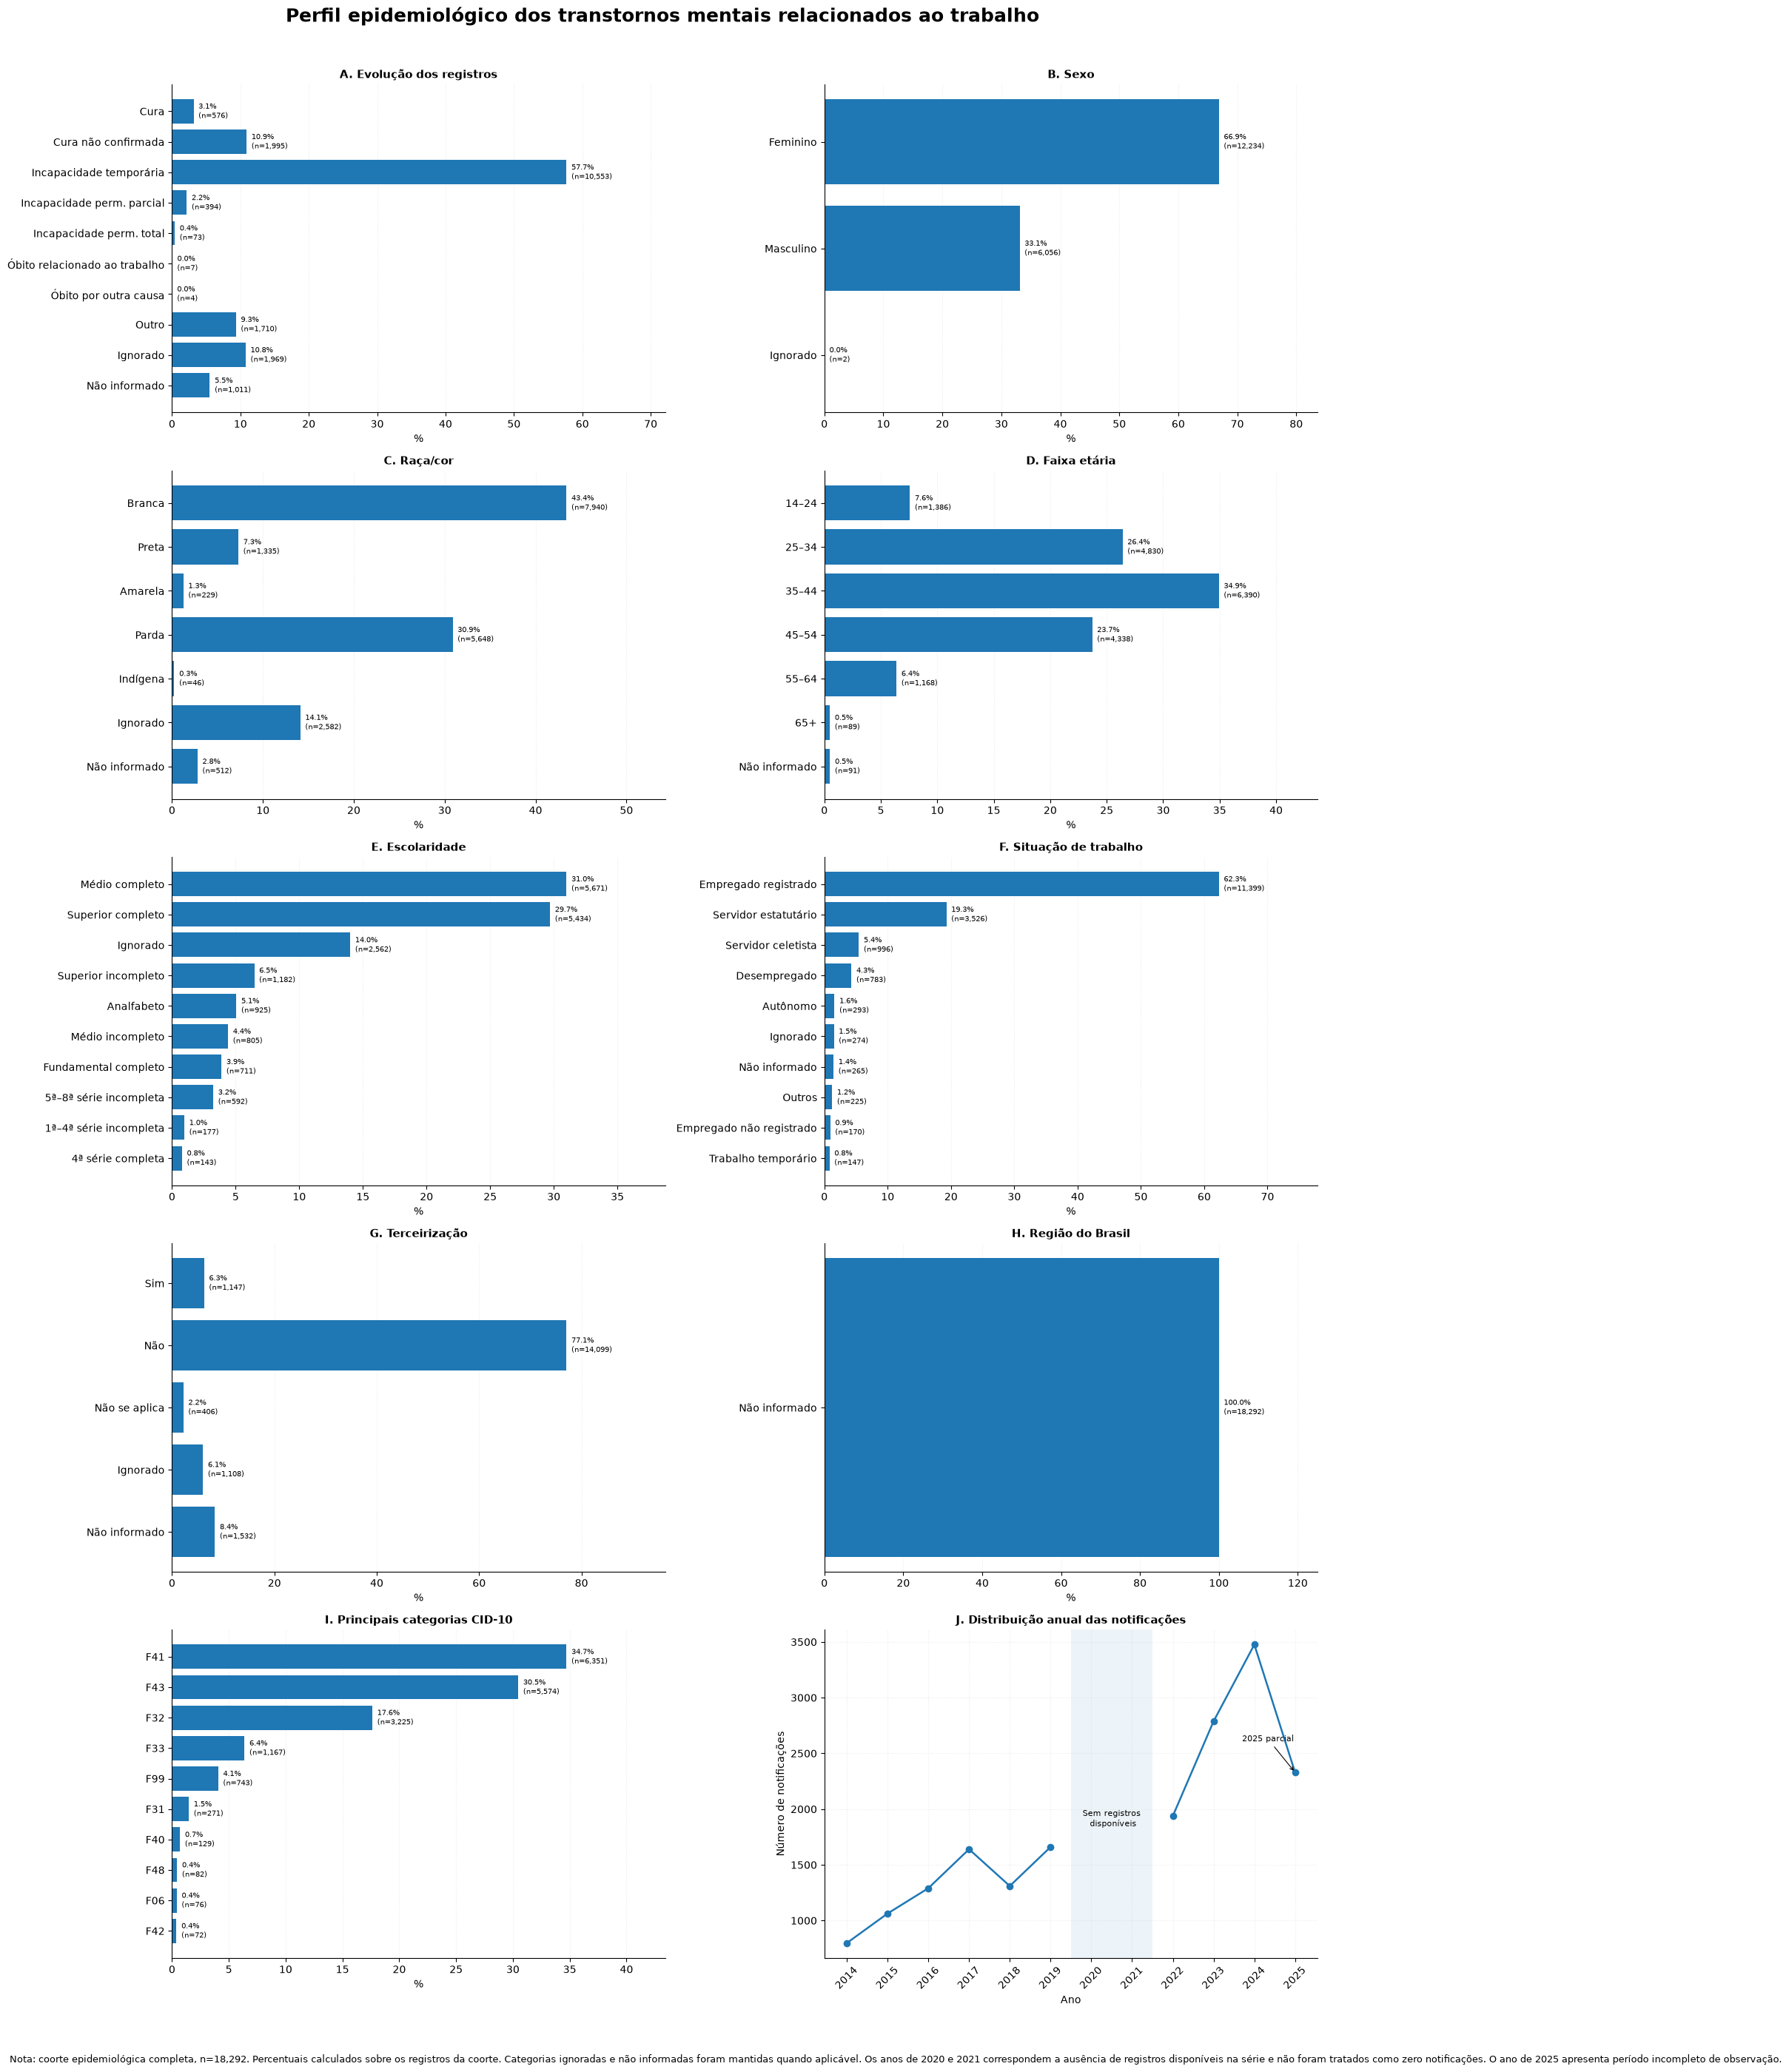

In [72]:
# ============================================================
# DASHBOARD EPIDEMIOLÓGICO INTEGRADO — VERSÃO EDITORIAL
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# ============================================================
# 1. BASE
# ============================================================

if 'df_analitico_completo' not in globals():
    raise NameError(
        "df_analitico_completo não existe no kernel."
    )

base = df_analitico_completo.copy()

N_TOTAL = len(base)

# ============================================================
# 2. FUNÇÕES AUXILIARES
# ============================================================

def limpar_codigo(serie):
    """
    Converte códigos numéricos/categóricos em strings padronizadas.
    Ex.: 1.0 -> '1'; 35.0 -> '35'
    """
    s = serie.astype('string').str.strip()

    s = (
        s
        .str.replace(r'\.0$', '', regex=True)
        .replace({
            '': pd.NA,
            'nan': pd.NA,
            'None': pd.NA,
            '<NA>': pd.NA
        })
    )

    return s


def tabela_percentual(
    serie,
    mapa=None,
    ordem=None,
    top=None
):
    s = serie.copy()

    if mapa is not None:
        s = s.map(mapa)

    s = s.astype('string').fillna('Não informado')

    tab = (
        s.value_counts(dropna=False)
        .rename_axis('categoria')
        .reset_index(name='N')
    )

    tab['PCT'] = 100 * tab['N'] / N_TOTAL

    if ordem is not None:
        ordem_dict = {
            categoria: i
            for i, categoria in enumerate(ordem)
        }

        tab['_ordem'] = (
            tab['categoria']
            .map(ordem_dict)
            .fillna(999)
        )

        tab = (
            tab
            .sort_values('_ordem')
            .drop(columns='_ordem')
        )

    if top is not None:
        tab = tab.head(top)

    return tab.reset_index(drop=True)


def estilo_eixo(ax):

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.spines['left'].set_alpha(0.35)
    ax.spines['bottom'].set_alpha(0.35)

    ax.tick_params(
        axis='both',
        labelsize=8,
        length=0
    )

    ax.grid(
        axis='x',
        linestyle=':',
        linewidth=0.7,
        alpha=0.22
    )

    ax.set_axisbelow(True)


def barras_percentuais(
    ax,
    tabela,
    titulo,
    mostrar_n=False,
    tamanho=8
):

    dados = tabela.copy()

    barras = ax.barh(
        dados['categoria'],
        dados['PCT']
    )

    ax.invert_yaxis()

    estilo_eixo(ax)

    ax.set_title(
        titulo,
        loc='left',
        fontsize=11,
        fontweight='bold',
        pad=9
    )

    ax.set_xlabel(
        'Percentual da coorte (%)',
        fontsize=8
    )

    maior = dados['PCT'].max()

    limite = max(
        maior * 1.25,
        5
    )

    ax.set_xlim(0, limite)

    for barra, (_, linha) in zip(
        barras,
        dados.iterrows()
    ):

        pct = linha['PCT']
        n = linha['N']

        if mostrar_n:

            texto = (
                f'{pct:.1f}%  '
                f'(n={n:,})'
            )

        else:

            texto = f'{pct:.1f}%'

        ax.text(
            barra.get_width() + limite * 0.012,
            barra.get_y() + barra.get_height()/2,
            texto,
            va='center',
            fontsize=tamanho
        )


def card_kpi(
    ax,
    valor,
    titulo,
    subtitulo=None
):

    ax.axis('off')

    ax.text(
        0.02,
        0.68,
        valor,
        transform=ax.transAxes,
        fontsize=21,
        fontweight='bold',
        va='center'
    )

    ax.text(
        0.02,
        0.36,
        titulo,
        transform=ax.transAxes,
        fontsize=9.5,
        fontweight='bold',
        va='center'
    )

    if subtitulo is not None:

        ax.text(
            0.02,
            0.12,
            subtitulo,
            transform=ax.transAxes,
            fontsize=7.5,
            alpha=0.65,
            va='center'
        )

    # linha discreta inferior
    ax.plot(
        [0.02, 0.98],
        [0.02, 0.02],
        transform=ax.transAxes,
        linewidth=1,
        alpha=0.25
    )


# ============================================================
# 3. EVOLUÇÃO
# ============================================================

evolucao_num = pd.to_numeric(
    base['EVOLUCAO'],
    errors='coerce'
)

mapa_evolucao = {
    1: 'Cura',
    2: 'Cura não confirmada',
    3: 'Incapacidade temporária',
    4: 'Incapacidade perm. parcial',
    5: 'Incapacidade perm. total',
    6: 'Óbito relacionado ao trabalho',
    7: 'Óbito por outra causa',
    8: 'Outro',
    9: 'Ignorado'
}

evolucao_label = (
    evolucao_num
    .map(mapa_evolucao)
    .fillna('Não informado')
)

ordem_evolucao = [
    'Incapacidade temporária',
    'Cura não confirmada',
    'Outro',
    'Ignorado',
    'Não informado',
    'Cura',
    'Incapacidade perm. parcial',
    'Incapacidade perm. total',
    'Óbito relacionado ao trabalho',
    'Óbito por outra causa'
]

tab_evolucao = tabela_percentual(
    evolucao_label,
    ordem=ordem_evolucao
)

# ============================================================
# 4. SEXO
# ============================================================

sexo_cod = limpar_codigo(base['CS_SEXO'])

mapa_sexo = {
    'F': 'Feminino',
    'M': 'Masculino',
    'I': 'Ignorado'
}

sexo_label = (
    sexo_cod
    .map(mapa_sexo)
    .fillna('Não informado')
)

tab_sexo = tabela_percentual(
    sexo_label,
    ordem=[
        'Feminino',
        'Masculino',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 5. RAÇA / COR
# ============================================================

raca_cod = limpar_codigo(base['CS_RACA'])

mapa_raca = {
    '1': 'Branca',
    '2': 'Preta',
    '3': 'Amarela',
    '4': 'Parda',
    '5': 'Indígena',
    '9': 'Ignorado'
}

raca_label = (
    raca_cod
    .map(mapa_raca)
    .fillna('Não informado')
)

tab_raca = tabela_percentual(
    raca_label,
    ordem=[
        'Branca',
        'Parda',
        'Preta',
        'Amarela',
        'Indígena',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 6. IDADE
# ============================================================

idade_cod = pd.to_numeric(
    base['NU_IDADE_N'],
    errors='coerce'
)

unidade = idade_cod // 1000
valor = idade_cod % 1000

idade_anos = pd.Series(
    np.where(
        unidade == 4,
        valor,
        np.nan
    ),
    index=base.index
)

# Idades implausíveis para análise ocupacional
idade_anos = idade_anos.mask(
    (idade_anos < 14) |
    (idade_anos > 100)
)

faixa_idade = pd.cut(
    idade_anos,
    bins=[
        13,
        24,
        34,
        44,
        54,
        64,
        np.inf
    ],
    labels=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+'
    ]
)

faixa_idade = (
    faixa_idade
    .astype('string')
    .fillna('Não informado')
)

tab_idade = tabela_percentual(
    faixa_idade,
    ordem=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+',
        'Não informado'
    ]
)

# ============================================================
# 7. ESCOLARIDADE
# ============================================================

esc_cod = limpar_codigo(base['CS_ESCOL_N'])

mapa_escolaridade = {
    '0': 'Analfabeto',
    '00': 'Analfabeto',
    '1': '1ª–4ª série incompleta',
    '01': '1ª–4ª série incompleta',
    '2': '4ª série completa',
    '02': '4ª série completa',
    '3': '5ª–8ª série incompleta',
    '03': '5ª–8ª série incompleta',
    '4': 'Fundamental completo',
    '04': 'Fundamental completo',
    '5': 'Médio incompleto',
    '05': 'Médio incompleto',
    '6': 'Médio completo',
    '06': 'Médio completo',
    '7': 'Superior incompleto',
    '07': 'Superior incompleto',
    '8': 'Superior completo',
    '08': 'Superior completo',
    '9': 'Ignorado',
    '09': 'Ignorado',
    '10': 'Não se aplica'
}

esc_label = (
    esc_cod
    .map(mapa_escolaridade)
    .fillna('Não informado')
)

tab_escolaridade = (
    tabela_percentual(esc_label)
    .sort_values(
        'N',
        ascending=False
    )
    .reset_index(drop=True)
)

# ============================================================
# 8. SITUAÇÃO DE TRABALHO
# ============================================================

sit_cod = limpar_codigo(base['SIT_TRAB'])

mapa_sit = {
    '1': 'Empregado registrado',
    '01': 'Empregado registrado',

    '2': 'Empregado não registrado',
    '02': 'Empregado não registrado',

    '3': 'Autônomo',
    '03': 'Autônomo',

    '4': 'Servidor estatutário',
    '04': 'Servidor estatutário',

    '5': 'Servidor celetista',
    '05': 'Servidor celetista',

    '6': 'Aposentado',
    '06': 'Aposentado',

    '7': 'Desempregado',
    '07': 'Desempregado',

    '8': 'Trabalho temporário',
    '08': 'Trabalho temporário',

    '9': 'Cooperativado',
    '09': 'Cooperativado',

    '10': 'Trabalhador avulso',
    '11': 'Empregador',
    '12': 'Outros',
    '99': 'Ignorado'
}

sit_label = (
    sit_cod
    .map(mapa_sit)
    .fillna('Não informado')
)

tab_sit = (
    tabela_percentual(sit_label)
    .sort_values(
        'N',
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

# ============================================================
# 9. TERCEIRIZAÇÃO
# ============================================================

terc_cod = limpar_codigo(
    base['TERCEIRIZA']
)

mapa_terc = {
    '1': 'Sim',
    '01': 'Sim',
    '2': 'Não',
    '02': 'Não',
    '3': 'Não se aplica',
    '03': 'Não se aplica',
    '9': 'Ignorado',
    '09': 'Ignorado'
}

terc_label = (
    terc_cod
    .map(mapa_terc)
    .fillna('Não informado')
)

tab_terc = tabela_percentual(
    terc_label,
    ordem=[
        'Sim',
        'Não',
        'Não se aplica',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 10. UF E REGIÃO — CORREÇÃO DO DASHBOARD ANTERIOR
# ============================================================

uf_cod = limpar_codigo(
    base['SG_UF']
).str.upper()

# Códigos IBGE de UF
codigo_uf = {
    '11': 'RO',
    '12': 'AC',
    '13': 'AM',
    '14': 'RR',
    '15': 'PA',
    '16': 'AP',
    '17': 'TO',

    '21': 'MA',
    '22': 'PI',
    '23': 'CE',
    '24': 'RN',
    '25': 'PB',
    '26': 'PE',
    '27': 'AL',
    '28': 'SE',
    '29': 'BA',

    '31': 'MG',
    '32': 'ES',
    '33': 'RJ',
    '35': 'SP',

    '41': 'PR',
    '42': 'SC',
    '43': 'RS',

    '50': 'MS',
    '51': 'MT',
    '52': 'GO',
    '53': 'DF'
}

# Aceita tanto código numérico quanto sigla
uf_tratada = uf_cod.map(
    lambda x:
    codigo_uf.get(x, x)
    if pd.notna(x)
    else pd.NA
)

mapa_regiao = {
    'AC': 'Norte',
    'AP': 'Norte',
    'AM': 'Norte',
    'PA': 'Norte',
    'RO': 'Norte',
    'RR': 'Norte',
    'TO': 'Norte',

    'AL': 'Nordeste',
    'BA': 'Nordeste',
    'CE': 'Nordeste',
    'MA': 'Nordeste',
    'PB': 'Nordeste',
    'PE': 'Nordeste',
    'PI': 'Nordeste',
    'RN': 'Nordeste',
    'SE': 'Nordeste',

    'DF': 'Centro-Oeste',
    'GO': 'Centro-Oeste',
    'MT': 'Centro-Oeste',
    'MS': 'Centro-Oeste',

    'ES': 'Sudeste',
    'MG': 'Sudeste',
    'RJ': 'Sudeste',
    'SP': 'Sudeste',

    'PR': 'Sul',
    'RS': 'Sul',
    'SC': 'Sul'
}

regiao = (
    uf_tratada
    .map(mapa_regiao)
    .fillna('Não informado')
)

tab_regiao = tabela_percentual(
    regiao,
    ordem=[
        'Sudeste',
        'Sul',
        'Nordeste',
        'Centro-Oeste',
        'Norte',
        'Não informado'
    ]
)

# ============================================================
# 11. CID-10
# ============================================================

cid = (
    base['CATEGORIA_CID']
    .astype('string')
    .fillna('Não informado')
)

tab_cid = (
    cid.value_counts()
    .head(8)
    .rename_axis('categoria')
    .reset_index(name='N')
)

tab_cid['PCT'] = (
    100 * tab_cid['N'] /
    N_TOTAL
)

# ============================================================
# 12. SÉRIE TEMPORAL
# ============================================================

anos = list(
    range(2014, 2026)
)

serie = (
    base
    .groupby('NU_ANO')
    .size()
    .reindex(anos)
    .astype(float)
)

# anos ausentes ≠ zero
serie.loc[2020] = np.nan
serie.loc[2021] = np.nan

# ============================================================
# 13. KPIs
# ============================================================

pct_mulheres = (
    100 *
    (sexo_label == 'Feminino').sum() /
    N_TOTAL
)

n_incapacidade = (
    evolucao_num
    .isin([3, 4, 5])
    .sum()
)

pct_incapacidade = (
    100 *
    n_incapacidade /
    N_TOTAL
)

cid_freq = (
    cid.value_counts()
)

cid_principal = cid_freq.index[0]
cid_principal_n = cid_freq.iloc[0]

cid_principal_pct = (
    100 *
    cid_principal_n /
    N_TOTAL
)

anos_hist = (
    base.loc[
        pd.to_numeric(
            base['NU_ANO'],
            errors='coerce'
        ) <= 2024
    ]
    .groupby('NU_ANO')
    .size()
)

ano_pico = int(
    anos_hist.idxmax()
)

n_pico = int(
    anos_hist.max()
)

# ============================================================
# 14. ARQUITETURA DA FIGURA
# ============================================================

fig = plt.figure(
    figsize=(18, 22)
)

gs = GridSpec(
    nrows=20,
    ncols=12,
    figure=fig,
    hspace=1.35,
    wspace=1.65
)

fig.suptitle(
    'Transtornos mentais relacionados ao trabalho',
    x=0.055,
    y=0.992,
    ha='left',
    fontsize=22,
    fontweight='bold'
)

fig.text(
    0.055,
    0.970,
    (
        'Painel epidemiológico integrado da coorte '
        f'— {N_TOTAL:,} notificações'
    ),
    fontsize=11,
    alpha=0.68,
    ha='left'
)

# ============================================================
# 15. CARDS
# ============================================================

ax_k1 = fig.add_subplot(
    gs[1:3, 0:3]
)

ax_k2 = fig.add_subplot(
    gs[1:3, 3:6]
)

ax_k3 = fig.add_subplot(
    gs[1:3, 6:9]
)

ax_k4 = fig.add_subplot(
    gs[1:3, 9:12]
)

card_kpi(
    ax_k1,
    f'{N_TOTAL:,}',
    'Notificações na coorte',
    'CID-10 capítulo F'
)

card_kpi(
    ax_k2,
    f'{pct_mulheres:.1f}%',
    'Sexo feminino',
    'Percentual da coorte'
)

card_kpi(
    ax_k3,
    f'{pct_incapacidade:.1f}%',
    'Evolução para incapacidade',
    'Temporária ou permanente'
)

card_kpi(
    ax_k4,
    f'{ano_pico}',
    'Maior volume anual',
    f'{n_pico:,} notificações'
)

# ============================================================
# 16. SÉRIE TEMPORAL — PAINEL PRINCIPAL
# ============================================================

ax1 = fig.add_subplot(
    gs[4:8, 0:7]
)

ax1.plot(
    anos,
    serie.values,
    marker='o',
    linewidth=2.2,
    markersize=5
)

ax1.set_title(
    'A. Evolução temporal das notificações',
    loc='left',
    fontsize=12,
    fontweight='bold',
    pad=10
)

ax1.set_ylabel(
    'Número de notificações',
    fontsize=9
)

ax1.set_xlabel(
    'Ano',
    fontsize=9
)

ax1.set_xticks(
    anos
)

ax1.tick_params(
    axis='x',
    rotation=45
)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

ax1.grid(
    linestyle=':',
    alpha=0.22
)

# lacuna real da série
ax1.axvspan(
    2019.5,
    2021.5,
    alpha=0.07
)

ax1.text(
    2020.5,
    np.nanmax(serie.values) * 0.52,
    'Sem registros\ndisponíveis',
    ha='center',
    va='center',
    fontsize=8,
    alpha=0.70
)

# 2025 parcial
if (
    2025 in serie.index and
    pd.notna(serie.loc[2025])
):

    ax1.annotate(
        '2025 parcial',
        xy=(
            2025,
            serie.loc[2025]
        ),
        xytext=(
            2023.8,
            serie.loc[2025] * 0.84
        ),
        fontsize=8,
        arrowprops={
            'arrowstyle': '-',
            'linewidth': 0.8
        }
    )

# ============================================================
# 17. EVOLUÇÃO
# ============================================================

ax2 = fig.add_subplot(
    gs[4:8, 7:12]
)

barras_percentuais(
    ax2,
    tab_evolucao,
    'B. Evolução clínica registrada',
    mostrar_n=False,
    tamanho=7.5
)

# ============================================================
# 18. REGIÃO
# ============================================================

ax3 = fig.add_subplot(
    gs[9:12, 0:4]
)

barras_percentuais(
    ax3,
    tab_regiao,
    'C. Região do Brasil'
)

# ============================================================
# 19. SEXO
# ============================================================

ax4 = fig.add_subplot(
    gs[9:12, 4:8]
)

barras_percentuais(
    ax4,
    tab_sexo,
    'D. Sexo'
)

# ============================================================
# 20. FAIXA ETÁRIA
# ============================================================

ax5 = fig.add_subplot(
    gs[9:12, 8:12]
)

barras_percentuais(
    ax5,
    tab_idade,
    'E. Faixa etária'
)

# ============================================================
# 21. RAÇA/COR
# ============================================================

ax6 = fig.add_subplot(
    gs[13:16, 0:4]
)

barras_percentuais(
    ax6,
    tab_raca,
    'F. Raça/cor'
)

# ============================================================
# 22. ESCOLARIDADE
# ============================================================

ax7 = fig.add_subplot(
    gs[13:16, 4:8]
)

barras_percentuais(
    ax7,
    tab_escolaridade.head(8),
    'G. Escolaridade'
)

# ============================================================
# 23. SITUAÇÃO DE TRABALHO
# ============================================================

ax8 = fig.add_subplot(
    gs[13:16, 8:12]
)

barras_percentuais(
    ax8,
    tab_sit,
    'H. Situação de trabalho'
)

# ============================================================
# 24. PRINCIPAIS CIDs
# ============================================================

ax9 = fig.add_subplot(
    gs[17:20, 0:6]
)

barras_percentuais(
    ax9,
    tab_cid,
    'I. Principais categorias CID-10',
    mostrar_n=True
)

# ============================================================
# 25. TERCEIRIZAÇÃO
# ============================================================

ax10 = fig.add_subplot(
    gs[17:20, 7:12]
)

barras_percentuais(
    ax10,
    tab_terc,
    'J. Terceirização'
)

# ============================================================
# 26. NOTAS
# ============================================================

fig.text(
    0.055,
    0.015,
    (
        'Nota: os percentuais referem-se à coorte epidemiológica completa. '
        'Categorias ignoradas e não informadas foram preservadas. '
        '2020–2021 representam ausência de observações disponíveis na base, '
        'e não zero notificações. 2025 corresponde a período incompleto.'
    ),
    ha='left',
    fontsize=8,
    alpha=0.65
)

plt.show()

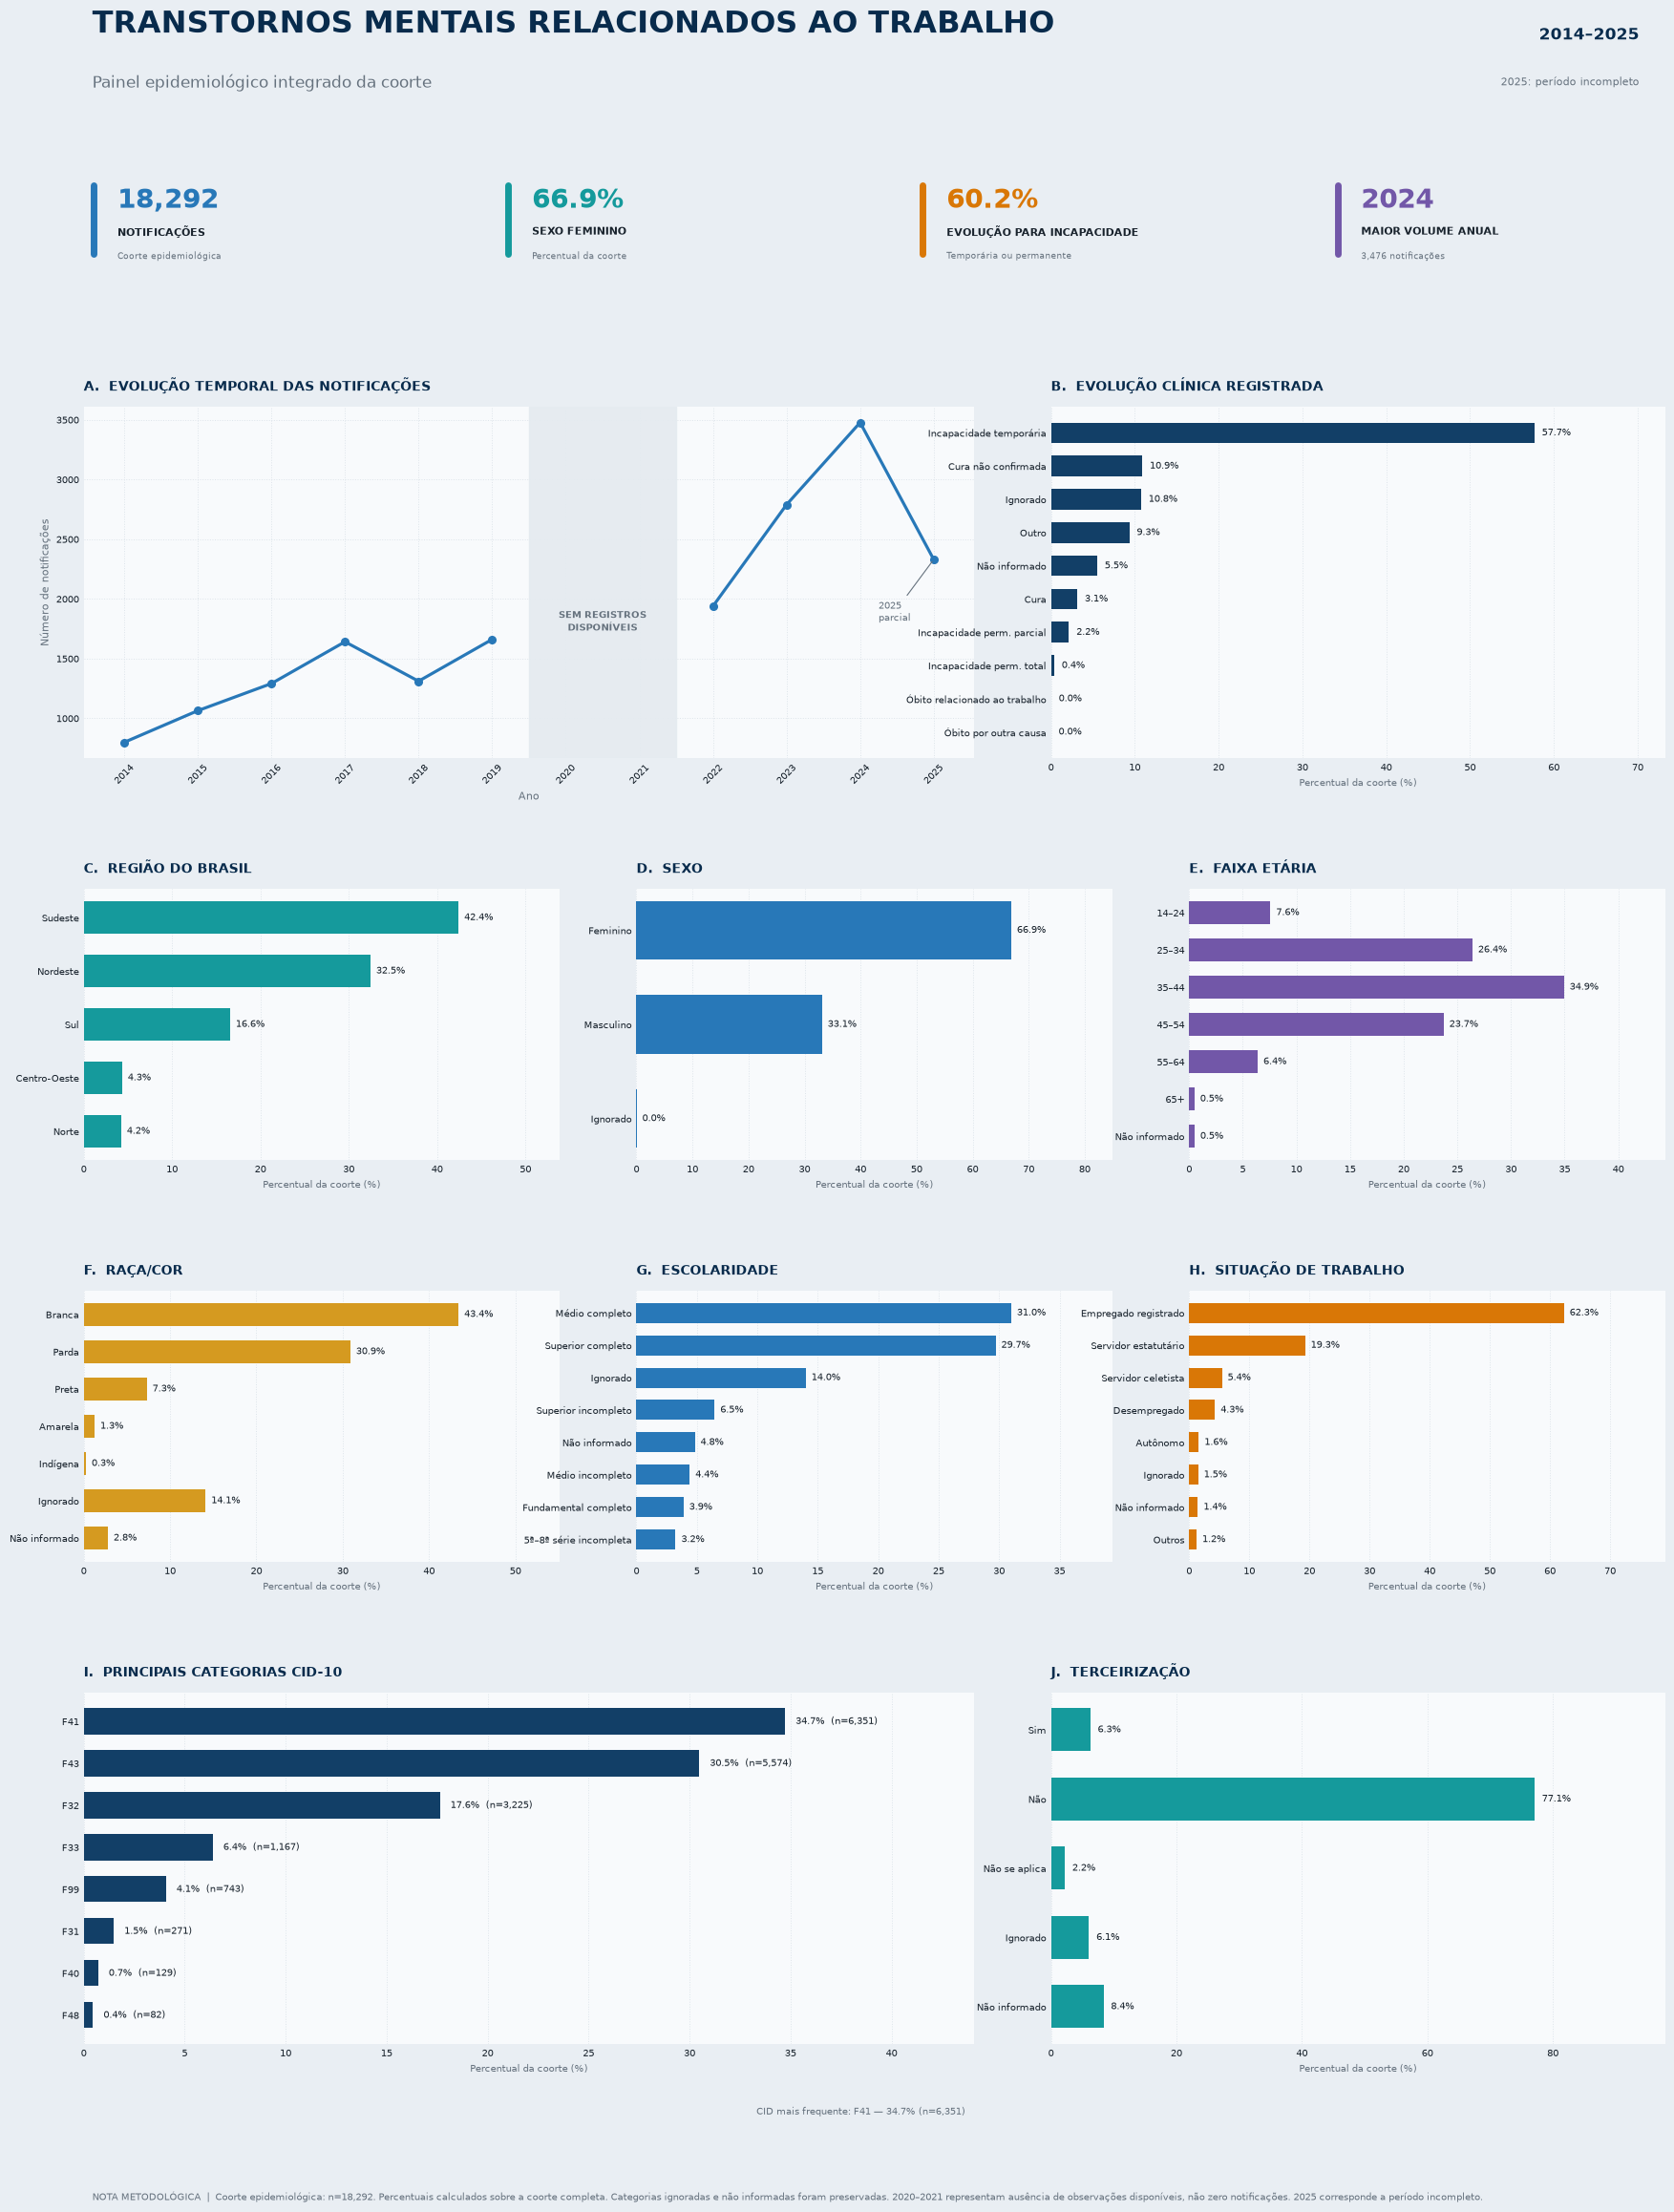


Dashboard salvo como:
dashboard_epidemiologico_executivo.png


In [76]:
# ============================================================
# DASHBOARD EXECUTIVO — PERFIL EPIDEMIOLÓGICO
# Transtornos mentais relacionados ao trabalho
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# ------------------------------------------------------------
# 0. VERIFICAÇÃO DA BASE
# ------------------------------------------------------------

if 'df_analitico_completo' not in globals():
    raise NameError(
        "df_analitico_completo não foi encontrado no kernel."
    )

base = df_analitico_completo.copy()
N_TOTAL = len(base)

# ------------------------------------------------------------
# 1. PALETA / IDENTIDADE VISUAL
# ------------------------------------------------------------

NAVY = '#082B4C'
NAVY_2 = '#123F67'
BLUE = '#2878B8'
TEAL = '#159A9C'
GOLD = '#D59A20'
ORANGE = '#D97706'
PURPLE = '#7257A8'

PAGE_BG = '#E9EEF3'
CARD_BG = '#FFFFFF'
PANEL_BG = '#F8FAFC'

TEXT = '#18222C'
MUTED = '#66727E'
GRID = '#DDE4EA'

# ------------------------------------------------------------
# 2. FUNÇÕES AUXILIARES
# ------------------------------------------------------------

def limpar_codigo(serie):
    s = serie.astype('string').str.strip()

    s = s.str.replace(
        r'\.0$',
        '',
        regex=True
    )

    return s.replace({
        '': pd.NA,
        'nan': pd.NA,
        'None': pd.NA,
        '<NA>': pd.NA
    })


def tabela_pct(serie, ordem=None, top=None):

    s = (
        serie.astype('string')
        .fillna('Não informado')
    )

    tab = (
        s.value_counts(dropna=False)
        .rename_axis('categoria')
        .reset_index(name='N')
    )

    tab['PCT'] = (
        100 * tab['N'] / N_TOTAL
    )

    if ordem is not None:

        ordem_dict = {
            nome: i
            for i, nome in enumerate(ordem)
        }

        tab['_ordem'] = (
            tab['categoria']
            .map(ordem_dict)
            .fillna(999)
        )

        tab = (
            tab.sort_values('_ordem')
            .drop(columns='_ordem')
        )

    if top is not None:
        tab = tab.head(top)

    return tab.reset_index(drop=True)


def painel(ax, titulo, letra=None):

    ax.set_facecolor(PANEL_BG)

    for spine in ax.spines.values():
        spine.set_visible(False)

    titulo_final = (
        f'{letra}.  {titulo}'
        if letra
        else titulo
    )

    ax.set_title(
        titulo_final.upper(),
        loc='left',
        fontsize=10,
        fontweight='bold',
        color=NAVY,
        pad=12
    )

    ax.tick_params(
        axis='both',
        labelsize=7.5,
        colors=TEXT,
        length=0
    )


def barras(
    ax,
    tab,
    titulo,
    letra,
    cor=BLUE,
    mostrar_n=False,
    xlabel='Percentual da coorte (%)'
):

    painel(ax, titulo, letra)

    dados = tab.copy()

    bars = ax.barh(
        dados['categoria'],
        dados['PCT'],
        color=cor,
        height=0.62
    )

    ax.invert_yaxis()

    ax.grid(
        axis='x',
        linestyle=':',
        linewidth=0.7,
        color=GRID
    )

    ax.set_axisbelow(True)

    ax.set_xlabel(
        xlabel,
        fontsize=7.5,
        color=MUTED
    )

    maior = max(dados['PCT'].max(), 1)
    limite = maior * 1.27

    ax.set_xlim(0, limite)

    for bar, (_, row) in zip(
        bars,
        dados.iterrows()
    ):

        if mostrar_n:
            label = (
                f"{row['PCT']:.1f}%  "
                f"(n={row['N']:,})"
            )
        else:
            label = f"{row['PCT']:.1f}%"

        ax.text(
            bar.get_width() + limite * 0.012,
            bar.get_y() + bar.get_height()/2,
            label,
            va='center',
            ha='left',
            fontsize=7.2,
            color=TEXT
        )


def card_kpi(
    ax,
    valor,
    titulo,
    subtitulo,
    cor
):

    ax.axis('off')

    ax.plot(
        [0.03, 0.03],
        [0.20, 0.82],
        transform=ax.transAxes,
        color=cor,
        linewidth=5,
        solid_capstyle='round'
    )

    ax.text(
        0.10,
        0.68,
        valor,
        transform=ax.transAxes,
        fontsize=20,
        fontweight='bold',
        color=cor,
        va='center'
    )

    ax.text(
        0.10,
        0.40,
        titulo.upper(),
        transform=ax.transAxes,
        fontsize=7.8,
        fontweight='bold',
        color=TEXT,
        va='center'
    )

    ax.text(
        0.10,
        0.18,
        subtitulo,
        transform=ax.transAxes,
        fontsize=6.8,
        color=MUTED,
        va='center'
    )


# ============================================================
# 3. EVOLUÇÃO
# ============================================================

evolucao = pd.to_numeric(
    base['EVOLUCAO'],
    errors='coerce'
)

mapa_evolucao = {
    1: 'Cura',
    2: 'Cura não confirmada',
    3: 'Incapacidade temporária',
    4: 'Incapacidade perm. parcial',
    5: 'Incapacidade perm. total',
    6: 'Óbito relacionado ao trabalho',
    7: 'Óbito por outra causa',
    8: 'Outro',
    9: 'Ignorado'
}

evolucao_label = (
    evolucao
    .map(mapa_evolucao)
    .fillna('Não informado')
)

ordem_evolucao = [
    'Incapacidade temporária',
    'Cura não confirmada',
    'Ignorado',
    'Outro',
    'Não informado',
    'Cura',
    'Incapacidade perm. parcial',
    'Incapacidade perm. total',
    'Óbito relacionado ao trabalho',
    'Óbito por outra causa'
]

tab_evolucao = tabela_pct(
    evolucao_label,
    ordem=ordem_evolucao
)

# ============================================================
# 4. SEXO
# ============================================================

sexo_cod = (
    limpar_codigo(base['CS_SEXO'])
    .str.upper()
)

mapa_sexo = {
    'F': 'Feminino',
    'M': 'Masculino',
    'I': 'Ignorado'
}

sexo_label = (
    sexo_cod
    .map(mapa_sexo)
    .fillna('Não informado')
)

tab_sexo = tabela_pct(
    sexo_label,
    ordem=[
        'Feminino',
        'Masculino',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 5. RAÇA/COR
# ============================================================

raca_cod = limpar_codigo(
    base['CS_RACA']
)

mapa_raca = {
    '1': 'Branca',
    '2': 'Preta',
    '3': 'Amarela',
    '4': 'Parda',
    '5': 'Indígena',
    '9': 'Ignorado'
}

raca_label = (
    raca_cod
    .map(mapa_raca)
    .fillna('Não informado')
)

tab_raca = tabela_pct(
    raca_label,
    ordem=[
        'Branca',
        'Parda',
        'Preta',
        'Amarela',
        'Indígena',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 6. IDADE
# ============================================================

idade_cod = pd.to_numeric(
    base['NU_IDADE_N'],
    errors='coerce'
)

unidade = idade_cod // 1000
valor = idade_cod % 1000

idade_anos = pd.Series(
    np.where(
        unidade == 4,
        valor,
        np.nan
    ),
    index=base.index
)

idade_anos = idade_anos.mask(
    (idade_anos < 14) |
    (idade_anos > 100)
)

faixa_idade = pd.cut(
    idade_anos,
    bins=[
        13,
        24,
        34,
        44,
        54,
        64,
        np.inf
    ],
    labels=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+'
    ]
)

faixa_idade = (
    faixa_idade
    .astype('string')
    .fillna('Não informado')
)

tab_idade = tabela_pct(
    faixa_idade,
    ordem=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+',
        'Não informado'
    ]
)

# ============================================================
# 7. ESCOLARIDADE
# ============================================================

esc = limpar_codigo(
    base['CS_ESCOL_N']
)

mapa_esc = {
    '0': 'Analfabeto',
    '00': 'Analfabeto',
    '1': '1ª–4ª série incompleta',
    '01': '1ª–4ª série incompleta',
    '2': '4ª série completa',
    '02': '4ª série completa',
    '3': '5ª–8ª série incompleta',
    '03': '5ª–8ª série incompleta',
    '4': 'Fundamental completo',
    '04': 'Fundamental completo',
    '5': 'Médio incompleto',
    '05': 'Médio incompleto',
    '6': 'Médio completo',
    '06': 'Médio completo',
    '7': 'Superior incompleto',
    '07': 'Superior incompleto',
    '8': 'Superior completo',
    '08': 'Superior completo',
    '9': 'Ignorado',
    '09': 'Ignorado',
    '10': 'Não se aplica'
}

esc_label = (
    esc.map(mapa_esc)
    .fillna('Não informado')
)

tab_esc = (
    tabela_pct(esc_label)
    .sort_values(
        'N',
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

# ============================================================
# 8. SITUAÇÃO DE TRABALHO
# ============================================================

sit = limpar_codigo(
    base['SIT_TRAB']
)

mapa_sit = {
    '1': 'Empregado registrado',
    '01': 'Empregado registrado',

    '2': 'Empregado não registrado',
    '02': 'Empregado não registrado',

    '3': 'Autônomo',
    '03': 'Autônomo',

    '4': 'Servidor estatutário',
    '04': 'Servidor estatutário',

    '5': 'Servidor celetista',
    '05': 'Servidor celetista',

    '6': 'Aposentado',
    '06': 'Aposentado',

    '7': 'Desempregado',
    '07': 'Desempregado',

    '8': 'Trabalho temporário',
    '08': 'Trabalho temporário',

    '9': 'Cooperativado',
    '09': 'Cooperativado',

    '10': 'Trabalhador avulso',
    '11': 'Empregador',
    '12': 'Outros',
    '99': 'Ignorado'
}

sit_label = (
    sit.map(mapa_sit)
    .fillna('Não informado')
)

tab_sit = (
    tabela_pct(sit_label)
    .sort_values(
        'N',
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

# ============================================================
# 9. TERCEIRIZAÇÃO
# ============================================================

terc = limpar_codigo(
    base['TERCEIRIZA']
)

mapa_terc = {
    '1': 'Sim',
    '01': 'Sim',
    '2': 'Não',
    '02': 'Não',
    '3': 'Não se aplica',
    '03': 'Não se aplica',
    '9': 'Ignorado',
    '09': 'Ignorado'
}

terc_label = (
    terc.map(mapa_terc)
    .fillna('Não informado')
)

tab_terc = tabela_pct(
    terc_label,
    ordem=[
        'Sim',
        'Não',
        'Não se aplica',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 10. REGIÃO
# ============================================================

uf_raw = (
    limpar_codigo(base['SG_UF'])
    .str.upper()
)

codigo_uf = {
    '11': 'RO',
    '12': 'AC',
    '13': 'AM',
    '14': 'RR',
    '15': 'PA',
    '16': 'AP',
    '17': 'TO',

    '21': 'MA',
    '22': 'PI',
    '23': 'CE',
    '24': 'RN',
    '25': 'PB',
    '26': 'PE',
    '27': 'AL',
    '28': 'SE',
    '29': 'BA',

    '31': 'MG',
    '32': 'ES',
    '33': 'RJ',
    '35': 'SP',

    '41': 'PR',
    '42': 'SC',
    '43': 'RS',

    '50': 'MS',
    '51': 'MT',
    '52': 'GO',
    '53': 'DF'
}

uf = uf_raw.map(
    lambda x:
    codigo_uf.get(x, x)
    if pd.notna(x)
    else pd.NA
)

mapa_regiao = {
    'AC': 'Norte',
    'AP': 'Norte',
    'AM': 'Norte',
    'PA': 'Norte',
    'RO': 'Norte',
    'RR': 'Norte',
    'TO': 'Norte',

    'AL': 'Nordeste',
    'BA': 'Nordeste',
    'CE': 'Nordeste',
    'MA': 'Nordeste',
    'PB': 'Nordeste',
    'PE': 'Nordeste',
    'PI': 'Nordeste',
    'RN': 'Nordeste',
    'SE': 'Nordeste',

    'DF': 'Centro-Oeste',
    'GO': 'Centro-Oeste',
    'MT': 'Centro-Oeste',
    'MS': 'Centro-Oeste',

    'ES': 'Sudeste',
    'MG': 'Sudeste',
    'RJ': 'Sudeste',
    'SP': 'Sudeste',

    'PR': 'Sul',
    'RS': 'Sul',
    'SC': 'Sul'
}

regiao_label = (
    uf.map(mapa_regiao)
    .fillna('Não informado')
)

tab_regiao = tabela_pct(
    regiao_label,
    ordem=[
        'Sudeste',
        'Nordeste',
        'Sul',
        'Centro-Oeste',
        'Norte',
        'Não informado'
    ]
)

# ============================================================
# 11. CID-10
# ============================================================

cid = (
    base['CATEGORIA_CID']
    .astype('string')
    .fillna('Não informado')
)

tab_cid = (
    cid.value_counts()
    .head(8)
    .rename_axis('categoria')
    .reset_index(name='N')
)

tab_cid['PCT'] = (
    100 * tab_cid['N'] /
    N_TOTAL
)

# ============================================================
# 12. SÉRIE TEMPORAL
# ============================================================

ano_num = pd.to_numeric(
    base['NU_ANO'],
    errors='coerce'
)

anos = list(
    range(2014, 2026)
)

serie = (
    base.assign(_ANO=ano_num)
    .groupby('_ANO')
    .size()
    .reindex(anos)
    .astype(float)
)

# 2020 e 2021 = ausência de registros
serie.loc[2020] = np.nan
serie.loc[2021] = np.nan

# ============================================================
# 13. KPIs
# ============================================================

pct_feminino = (
    100 *
    (sexo_label == 'Feminino').sum() /
    N_TOTAL
)

n_incap = (
    evolucao.isin([3, 4, 5])
    .sum()
)

pct_incap = (
    100 * n_incap /
    N_TOTAL
)

cid_principal = (
    cid.value_counts()
    .index[0]
)

cid_principal_n = (
    cid.value_counts()
    .iloc[0]
)

cid_principal_pct = (
    100 *
    cid_principal_n /
    N_TOTAL
)

serie_hist = (
    serie.loc[
        serie.index <= 2024
    ]
    .dropna()
)

ano_pico = int(
    serie_hist.idxmax()
)

n_pico = int(
    serie_hist.max()
)

# ============================================================
# 14. FIGURA
# ============================================================

fig = plt.figure(
    figsize=(18, 24),
    facecolor=PAGE_BG
)

gs = GridSpec(
    25,
    12,
    figure=fig,
    left=0.045,
    right=0.965,
    top=0.91,
    bottom=0.055,
    hspace=1.65,
    wspace=1.25
)

# ============================================================
# 15. CABEÇALHO
# ============================================================

fig.text(
    0.05,
    0.968,
    'TRANSTORNOS MENTAIS RELACIONADOS AO TRABALHO',
    fontsize=23,
    fontweight='bold',
    color=NAVY,
    ha='left'
)

fig.text(
    0.05,
    0.944,
    'Painel epidemiológico integrado da coorte',
    fontsize=12,
    color=MUTED,
    ha='left'
)

fig.text(
    0.95,
    0.965,
    '2014–2025',
    fontsize=12,
    fontweight='bold',
    color=NAVY,
    ha='right'
)

fig.text(
    0.95,
    0.945,
    '2025: período incompleto',
    fontsize=8,
    color=MUTED,
    ha='right'
)

# ============================================================
# 16. KPIs
# ============================================================

k1 = fig.add_subplot(
    gs[0:2, 0:3]
)

k2 = fig.add_subplot(
    gs[0:2, 3:6]
)

k3 = fig.add_subplot(
    gs[0:2, 6:9]
)

k4 = fig.add_subplot(
    gs[0:2, 9:12]
)

for ax in [k1, k2, k3, k4]:
    ax.set_facecolor(CARD_BG)

card_kpi(
    k1,
    f'{N_TOTAL:,}',
    'Notificações',
    'Coorte epidemiológica',
    BLUE
)

card_kpi(
    k2,
    f'{pct_feminino:.1f}%',
    'Sexo feminino',
    'Percentual da coorte',
    TEAL
)

card_kpi(
    k3,
    f'{pct_incap:.1f}%',
    'Evolução para incapacidade',
    'Temporária ou permanente',
    ORANGE
)

card_kpi(
    k4,
    f'{ano_pico}',
    'Maior volume anual',
    f'{n_pico:,} notificações',
    PURPLE
)

# ============================================================
# 17. PAINEL A — EVOLUÇÃO TEMPORAL PROFISSIONAL
# ============================================================

ax1 = fig.add_subplot(
    gs[3:8, 0:7]
)

painel(
    ax1,
    'Evolução temporal das notificações',
    'A'
)

serie_pre = (
    serie.loc[2014:2019]
    .dropna()
)

serie_pos = (
    serie.loc[2022:2025]
    .dropna()
)

# Área suave
ax1.fill_between(
    serie_pre.index,
    serie_pre.values,
    0,
    alpha=0.08,
    color=BLUE
)

ax1.fill_between(
    serie_pos.index,
    serie_pos.values,
    0,
    alpha=0.08,
    color=BLUE
)

# Segmento pré-lacuna
ax1.plot(
    serie_pre.index,
    serie_pre.values,
    color=BLUE,
    linewidth=2.6,
    marker='o',
    markersize=6
)

# Segmento pós-lacuna
ax1.plot(
    serie_pos.index,
    serie_pos.values,
    color=BLUE,
    linewidth=2.6,
    marker='o',
    markersize=6
)

# Lacuna
ax1.axvspan(
    2019.5,
    2021.5,
    color='#DDE5EC',
    alpha=0.85,
    zorder=0
)

ax1.text(
    2020.5,
    np.nanmax(serie.values) * 0.52,
    'SEM REGISTROS\nDISPONÍVEIS',
    ha='center',
    va='center',
    fontsize=7.5,
    color=MUTED,
    fontweight='bold'
)

# Valores 2014–2019
for ano, valor in serie_pre.items():

    ax1.text(
        ano,
        valor + 95,
        f'{int(valor):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=7.5,
        color=TEXT,
        fontweight='bold'
    )

# Valores 2022–2023
for ano, valor in serie_pos.items():

    if ano in [2024, 2025]:
        continue

    ax1.text(
        ano,
        valor + 95,
        f'{int(valor):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=7.5,
        color=TEXT,
        fontweight='bold'
    )

# Destaque 2024
if pd.notna(serie.loc[2024]):

    valor_2024 = serie.loc[2024]

    ax1.scatter(
        2024,
        valor_2024,
        s=90,
        color=ORANGE,
        zorder=5
    )

    ax1.text(
        2024,
        valor_2024 + 145,
        f'{int(valor_2024):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=8.5,
        color=ORANGE,
        fontweight='bold'
    )

    ax1.text(
        2024,
        valor_2024 + 320,
        'PICO DA SÉRIE',
        ha='center',
        va='bottom',
        fontsize=7,
        color=ORANGE,
        fontweight='bold'
    )

# Destaque 2025
if pd.notna(serie.loc[2025]):

    valor_2025 = serie.loc[2025]

    ax1.scatter(
        2025,
        valor_2025,
        s=75,
        color=PURPLE,
        zorder=5
    )

    ax1.text(
        2025,
        valor_2025 + 100,
        f'{int(valor_2025):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=7.5,
        color=PURPLE,
        fontweight='bold'
    )

    ax1.annotate(
        '2025 parcial',
        xy=(
            2025,
            valor_2025
        ),
        xytext=(
            2024.35,
            valor_2025 - 420
        ),
        fontsize=7.5,
        color=PURPLE,
        fontweight='bold',
        arrowprops=dict(
            arrowstyle='-',
            color=PURPLE,
            linewidth=1
        )
    )

ax1.set_xticks(
    range(2014, 2026)
)

ax1.set_xlim(
    2013.6,
    2025.4
)

ax1.set_ylim(
    0,
    np.nanmax(serie.values) * 1.24
)

ax1.set_xlabel(
    'Ano',
    fontsize=8,
    color=MUTED,
    labelpad=8
)

ax1.set_ylabel(
    'Número de notificações',
    fontsize=8,
    color=MUTED,
    labelpad=8
)

ax1.tick_params(
    axis='x',
    labelsize=7.5,
    rotation=0,
    colors=TEXT
)

ax1.tick_params(
    axis='y',
    labelsize=7.5,
    colors=TEXT
)

ax1.grid(
    axis='y',
    linestyle=':',
    linewidth=0.8,
    color=GRID
)

ax1.set_axisbelow(True)

# ============================================================
# 18. PAINEL B — EVOLUÇÃO
# ============================================================

ax2 = fig.add_subplot(
    gs[3:8, 7:12]
)

barras(
    ax2,
    tab_evolucao,
    'Evolução clínica registrada',
    'B',
    cor=NAVY_2
)

# ============================================================
# 19. REGIÃO
# ============================================================

ax3 = fig.add_subplot(
    gs[9:13, 0:4]
)

barras(
    ax3,
    tab_regiao,
    'Região do Brasil',
    'C',
    cor=TEAL
)

# ============================================================
# 20. SEXO
# ============================================================

ax4 = fig.add_subplot(
    gs[9:13, 4:8]
)

barras(
    ax4,
    tab_sexo,
    'Sexo',
    'D',
    cor=BLUE
)

# ============================================================
# 21. FAIXA ETÁRIA
# ============================================================

ax5 = fig.add_subplot(
    gs[9:13, 8:12]
)

barras(
    ax5,
    tab_idade,
    'Faixa etária',
    'E',
    cor=PURPLE
)

# ============================================================
# 22. RAÇA/COR
# ============================================================

ax6 = fig.add_subplot(
    gs[14:18, 0:4]
)

barras(
    ax6,
    tab_raca,
    'Raça/cor',
    'F',
    cor=GOLD
)

# ============================================================
# 23. ESCOLARIDADE
# ============================================================

ax7 = fig.add_subplot(
    gs[14:18, 4:8]
)

barras(
    ax7,
    tab_esc,
    'Escolaridade',
    'G',
    cor=BLUE
)

# ============================================================
# 24. SITUAÇÃO DE TRABALHO
# ============================================================

ax8 = fig.add_subplot(
    gs[14:18, 8:12]
)

barras(
    ax8,
    tab_sit,
    'Situação de trabalho',
    'H',
    cor=ORANGE
)

# ============================================================
# 25. PRINCIPAIS CIDs
# ============================================================

ax9 = fig.add_subplot(
    gs[19:24, 0:7]
)

barras(
    ax9,
    tab_cid,
    'Principais categorias CID-10',
    'I',
    cor=NAVY_2,
    mostrar_n=True
)

ax9.text(
    0.99,
    -0.20,
    (
        f'CID mais frequente: {cid_principal} '
        f'— {cid_principal_pct:.1f}% '
        f'(n={cid_principal_n:,})'
    ),
    transform=ax9.transAxes,
    ha='right',
    fontsize=7.5,
    color=MUTED
)

# ============================================================
# 26. TERCEIRIZAÇÃO
# ============================================================

ax10 = fig.add_subplot(
    gs[19:24, 7:12]
)

barras(
    ax10,
    tab_terc,
    'Terceirização',
    'J',
    cor=TEAL
)

# ============================================================
# 27. NOTA METODOLÓGICA
# ============================================================

fig.text(
    0.05,
    0.022,
    (
        'NOTA METODOLÓGICA  |  '
        f'Coorte epidemiológica: n={N_TOTAL:,}. '
        'Percentuais calculados sobre a coorte completa. '
        'Categorias ignoradas e não informadas foram preservadas. '
        '2020–2021 representam ausência de observações disponíveis, '
        'não zero notificações. '
        '2025 corresponde a período incompleto.'
    ),
    fontsize=7.5,
    color=MUTED,
    ha='left'
)

# ============================================================
# 28. SALVAR
# ============================================================

plt.savefig(
    'dashboard_epidemiologico_executivo_v2.png',
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()

print('\nDashboard salvo como:')
print('dashboard_epidemiologico_executivo_v2.png')

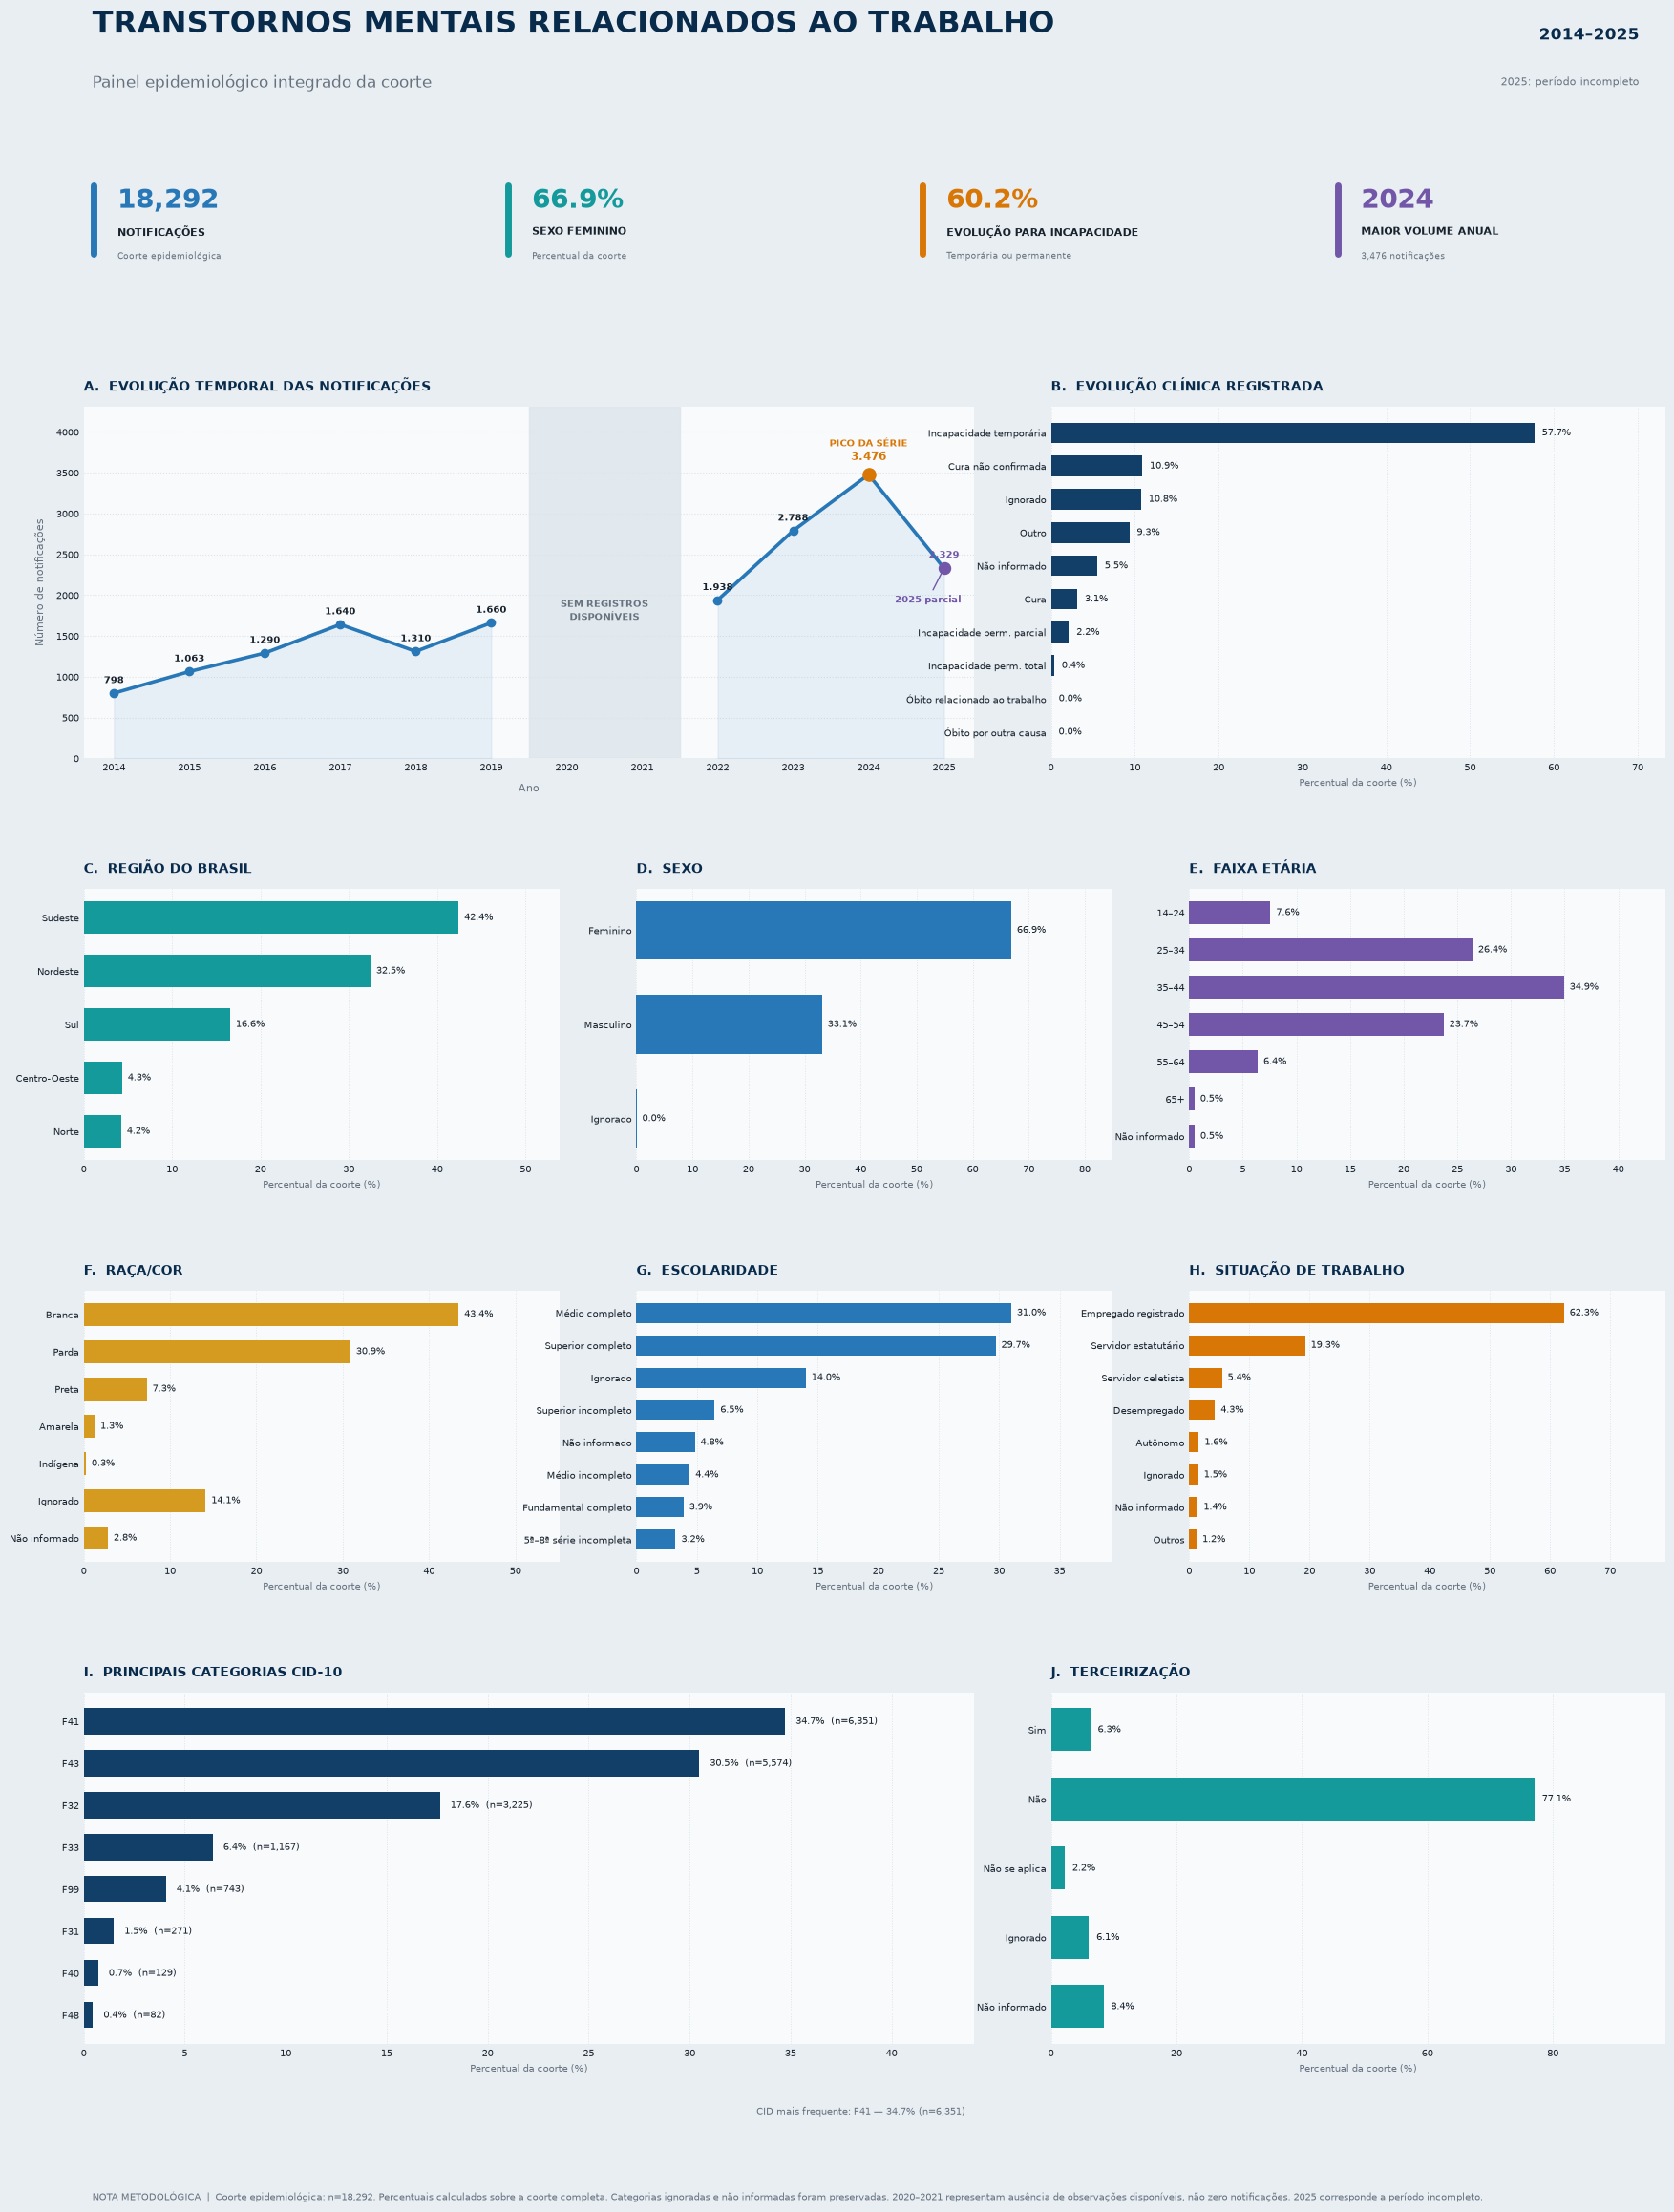


Dashboard salvo como:
dashboard_epidemiologico_executivo_v2.png


In [78]:
# ============================================================
# DASHBOARD EXECUTIVO — PERFIL EPIDEMIOLÓGICO
# Transtornos mentais relacionados ao trabalho
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# ------------------------------------------------------------
# 0. VERIFICAÇÃO DA BASE
# ------------------------------------------------------------

if 'df_analitico_completo' not in globals():
    raise NameError(
        "df_analitico_completo não foi encontrado no kernel."
    )

base = df_analitico_completo.copy()
N_TOTAL = len(base)

# ------------------------------------------------------------
# 1. PALETA / IDENTIDADE VISUAL
# ------------------------------------------------------------

NAVY = '#082B4C'
NAVY_2 = '#123F67'
BLUE = '#2878B8'
TEAL = '#159A9C'
GOLD = '#D59A20'
ORANGE = '#D97706'
PURPLE = '#7257A8'

PAGE_BG = '#E9EEF3'
CARD_BG = '#FFFFFF'
PANEL_BG = '#F8FAFC'

TEXT = '#18222C'
MUTED = '#66727E'
GRID = '#DDE4EA'

# ------------------------------------------------------------
# 2. FUNÇÕES AUXILIARES
# ------------------------------------------------------------

def limpar_codigo(serie):
    s = serie.astype('string').str.strip()

    s = s.str.replace(
        r'\.0$',
        '',
        regex=True
    )

    return s.replace({
        '': pd.NA,
        'nan': pd.NA,
        'None': pd.NA,
        '<NA>': pd.NA
    })


def tabela_pct(serie, ordem=None, top=None):

    s = (
        serie.astype('string')
        .fillna('Não informado')
    )

    tab = (
        s.value_counts(dropna=False)
        .rename_axis('categoria')
        .reset_index(name='N')
    )

    tab['PCT'] = (
        100 * tab['N'] / N_TOTAL
    )

    if ordem is not None:

        ordem_dict = {
            nome: i
            for i, nome in enumerate(ordem)
        }

        tab['_ordem'] = (
            tab['categoria']
            .map(ordem_dict)
            .fillna(999)
        )

        tab = (
            tab.sort_values('_ordem')
            .drop(columns='_ordem')
        )

    if top is not None:
        tab = tab.head(top)

    return tab.reset_index(drop=True)


def painel(ax, titulo, letra=None):

    ax.set_facecolor(PANEL_BG)

    for spine in ax.spines.values():
        spine.set_visible(False)

    titulo_final = (
        f'{letra}.  {titulo}'
        if letra
        else titulo
    )

    ax.set_title(
        titulo_final.upper(),
        loc='left',
        fontsize=10,
        fontweight='bold',
        color=NAVY,
        pad=12
    )

    ax.tick_params(
        axis='both',
        labelsize=7.5,
        colors=TEXT,
        length=0
    )


def barras(
    ax,
    tab,
    titulo,
    letra,
    cor=BLUE,
    mostrar_n=False,
    xlabel='Percentual da coorte (%)'
):

    painel(ax, titulo, letra)

    dados = tab.copy()

    bars = ax.barh(
        dados['categoria'],
        dados['PCT'],
        color=cor,
        height=0.62
    )

    ax.invert_yaxis()

    ax.grid(
        axis='x',
        linestyle=':',
        linewidth=0.7,
        color=GRID
    )

    ax.set_axisbelow(True)

    ax.set_xlabel(
        xlabel,
        fontsize=7.5,
        color=MUTED
    )

    maior = max(dados['PCT'].max(), 1)
    limite = maior * 1.27

    ax.set_xlim(0, limite)

    for bar, (_, row) in zip(
        bars,
        dados.iterrows()
    ):

        if mostrar_n:
            label = (
                f"{row['PCT']:.1f}%  "
                f"(n={row['N']:,})"
            )
        else:
            label = f"{row['PCT']:.1f}%"

        ax.text(
            bar.get_width() + limite * 0.012,
            bar.get_y() + bar.get_height()/2,
            label,
            va='center',
            ha='left',
            fontsize=7.2,
            color=TEXT
        )


def card_kpi(
    ax,
    valor,
    titulo,
    subtitulo,
    cor
):

    ax.axis('off')

    ax.plot(
        [0.03, 0.03],
        [0.20, 0.82],
        transform=ax.transAxes,
        color=cor,
        linewidth=5,
        solid_capstyle='round'
    )

    ax.text(
        0.10,
        0.68,
        valor,
        transform=ax.transAxes,
        fontsize=20,
        fontweight='bold',
        color=cor,
        va='center'
    )

    ax.text(
        0.10,
        0.40,
        titulo.upper(),
        transform=ax.transAxes,
        fontsize=7.8,
        fontweight='bold',
        color=TEXT,
        va='center'
    )

    ax.text(
        0.10,
        0.18,
        subtitulo,
        transform=ax.transAxes,
        fontsize=6.8,
        color=MUTED,
        va='center'
    )


# ============================================================
# 3. EVOLUÇÃO
# ============================================================

evolucao = pd.to_numeric(
    base['EVOLUCAO'],
    errors='coerce'
)

mapa_evolucao = {
    1: 'Cura',
    2: 'Cura não confirmada',
    3: 'Incapacidade temporária',
    4: 'Incapacidade perm. parcial',
    5: 'Incapacidade perm. total',
    6: 'Óbito relacionado ao trabalho',
    7: 'Óbito por outra causa',
    8: 'Outro',
    9: 'Ignorado'
}

evolucao_label = (
    evolucao
    .map(mapa_evolucao)
    .fillna('Não informado')
)

ordem_evolucao = [
    'Incapacidade temporária',
    'Cura não confirmada',
    'Ignorado',
    'Outro',
    'Não informado',
    'Cura',
    'Incapacidade perm. parcial',
    'Incapacidade perm. total',
    'Óbito relacionado ao trabalho',
    'Óbito por outra causa'
]

tab_evolucao = tabela_pct(
    evolucao_label,
    ordem=ordem_evolucao
)

# ============================================================
# 4. SEXO
# ============================================================

sexo_cod = (
    limpar_codigo(base['CS_SEXO'])
    .str.upper()
)

mapa_sexo = {
    'F': 'Feminino',
    'M': 'Masculino',
    'I': 'Ignorado'
}

sexo_label = (
    sexo_cod
    .map(mapa_sexo)
    .fillna('Não informado')
)

tab_sexo = tabela_pct(
    sexo_label,
    ordem=[
        'Feminino',
        'Masculino',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 5. RAÇA/COR
# ============================================================

raca_cod = limpar_codigo(
    base['CS_RACA']
)

mapa_raca = {
    '1': 'Branca',
    '2': 'Preta',
    '3': 'Amarela',
    '4': 'Parda',
    '5': 'Indígena',
    '9': 'Ignorado'
}

raca_label = (
    raca_cod
    .map(mapa_raca)
    .fillna('Não informado')
)

tab_raca = tabela_pct(
    raca_label,
    ordem=[
        'Branca',
        'Parda',
        'Preta',
        'Amarela',
        'Indígena',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 6. IDADE
# ============================================================

idade_cod = pd.to_numeric(
    base['NU_IDADE_N'],
    errors='coerce'
)

unidade = idade_cod // 1000
valor = idade_cod % 1000

idade_anos = pd.Series(
    np.where(
        unidade == 4,
        valor,
        np.nan
    ),
    index=base.index
)

idade_anos = idade_anos.mask(
    (idade_anos < 14) |
    (idade_anos > 100)
)

faixa_idade = pd.cut(
    idade_anos,
    bins=[
        13,
        24,
        34,
        44,
        54,
        64,
        np.inf
    ],
    labels=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+'
    ]
)

faixa_idade = (
    faixa_idade
    .astype('string')
    .fillna('Não informado')
)

tab_idade = tabela_pct(
    faixa_idade,
    ordem=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+',
        'Não informado'
    ]
)

# ============================================================
# 7. ESCOLARIDADE
# ============================================================

esc = limpar_codigo(
    base['CS_ESCOL_N']
)

mapa_esc = {
    '0': 'Analfabeto',
    '00': 'Analfabeto',
    '1': '1ª–4ª série incompleta',
    '01': '1ª–4ª série incompleta',
    '2': '4ª série completa',
    '02': '4ª série completa',
    '3': '5ª–8ª série incompleta',
    '03': '5ª–8ª série incompleta',
    '4': 'Fundamental completo',
    '04': 'Fundamental completo',
    '5': 'Médio incompleto',
    '05': 'Médio incompleto',
    '6': 'Médio completo',
    '06': 'Médio completo',
    '7': 'Superior incompleto',
    '07': 'Superior incompleto',
    '8': 'Superior completo',
    '08': 'Superior completo',
    '9': 'Ignorado',
    '09': 'Ignorado',
    '10': 'Não se aplica'
}

esc_label = (
    esc.map(mapa_esc)
    .fillna('Não informado')
)

tab_esc = (
    tabela_pct(esc_label)
    .sort_values(
        'N',
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

# ============================================================
# 8. SITUAÇÃO DE TRABALHO
# ============================================================

sit = limpar_codigo(
    base['SIT_TRAB']
)

mapa_sit = {
    '1': 'Empregado registrado',
    '01': 'Empregado registrado',

    '2': 'Empregado não registrado',
    '02': 'Empregado não registrado',

    '3': 'Autônomo',
    '03': 'Autônomo',

    '4': 'Servidor estatutário',
    '04': 'Servidor estatutário',

    '5': 'Servidor celetista',
    '05': 'Servidor celetista',

    '6': 'Aposentado',
    '06': 'Aposentado',

    '7': 'Desempregado',
    '07': 'Desempregado',

    '8': 'Trabalho temporário',
    '08': 'Trabalho temporário',

    '9': 'Cooperativado',
    '09': 'Cooperativado',

    '10': 'Trabalhador avulso',
    '11': 'Empregador',
    '12': 'Outros',
    '99': 'Ignorado'
}

sit_label = (
    sit.map(mapa_sit)
    .fillna('Não informado')
)

tab_sit = (
    tabela_pct(sit_label)
    .sort_values(
        'N',
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

# ============================================================
# 9. TERCEIRIZAÇÃO
# ============================================================

terc = limpar_codigo(
    base['TERCEIRIZA']
)

mapa_terc = {
    '1': 'Sim',
    '01': 'Sim',
    '2': 'Não',
    '02': 'Não',
    '3': 'Não se aplica',
    '03': 'Não se aplica',
    '9': 'Ignorado',
    '09': 'Ignorado'
}

terc_label = (
    terc.map(mapa_terc)
    .fillna('Não informado')
)

tab_terc = tabela_pct(
    terc_label,
    ordem=[
        'Sim',
        'Não',
        'Não se aplica',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 10. REGIÃO
# ============================================================

uf_raw = (
    limpar_codigo(base['SG_UF'])
    .str.upper()
)

codigo_uf = {
    '11': 'RO',
    '12': 'AC',
    '13': 'AM',
    '14': 'RR',
    '15': 'PA',
    '16': 'AP',
    '17': 'TO',

    '21': 'MA',
    '22': 'PI',
    '23': 'CE',
    '24': 'RN',
    '25': 'PB',
    '26': 'PE',
    '27': 'AL',
    '28': 'SE',
    '29': 'BA',

    '31': 'MG',
    '32': 'ES',
    '33': 'RJ',
    '35': 'SP',

    '41': 'PR',
    '42': 'SC',
    '43': 'RS',

    '50': 'MS',
    '51': 'MT',
    '52': 'GO',
    '53': 'DF'
}

uf = uf_raw.map(
    lambda x:
    codigo_uf.get(x, x)
    if pd.notna(x)
    else pd.NA
)

mapa_regiao = {
    'AC': 'Norte',
    'AP': 'Norte',
    'AM': 'Norte',
    'PA': 'Norte',
    'RO': 'Norte',
    'RR': 'Norte',
    'TO': 'Norte',

    'AL': 'Nordeste',
    'BA': 'Nordeste',
    'CE': 'Nordeste',
    'MA': 'Nordeste',
    'PB': 'Nordeste',
    'PE': 'Nordeste',
    'PI': 'Nordeste',
    'RN': 'Nordeste',
    'SE': 'Nordeste',

    'DF': 'Centro-Oeste',
    'GO': 'Centro-Oeste',
    'MT': 'Centro-Oeste',
    'MS': 'Centro-Oeste',

    'ES': 'Sudeste',
    'MG': 'Sudeste',
    'RJ': 'Sudeste',
    'SP': 'Sudeste',

    'PR': 'Sul',
    'RS': 'Sul',
    'SC': 'Sul'
}

regiao_label = (
    uf.map(mapa_regiao)
    .fillna('Não informado')
)

tab_regiao = tabela_pct(
    regiao_label,
    ordem=[
        'Sudeste',
        'Nordeste',
        'Sul',
        'Centro-Oeste',
        'Norte',
        'Não informado'
    ]
)

# ============================================================
# 11. CID-10
# ============================================================

cid = (
    base['CATEGORIA_CID']
    .astype('string')
    .fillna('Não informado')
)

tab_cid = (
    cid.value_counts()
    .head(8)
    .rename_axis('categoria')
    .reset_index(name='N')
)

tab_cid['PCT'] = (
    100 * tab_cid['N'] /
    N_TOTAL
)

# ============================================================
# 12. SÉRIE TEMPORAL
# ============================================================

ano_num = pd.to_numeric(
    base['NU_ANO'],
    errors='coerce'
)

anos = list(
    range(2014, 2026)
)

serie = (
    base.assign(_ANO=ano_num)
    .groupby('_ANO')
    .size()
    .reindex(anos)
    .astype(float)
)

# 2020 e 2021 = ausência de registros
serie.loc[2020] = np.nan
serie.loc[2021] = np.nan

# ============================================================
# 13. KPIs
# ============================================================

pct_feminino = (
    100 *
    (sexo_label == 'Feminino').sum() /
    N_TOTAL
)

n_incap = (
    evolucao.isin([3, 4, 5])
    .sum()
)

pct_incap = (
    100 * n_incap /
    N_TOTAL
)

cid_principal = (
    cid.value_counts()
    .index[0]
)

cid_principal_n = (
    cid.value_counts()
    .iloc[0]
)

cid_principal_pct = (
    100 *
    cid_principal_n /
    N_TOTAL
)

serie_hist = (
    serie.loc[
        serie.index <= 2024
    ]
    .dropna()
)

ano_pico = int(
    serie_hist.idxmax()
)

n_pico = int(
    serie_hist.max()
)

# ============================================================
# 14. FIGURA
# ============================================================

fig = plt.figure(
    figsize=(18, 24),
    facecolor=PAGE_BG
)

gs = GridSpec(
    25,
    12,
    figure=fig,
    left=0.045,
    right=0.965,
    top=0.91,
    bottom=0.055,
    hspace=1.65,
    wspace=1.25
)

# ============================================================
# 15. CABEÇALHO
# ============================================================

fig.text(
    0.05,
    0.968,
    'TRANSTORNOS MENTAIS RELACIONADOS AO TRABALHO',
    fontsize=23,
    fontweight='bold',
    color=NAVY,
    ha='left'
)

fig.text(
    0.05,
    0.944,
    'Painel epidemiológico integrado da coorte',
    fontsize=12,
    color=MUTED,
    ha='left'
)

fig.text(
    0.95,
    0.965,
    '2014–2025',
    fontsize=12,
    fontweight='bold',
    color=NAVY,
    ha='right'
)

fig.text(
    0.95,
    0.945,
    '2025: período incompleto',
    fontsize=8,
    color=MUTED,
    ha='right'
)

# ============================================================
# 16. KPIs
# ============================================================

k1 = fig.add_subplot(
    gs[0:2, 0:3]
)

k2 = fig.add_subplot(
    gs[0:2, 3:6]
)

k3 = fig.add_subplot(
    gs[0:2, 6:9]
)

k4 = fig.add_subplot(
    gs[0:2, 9:12]
)

for ax in [k1, k2, k3, k4]:
    ax.set_facecolor(CARD_BG)

card_kpi(
    k1,
    f'{N_TOTAL:,}',
    'Notificações',
    'Coorte epidemiológica',
    BLUE
)

card_kpi(
    k2,
    f'{pct_feminino:.1f}%',
    'Sexo feminino',
    'Percentual da coorte',
    TEAL
)

card_kpi(
    k3,
    f'{pct_incap:.1f}%',
    'Evolução para incapacidade',
    'Temporária ou permanente',
    ORANGE
)

card_kpi(
    k4,
    f'{ano_pico}',
    'Maior volume anual',
    f'{n_pico:,} notificações',
    PURPLE
)

# ============================================================
# 17. PAINEL A — EVOLUÇÃO TEMPORAL PROFISSIONAL
# ============================================================

ax1 = fig.add_subplot(
    gs[3:8, 0:7]
)

painel(
    ax1,
    'Evolução temporal das notificações',
    'A'
)

serie_pre = (
    serie.loc[2014:2019]
    .dropna()
)

serie_pos = (
    serie.loc[2022:2025]
    .dropna()
)

# Área suave
ax1.fill_between(
    serie_pre.index,
    serie_pre.values,
    0,
    alpha=0.08,
    color=BLUE
)

ax1.fill_between(
    serie_pos.index,
    serie_pos.values,
    0,
    alpha=0.08,
    color=BLUE
)

# Segmento pré-lacuna
ax1.plot(
    serie_pre.index,
    serie_pre.values,
    color=BLUE,
    linewidth=2.6,
    marker='o',
    markersize=6
)

# Segmento pós-lacuna
ax1.plot(
    serie_pos.index,
    serie_pos.values,
    color=BLUE,
    linewidth=2.6,
    marker='o',
    markersize=6
)

# Lacuna
ax1.axvspan(
    2019.5,
    2021.5,
    color='#DDE5EC',
    alpha=0.85,
    zorder=0
)

ax1.text(
    2020.5,
    np.nanmax(serie.values) * 0.52,
    'SEM REGISTROS\nDISPONÍVEIS',
    ha='center',
    va='center',
    fontsize=7.5,
    color=MUTED,
    fontweight='bold'
)

# Valores 2014–2019
for ano, valor in serie_pre.items():

    ax1.text(
        ano,
        valor + 95,
        f'{int(valor):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=7.5,
        color=TEXT,
        fontweight='bold'
    )

# Valores 2022–2023
for ano, valor in serie_pos.items():

    if ano in [2024, 2025]:
        continue

    ax1.text(
        ano,
        valor + 95,
        f'{int(valor):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=7.5,
        color=TEXT,
        fontweight='bold'
    )

# Destaque 2024
if pd.notna(serie.loc[2024]):

    valor_2024 = serie.loc[2024]

    ax1.scatter(
        2024,
        valor_2024,
        s=90,
        color=ORANGE,
        zorder=5
    )

    ax1.text(
        2024,
        valor_2024 + 145,
        f'{int(valor_2024):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=8.5,
        color=ORANGE,
        fontweight='bold'
    )

    ax1.text(
        2024,
        valor_2024 + 320,
        'PICO DA SÉRIE',
        ha='center',
        va='bottom',
        fontsize=7,
        color=ORANGE,
        fontweight='bold'
    )

# Destaque 2025
if pd.notna(serie.loc[2025]):

    valor_2025 = serie.loc[2025]

    ax1.scatter(
        2025,
        valor_2025,
        s=75,
        color=PURPLE,
        zorder=5
    )

    ax1.text(
        2025,
        valor_2025 + 100,
        f'{int(valor_2025):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=7.5,
        color=PURPLE,
        fontweight='bold'
    )

    ax1.annotate(
        '2025 parcial',
        xy=(
            2025,
            valor_2025
        ),
        xytext=(
            2024.35,
            valor_2025 - 420
        ),
        fontsize=7.5,
        color=PURPLE,
        fontweight='bold',
        arrowprops=dict(
            arrowstyle='-',
            color=PURPLE,
            linewidth=1
        )
    )

ax1.set_xticks(
    range(2014, 2026)
)

ax1.set_xlim(
    2013.6,
    2025.4
)

ax1.set_ylim(
    0,
    np.nanmax(serie.values) * 1.24
)

ax1.set_xlabel(
    'Ano',
    fontsize=8,
    color=MUTED,
    labelpad=8
)

ax1.set_ylabel(
    'Número de notificações',
    fontsize=8,
    color=MUTED,
    labelpad=8
)

ax1.tick_params(
    axis='x',
    labelsize=7.5,
    rotation=0,
    colors=TEXT
)

ax1.tick_params(
    axis='y',
    labelsize=7.5,
    colors=TEXT
)

ax1.grid(
    axis='y',
    linestyle=':',
    linewidth=0.8,
    color=GRID
)

ax1.set_axisbelow(True)

# ============================================================
# 18. PAINEL B — EVOLUÇÃO
# ============================================================

ax2 = fig.add_subplot(
    gs[3:8, 7:12]
)

barras(
    ax2,
    tab_evolucao,
    'Evolução clínica registrada',
    'B',
    cor=NAVY_2
)

# ============================================================
# 19. REGIÃO
# ============================================================

ax3 = fig.add_subplot(
    gs[9:13, 0:4]
)

barras(
    ax3,
    tab_regiao,
    'Região do Brasil',
    'C',
    cor=TEAL
)

# ============================================================
# 20. SEXO
# ============================================================

ax4 = fig.add_subplot(
    gs[9:13, 4:8]
)

barras(
    ax4,
    tab_sexo,
    'Sexo',
    'D',
    cor=BLUE
)

# ============================================================
# 21. FAIXA ETÁRIA
# ============================================================

ax5 = fig.add_subplot(
    gs[9:13, 8:12]
)

barras(
    ax5,
    tab_idade,
    'Faixa etária',
    'E',
    cor=PURPLE
)

# ============================================================
# 22. RAÇA/COR
# ============================================================

ax6 = fig.add_subplot(
    gs[14:18, 0:4]
)

barras(
    ax6,
    tab_raca,
    'Raça/cor',
    'F',
    cor=GOLD
)

# ============================================================
# 23. ESCOLARIDADE
# ============================================================

ax7 = fig.add_subplot(
    gs[14:18, 4:8]
)

barras(
    ax7,
    tab_esc,
    'Escolaridade',
    'G',
    cor=BLUE
)

# ============================================================
# 24. SITUAÇÃO DE TRABALHO
# ============================================================

ax8 = fig.add_subplot(
    gs[14:18, 8:12]
)

barras(
    ax8,
    tab_sit,
    'Situação de trabalho',
    'H',
    cor=ORANGE
)

# ============================================================
# 25. PRINCIPAIS CIDs
# ============================================================

ax9 = fig.add_subplot(
    gs[19:24, 0:7]
)

barras(
    ax9,
    tab_cid,
    'Principais categorias CID-10',
    'I',
    cor=NAVY_2,
    mostrar_n=True
)

ax9.text(
    0.99,
    -0.20,
    (
        f'CID mais frequente: {cid_principal} '
        f'— {cid_principal_pct:.1f}% '
        f'(n={cid_principal_n:,})'
    ),
    transform=ax9.transAxes,
    ha='right',
    fontsize=7.5,
    color=MUTED
)

# ============================================================
# 26. TERCEIRIZAÇÃO
# ============================================================

ax10 = fig.add_subplot(
    gs[19:24, 7:12]
)

barras(
    ax10,
    tab_terc,
    'Terceirização',
    'J',
    cor=TEAL
)

# ============================================================
# 27. NOTA METODOLÓGICA
# ============================================================

fig.text(
    0.05,
    0.022,
    (
        'NOTA METODOLÓGICA  |  '
        f'Coorte epidemiológica: n={N_TOTAL:,}. '
        'Percentuais calculados sobre a coorte completa. '
        'Categorias ignoradas e não informadas foram preservadas. '
        '2020–2021 representam ausência de observações disponíveis, '
        'não zero notificações. '
        '2025 corresponde a período incompleto.'
    ),
    fontsize=7.5,
    color=MUTED,
    ha='left'
)

# ============================================================
# 28. SALVAR
# ============================================================

plt.savefig(
    'dashboard_epidemiologico_executivo_v2.png',
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()

print('\nDashboard salvo como:')
print('dashboard_epidemiologico_executivo_v2.png')

Este bloco gera uma figura multipainel detalhada que explora a distribuição e evolução temporal das principais categorias diagnósticas de transtornos mentais relacionados ao trabalho. Ele identifica as N_CATEGORIAS (5) categorias CID-10 mais frequentes, calcula sua contagem anual, e cria três painéis: um para a tendência temporal, outro para a frequência acumulada e um mapa de calor para a intensidade anual das notificações. A figura é salva em formatos PNG e TIFF.

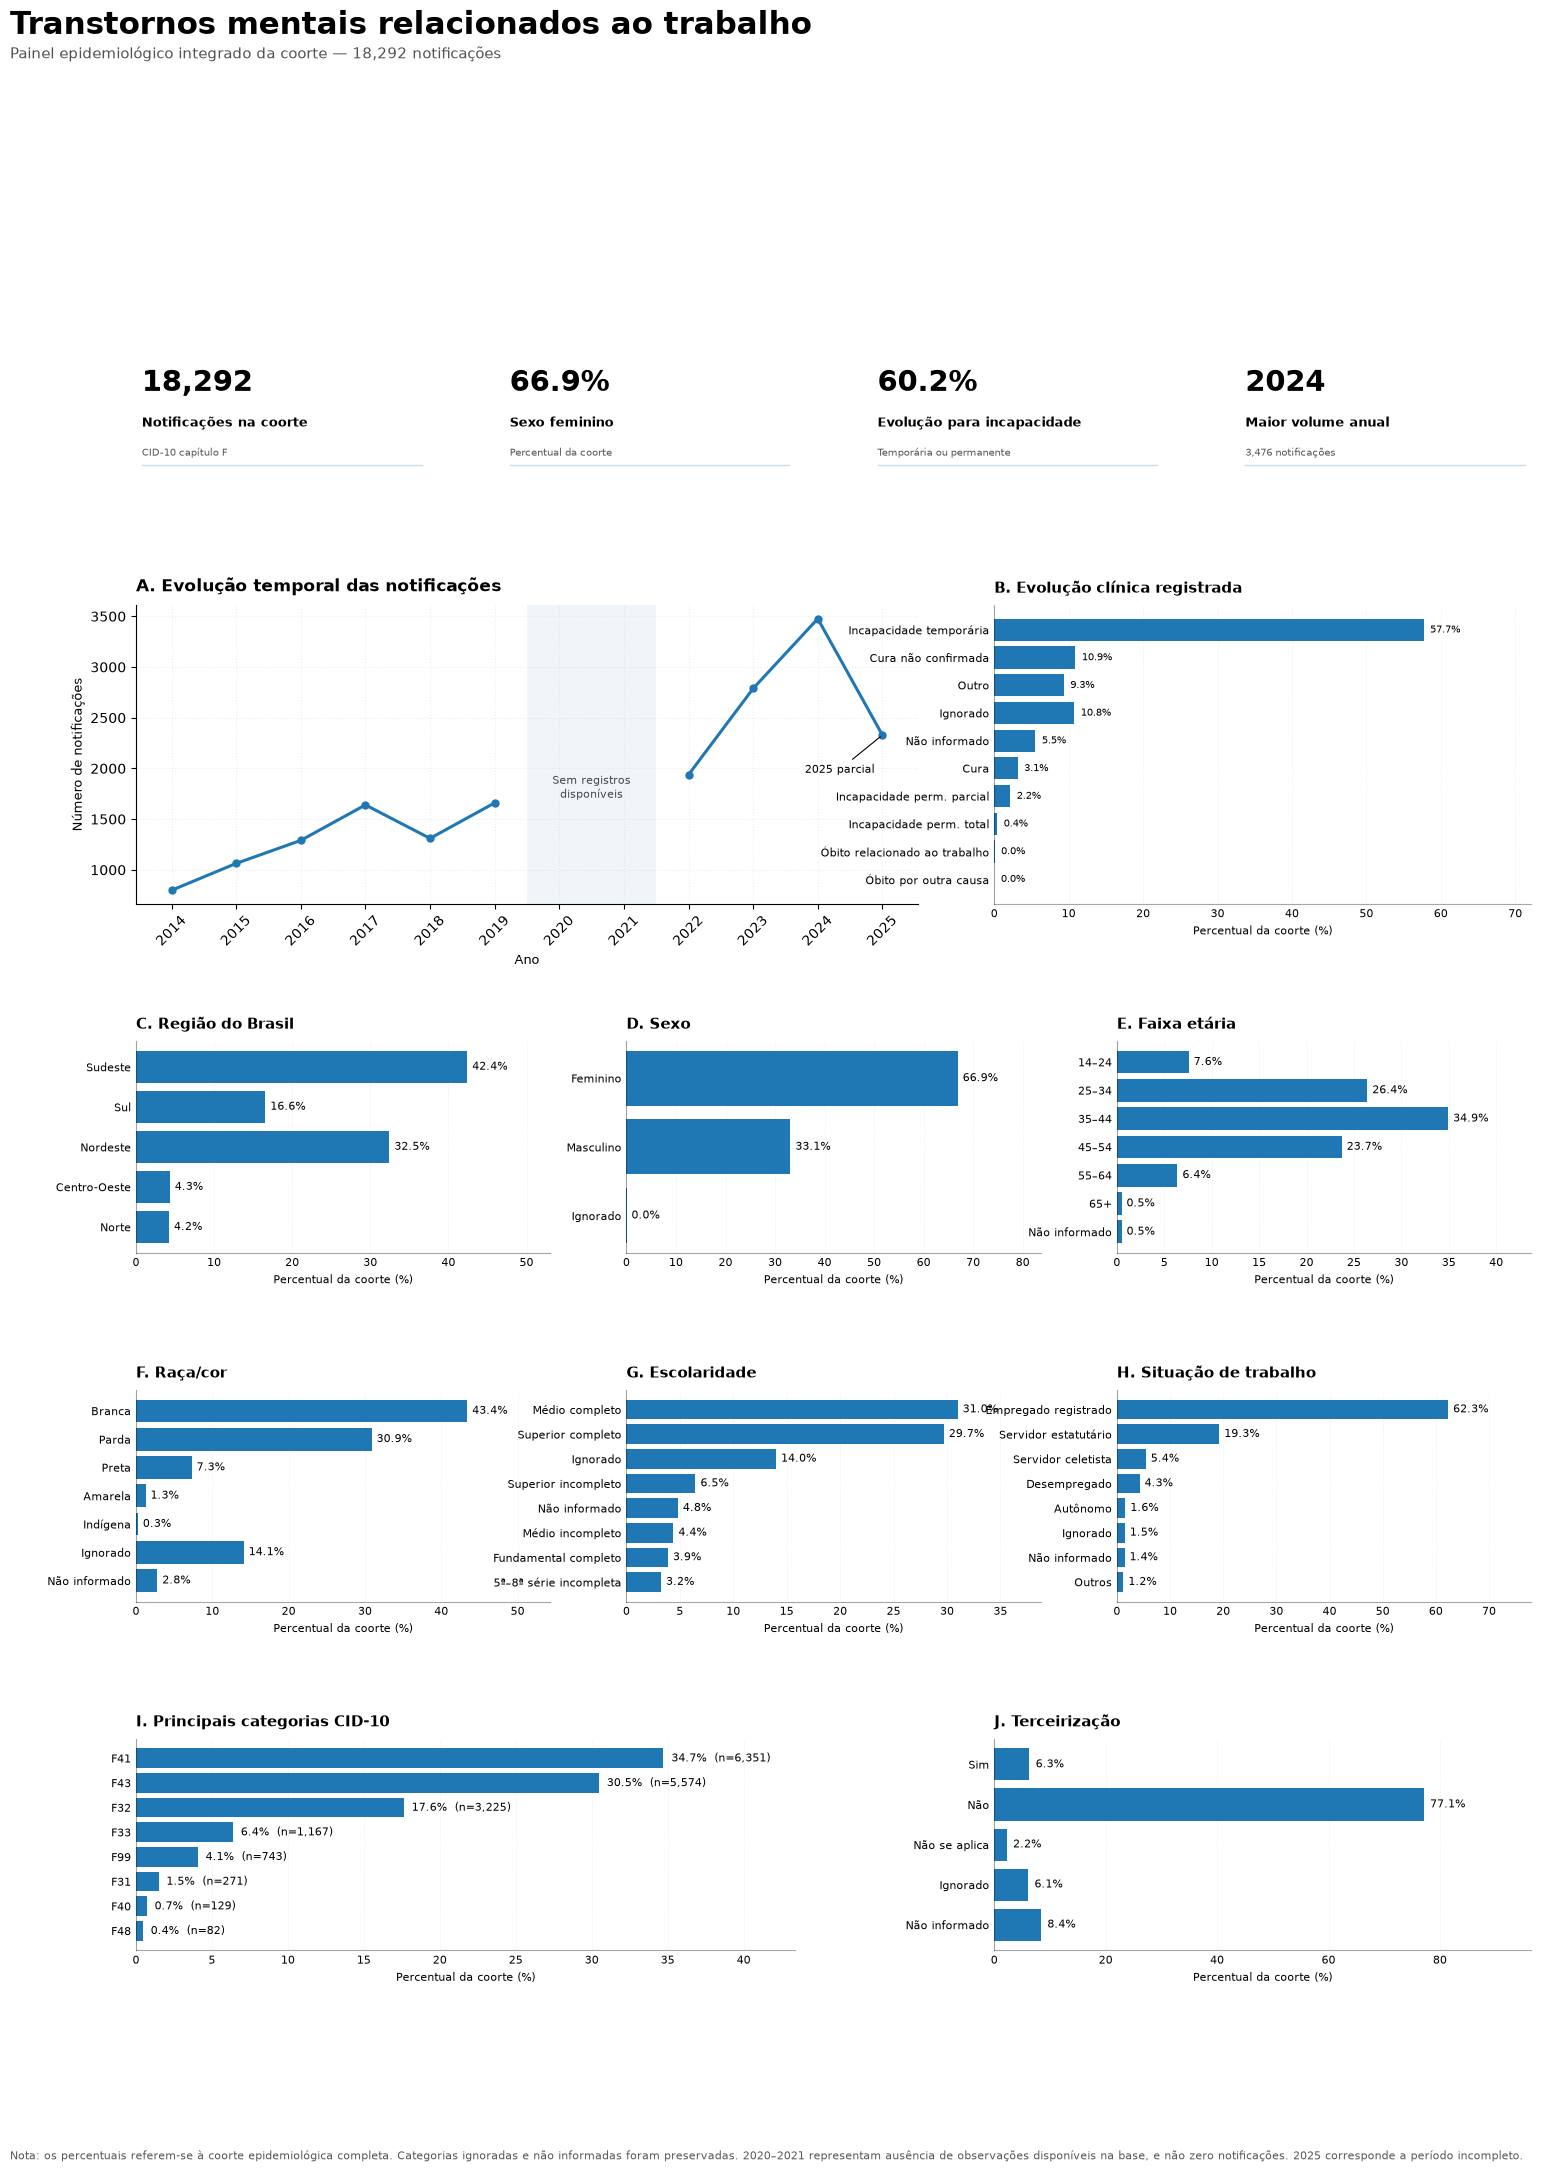

In [77]:
# ============================================================
# DASHBOARD EPIDEMIOLÓGICO INTEGRADO — VERSÃO EDITORIAL
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# ============================================================
# 1. BASE
# ============================================================

if 'df_analitico_completo' not in globals():
    raise NameError(
        "df_analitico_completo não existe no kernel."
    )

base = df_analitico_completo.copy()

N_TOTAL = len(base)

# ============================================================
# 2. FUNÇÕES AUXILIARES
# ============================================================

def limpar_codigo(serie):
    """
    Converte códigos numéricos/categóricos em strings padronizadas.
    Ex.: 1.0 -> '1'; 35.0 -> '35'
    """
    s = serie.astype('string').str.strip()

    s = (
        s
        .str.replace(r'\.0$', '', regex=True)
        .replace({
            '': pd.NA,
            'nan': pd.NA,
            'None': pd.NA,
            '<NA>': pd.NA
        })
    )

    return s


def tabela_percentual(
    serie,
    mapa=None,
    ordem=None,
    top=None
):
    s = serie.copy()

    if mapa is not None:
        s = s.map(mapa)

    s = s.astype('string').fillna('Não informado')

    tab = (
        s.value_counts(dropna=False)
        .rename_axis('categoria')
        .reset_index(name='N')
    )

    tab['PCT'] = 100 * tab['N'] / N_TOTAL

    if ordem is not None:
        ordem_dict = {
            categoria: i
            for i, categoria in enumerate(ordem)
        }

        tab['_ordem'] = (
            tab['categoria']
            .map(ordem_dict)
            .fillna(999)
        )

        tab = (
            tab
            .sort_values('_ordem')
            .drop(columns='_ordem')
        )

    if top is not None:
        tab = tab.head(top)

    return tab.reset_index(drop=True)


def estilo_eixo(ax):

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.spines['left'].set_alpha(0.35)
    ax.spines['bottom'].set_alpha(0.35)

    ax.tick_params(
        axis='both',
        labelsize=8,
        length=0
    )

    ax.grid(
        axis='x',
        linestyle=':',
        linewidth=0.7,
        alpha=0.22
    )

    ax.set_axisbelow(True)


def barras_percentuais(
    ax,
    tabela,
    titulo,
    mostrar_n=False,
    tamanho=8
):

    dados = tabela.copy()

    barras = ax.barh(
        dados['categoria'],
        dados['PCT']
    )

    ax.invert_yaxis()

    estilo_eixo(ax)

    ax.set_title(
        titulo,
        loc='left',
        fontsize=11,
        fontweight='bold',
        pad=9
    )

    ax.set_xlabel(
        'Percentual da coorte (%)',
        fontsize=8
    )

    maior = dados['PCT'].max()

    limite = max(
        maior * 1.25,
        5
    )

    ax.set_xlim(0, limite)

    for barra, (_, linha) in zip(
        barras,
        dados.iterrows()
    ):

        pct = linha['PCT']
        n = linha['N']

        if mostrar_n:

            texto = (
                f'{pct:.1f}%  '
                f'(n={n:,})'
            )

        else:

            texto = f'{pct:.1f}%'

        ax.text(
            barra.get_width() + limite * 0.012,
            barra.get_y() + barra.get_height()/2,
            texto,
            va='center',
            fontsize=tamanho
        )


def card_kpi(
    ax,
    valor,
    titulo,
    subtitulo=None
):

    ax.axis('off')

    ax.text(
        0.02,
        0.68,
        valor,
        transform=ax.transAxes,
        fontsize=21,
        fontweight='bold',
        va='center'
    )

    ax.text(
        0.02,
        0.36,
        titulo,
        transform=ax.transAxes,
        fontsize=9.5,
        fontweight='bold',
        va='center'
    )

    if subtitulo is not None:

        ax.text(
            0.02,
            0.12,
            subtitulo,
            transform=ax.transAxes,
            fontsize=7.5,
            alpha=0.65,
            va='center'
        )

    # linha discreta inferior
    ax.plot(
        [0.02, 0.98],
        [0.02, 0.02],
        transform=ax.transAxes,
        linewidth=1,
        alpha=0.25
    )


# ============================================================
# 3. EVOLUÇÃO
# ============================================================

evolucao_num = pd.to_numeric(
    base['EVOLUCAO'],
    errors='coerce'
)

mapa_evolucao = {
    1: 'Cura',
    2: 'Cura não confirmada',
    3: 'Incapacidade temporária',
    4: 'Incapacidade perm. parcial',
    5: 'Incapacidade perm. total',
    6: 'Óbito relacionado ao trabalho',
    7: 'Óbito por outra causa',
    8: 'Outro',
    9: 'Ignorado'
}

evolucao_label = (
    evolucao_num
    .map(mapa_evolucao)
    .fillna('Não informado')
)

ordem_evolucao = [
    'Incapacidade temporária',
    'Cura não confirmada',
    'Outro',
    'Ignorado',
    'Não informado',
    'Cura',
    'Incapacidade perm. parcial',
    'Incapacidade perm. total',
    'Óbito relacionado ao trabalho',
    'Óbito por outra causa'
]

tab_evolucao = tabela_percentual(
    evolucao_label,
    ordem=ordem_evolucao
)

# ============================================================
# 4. SEXO
# ============================================================

sexo_cod = limpar_codigo(base['CS_SEXO'])

mapa_sexo = {
    'F': 'Feminino',
    'M': 'Masculino',
    'I': 'Ignorado'
}

sexo_label = (
    sexo_cod
    .map(mapa_sexo)
    .fillna('Não informado')
)

tab_sexo = tabela_percentual(
    sexo_label,
    ordem=[
        'Feminino',
        'Masculino',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 5. RAÇA / COR
# ============================================================

raca_cod = limpar_codigo(base['CS_RACA'])

mapa_raca = {
    '1': 'Branca',
    '2': 'Preta',
    '3': 'Amarela',
    '4': 'Parda',
    '5': 'Indígena',
    '9': 'Ignorado'
}

raca_label = (
    raca_cod
    .map(mapa_raca)
    .fillna('Não informado')
)

tab_raca = tabela_percentual(
    raca_label,
    ordem=[
        'Branca',
        'Parda',
        'Preta',
        'Amarela',
        'Indígena',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 6. IDADE
# ============================================================

idade_cod = pd.to_numeric(
    base['NU_IDADE_N'],
    errors='coerce'
)

unidade = idade_cod // 1000
valor = idade_cod % 1000

idade_anos = pd.Series(
    np.where(
        unidade == 4,
        valor,
        np.nan
    ),
    index=base.index
)

# Idades implausíveis para análise ocupacional
idade_anos = idade_anos.mask(
    (idade_anos < 14) |
    (idade_anos > 100)
)

faixa_idade = pd.cut(
    idade_anos,
    bins=[
        13,
        24,
        34,
        44,
        54,
        64,
        np.inf
    ],
    labels=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+'
    ]
)

faixa_idade = (
    faixa_idade
    .astype('string')
    .fillna('Não informado')
)

tab_idade = tabela_percentual(
    faixa_idade,
    ordem=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+',
        'Não informado'
    ]
)

# ============================================================
# 7. ESCOLARIDADE
# ============================================================

esc_cod = limpar_codigo(base['CS_ESCOL_N'])

mapa_escolaridade = {
    '0': 'Analfabeto',
    '00': 'Analfabeto',
    '1': '1ª–4ª série incompleta',
    '01': '1ª–4ª série incompleta',
    '2': '4ª série completa',
    '02': '4ª série completa',
    '3': '5ª–8ª série incompleta',
    '03': '5ª–8ª série incompleta',
    '4': 'Fundamental completo',
    '04': 'Fundamental completo',
    '5': 'Médio incompleto',
    '05': 'Médio incompleto',
    '6': 'Médio completo',
    '06': 'Médio completo',
    '7': 'Superior incompleto',
    '07': 'Superior incompleto',
    '8': 'Superior completo',
    '08': 'Superior completo',
    '9': 'Ignorado',
    '09': 'Ignorado',
    '10': 'Não se aplica'
}

esc_label = (
    esc_cod
    .map(mapa_escolaridade)
    .fillna('Não informado')
)

tab_escolaridade = (
    tabela_percentual(esc_label)
    .sort_values(
        'N',
        ascending=False
    )
    .reset_index(drop=True)
)

# ============================================================
# 8. SITUAÇÃO DE TRABALHO
# ============================================================

sit_cod = limpar_codigo(base['SIT_TRAB'])

mapa_sit = {
    '1': 'Empregado registrado',
    '01': 'Empregado registrado',

    '2': 'Empregado não registrado',
    '02': 'Empregado não registrado',

    '3': 'Autônomo',
    '03': 'Autônomo',

    '4': 'Servidor estatutário',
    '04': 'Servidor estatutário',

    '5': 'Servidor celetista',
    '05': 'Servidor celetista',

    '6': 'Aposentado',
    '06': 'Aposentado',

    '7': 'Desempregado',
    '07': 'Desempregado',

    '8': 'Trabalho temporário',
    '08': 'Trabalho temporário',

    '9': 'Cooperativado',
    '09': 'Cooperativado',

    '10': 'Trabalhador avulso',
    '11': 'Empregador',
    '12': 'Outros',
    '99': 'Ignorado'
}

sit_label = (
    sit_cod
    .map(mapa_sit)
    .fillna('Não informado')
)

tab_sit = (
    tabela_percentual(sit_label)
    .sort_values(
        'N',
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

# ============================================================
# 9. TERCEIRIZAÇÃO
# ============================================================

terc_cod = limpar_codigo(
    base['TERCEIRIZA']
)

mapa_terc = {
    '1': 'Sim',
    '01': 'Sim',
    '2': 'Não',
    '02': 'Não',
    '3': 'Não se aplica',
    '03': 'Não se aplica',
    '9': 'Ignorado',
    '09': 'Ignorado'
}

terc_label = (
    terc_cod
    .map(mapa_terc)
    .fillna('Não informado')
)

tab_terc = tabela_percentual(
    terc_label,
    ordem=[
        'Sim',
        'Não',
        'Não se aplica',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 10. UF E REGIÃO — CORREÇÃO DO DASHBOARD ANTERIOR
# ============================================================

uf_cod = limpar_codigo(
    base['SG_UF']
).str.upper()

# Códigos IBGE de UF
codigo_uf = {
    '11': 'RO',
    '12': 'AC',
    '13': 'AM',
    '14': 'RR',
    '15': 'PA',
    '16': 'AP',
    '17': 'TO',

    '21': 'MA',
    '22': 'PI',
    '23': 'CE',
    '24': 'RN',
    '25': 'PB',
    '26': 'PE',
    '27': 'AL',
    '28': 'SE',
    '29': 'BA',

    '31': 'MG',
    '32': 'ES',
    '33': 'RJ',
    '35': 'SP',

    '41': 'PR',
    '42': 'SC',
    '43': 'RS',

    '50': 'MS',
    '51': 'MT',
    '52': 'GO',
    '53': 'DF'
}

# Aceita tanto código numérico quanto sigla
uf_tratada = uf_cod.map(
    lambda x:
    codigo_uf.get(x, x)
    if pd.notna(x)
    else pd.NA
)

mapa_regiao = {
    'AC': 'Norte',
    'AP': 'Norte',
    'AM': 'Norte',
    'PA': 'Norte',
    'RO': 'Norte',
    'RR': 'Norte',
    'TO': 'Norte',

    'AL': 'Nordeste',
    'BA': 'Nordeste',
    'CE': 'Nordeste',
    'MA': 'Nordeste',
    'PB': 'Nordeste',
    'PE': 'Nordeste',
    'PI': 'Nordeste',
    'RN': 'Nordeste',
    'SE': 'Nordeste',

    'DF': 'Centro-Oeste',
    'GO': 'Centro-Oeste',
    'MT': 'Centro-Oeste',
    'MS': 'Centro-Oeste',

    'ES': 'Sudeste',
    'MG': 'Sudeste',
    'RJ': 'Sudeste',
    'SP': 'Sudeste',

    'PR': 'Sul',
    'RS': 'Sul',
    'SC': 'Sul'
}

regiao = (
    uf_tratada
    .map(mapa_regiao)
    .fillna('Não informado')
)

tab_regiao = tabela_percentual(
    regiao,
    ordem=[
        'Sudeste',
        'Sul',
        'Nordeste',
        'Centro-Oeste',
        'Norte',
        'Não informado'
    ]
)

# ============================================================
# 11. CID-10
# ============================================================

cid = (
    base['CATEGORIA_CID']
    .astype('string')
    .fillna('Não informado')
)

tab_cid = (
    cid.value_counts()
    .head(8)
    .rename_axis('categoria')
    .reset_index(name='N')
)

tab_cid['PCT'] = (
    100 * tab_cid['N'] /
    N_TOTAL
)

# ============================================================
# 12. SÉRIE TEMPORAL
# ============================================================

anos = list(
    range(2014, 2026)
)

serie = (
    base
    .groupby('NU_ANO')
    .size()
    .reindex(anos)
    .astype(float)
)

# anos ausentes ≠ zero
serie.loc[2020] = np.nan
serie.loc[2021] = np.nan

# ============================================================
# 13. KPIs
# ============================================================

pct_mulheres = (
    100 *
    (sexo_label == 'Feminino').sum() /
    N_TOTAL
)

n_incapacidade = (
    evolucao_num
    .isin([3, 4, 5])
    .sum()
)

pct_incapacidade = (
    100 *
    n_incapacidade /
    N_TOTAL
)

cid_freq = (
    cid.value_counts()
)

cid_principal = cid_freq.index[0]
cid_principal_n = cid_freq.iloc[0]

cid_principal_pct = (
    100 *
    cid_principal_n /
    N_TOTAL
)

anos_hist = (
    base.loc[
        pd.to_numeric(
            base['NU_ANO'],
            errors='coerce'
        ) <= 2024
    ]
    .groupby('NU_ANO')
    .size()
)

ano_pico = int(
    anos_hist.idxmax()
)

n_pico = int(
    anos_hist.max()
)

# ============================================================
# 14. ARQUITETURA DA FIGURA
# ============================================================

fig = plt.figure(
    figsize=(18, 22)
)

gs = GridSpec(
    nrows=20,
    ncols=12,
    figure=fig,
    hspace=1.35,
    wspace=1.65
)

fig.suptitle(
    'Transtornos mentais relacionados ao trabalho',
    x=0.055,
    y=0.992,
    ha='left',
    fontsize=22,
    fontweight='bold'
)

fig.text(
    0.055,
    0.970,
    (
        'Painel epidemiológico integrado da coorte '
        f'— {N_TOTAL:,} notificações'
    ),
    fontsize=11,
    alpha=0.68,
    ha='left'
)

# ============================================================
# 15. CARDS
# ============================================================

ax_k1 = fig.add_subplot(
    gs[1:3, 0:3]
)

ax_k2 = fig.add_subplot(
    gs[1:3, 3:6]
)

ax_k3 = fig.add_subplot(
    gs[1:3, 6:9]
)

ax_k4 = fig.add_subplot(
    gs[1:3, 9:12]
)

card_kpi(
    ax_k1,
    f'{N_TOTAL:,}',
    'Notificações na coorte',
    'CID-10 capítulo F'
)

card_kpi(
    ax_k2,
    f'{pct_mulheres:.1f}%',
    'Sexo feminino',
    'Percentual da coorte'
)

card_kpi(
    ax_k3,
    f'{pct_incapacidade:.1f}%',
    'Evolução para incapacidade',
    'Temporária ou permanente'
)

card_kpi(
    ax_k4,
    f'{ano_pico}',
    'Maior volume anual',
    f'{n_pico:,} notificações'
)

# ============================================================
# 16. SÉRIE TEMPORAL — PAINEL PRINCIPAL
# ============================================================

ax1 = fig.add_subplot(
    gs[4:8, 0:7]
)

ax1.plot(
    anos,
    serie.values,
    marker='o',
    linewidth=2.2,
    markersize=5
)

ax1.set_title(
    'A. Evolução temporal das notificações',
    loc='left',
    fontsize=12,
    fontweight='bold',
    pad=10
)

ax1.set_ylabel(
    'Número de notificações',
    fontsize=9
)

ax1.set_xlabel(
    'Ano',
    fontsize=9
)

ax1.set_xticks(
    anos
)

ax1.tick_params(
    axis='x',
    rotation=45
)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

ax1.grid(
    linestyle=':',
    alpha=0.22
)

# lacuna real da série
ax1.axvspan(
    2019.5,
    2021.5,
    alpha=0.07
)

ax1.text(
    2020.5,
    np.nanmax(serie.values) * 0.52,
    'Sem registros\ndisponíveis',
    ha='center',
    va='center',
    fontsize=8,
    alpha=0.70
)

# 2025 parcial
if (
    2025 in serie.index and
    pd.notna(serie.loc[2025])
):

    ax1.annotate(
        '2025 parcial',
        xy=(
            2025,
            serie.loc[2025]
        ),
        xytext=(
            2023.8,
            serie.loc[2025] * 0.84
        ),
        fontsize=8,
        arrowprops={
            'arrowstyle': '-',
            'linewidth': 0.8
        }
    )

# ============================================================
# 17. EVOLUÇÃO
# ============================================================

ax2 = fig.add_subplot(
    gs[4:8, 7:12]
)

barras_percentuais(
    ax2,
    tab_evolucao,
    'B. Evolução clínica registrada',
    mostrar_n=False,
    tamanho=7.5
)

# ============================================================
# 18. REGIÃO
# ============================================================

ax3 = fig.add_subplot(
    gs[9:12, 0:4]
)

barras_percentuais(
    ax3,
    tab_regiao,
    'C. Região do Brasil'
)

# ============================================================
# 19. SEXO
# ============================================================

ax4 = fig.add_subplot(
    gs[9:12, 4:8]
)

barras_percentuais(
    ax4,
    tab_sexo,
    'D. Sexo'
)

# ============================================================
# 20. FAIXA ETÁRIA
# ============================================================

ax5 = fig.add_subplot(
    gs[9:12, 8:12]
)

barras_percentuais(
    ax5,
    tab_idade,
    'E. Faixa etária'
)

# ============================================================
# 21. RAÇA/COR
# ============================================================

ax6 = fig.add_subplot(
    gs[13:16, 0:4]
)

barras_percentuais(
    ax6,
    tab_raca,
    'F. Raça/cor'
)

# ============================================================
# 22. ESCOLARIDADE
# ============================================================

ax7 = fig.add_subplot(
    gs[13:16, 4:8]
)

barras_percentuais(
    ax7,
    tab_escolaridade.head(8),
    'G. Escolaridade'
)

# ============================================================
# 23. SITUAÇÃO DE TRABALHO
# ============================================================

ax8 = fig.add_subplot(
    gs[13:16, 8:12]
)

barras_percentuais(
    ax8,
    tab_sit,
    'H. Situação de trabalho'
)

# ============================================================
# 24. PRINCIPAIS CIDs
# ============================================================

ax9 = fig.add_subplot(
    gs[17:20, 0:6]
)

barras_percentuais(
    ax9,
    tab_cid,
    'I. Principais categorias CID-10',
    mostrar_n=True
)

# ============================================================
# 25. TERCEIRIZAÇÃO
# ============================================================

ax10 = fig.add_subplot(
    gs[17:20, 7:12]
)

barras_percentuais(
    ax10,
    tab_terc,
    'J. Terceirização'
)

# ============================================================
# 26. NOTAS
# ============================================================

fig.text(
    0.055,
    0.015,
    (
        'Nota: os percentuais referem-se à coorte epidemiológica completa. '
        'Categorias ignoradas e não informadas foram preservadas. '
        '2020–2021 representam ausência de observações disponíveis na base, '
        'e não zero notificações. 2025 corresponde a período incompleto.'
    ),
    ha='left',
    fontsize=8,
    alpha=0.65
)

plt.show()

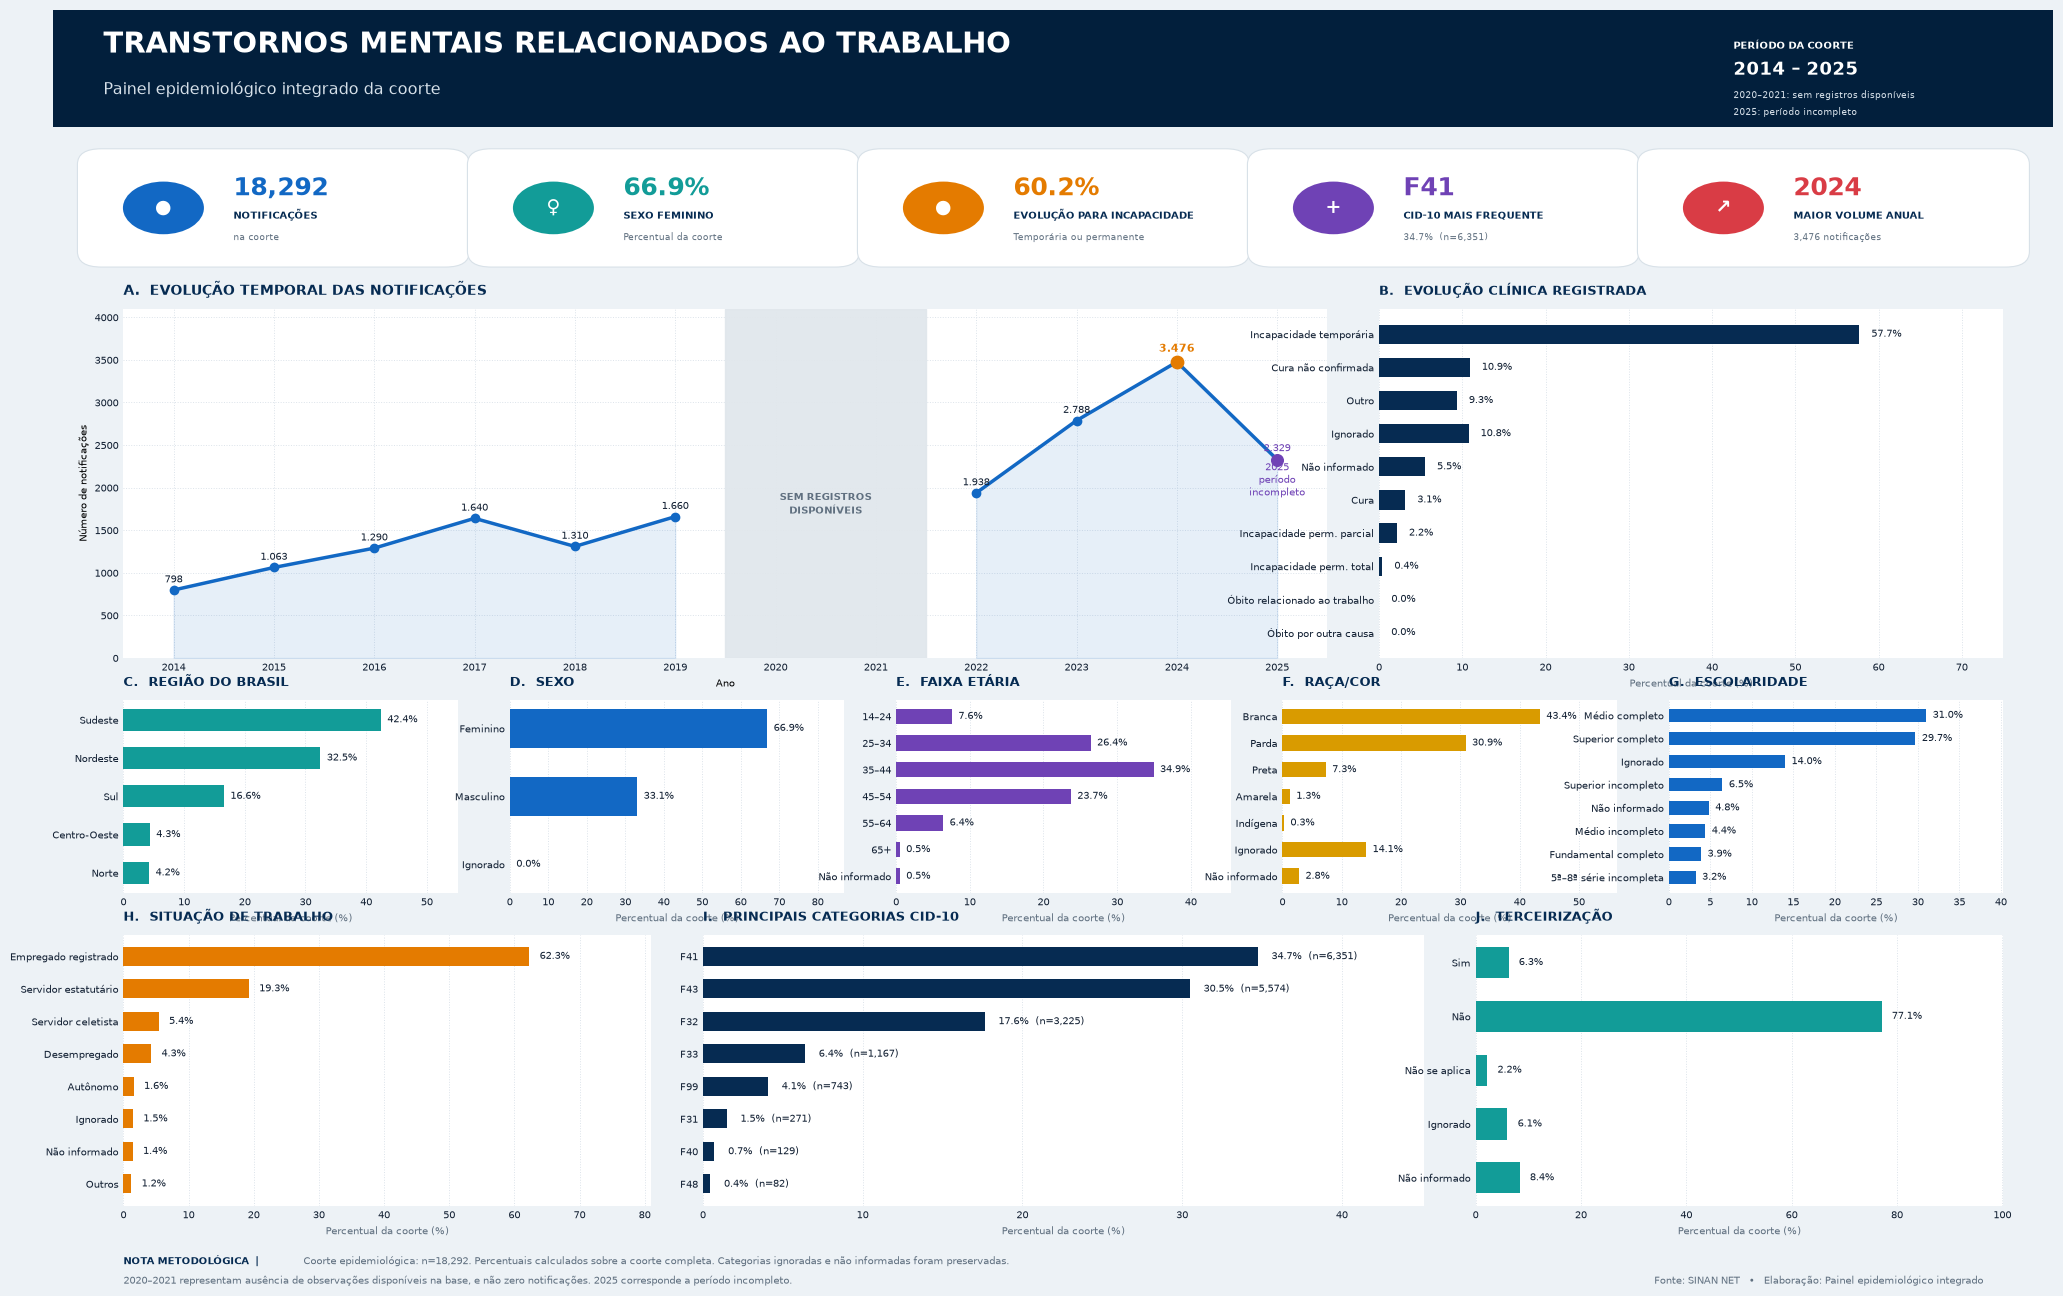


Arquivo salvo: dashboard_epidemiologico_infografico.png


In [79]:
# ============================================================
# DASHBOARD EXECUTIVO — ESTILO INFOGRÁFICO
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch, Circle

# ============================================================
# 0. BASE
# ============================================================

if 'df_analitico_completo' not in globals():
    raise NameError(
        "df_analitico_completo não existe no kernel."
    )

base = df_analitico_completo.copy()
N_TOTAL = len(base)

# ============================================================
# 1. PALETA
# ============================================================

NAVY = '#062B52'
NAVY_DARK = '#021F3C'
BLUE = '#1268C4'
TEAL = '#129C98'
PURPLE = '#6F42B5'
ORANGE = '#E47B00'
GOLD = '#D99B00'
RED = '#D93C45'

BG = '#EDF2F6'
WHITE = '#FFFFFF'
TEXT = '#122033'
MUTED = '#607080'
GRID = '#DCE3EA'
BORDER = '#D8E1E8'

# ============================================================
# 2. FUNÇÕES
# ============================================================

def limpar_codigo(serie):
    s = serie.astype('string').str.strip()

    s = s.str.replace(
        r'\.0$',
        '',
        regex=True
    )

    return s.replace({
        '': pd.NA,
        'nan': pd.NA,
        'None': pd.NA,
        '<NA>': pd.NA
    })


def tabela_pct(serie, ordem=None, top=None):

    s = (
        serie.astype('string')
        .fillna('Não informado')
    )

    tab = (
        s.value_counts(dropna=False)
        .rename_axis('categoria')
        .reset_index(name='N')
    )

    tab['PCT'] = (
        100 * tab['N'] / N_TOTAL
    )

    if ordem is not None:

        ordem_map = {
            categoria: i
            for i, categoria in enumerate(ordem)
        }

        tab['_ordem'] = (
            tab['categoria']
            .map(ordem_map)
            .fillna(999)
        )

        tab = (
            tab
            .sort_values('_ordem')
            .drop(columns='_ordem')
        )

    if top is not None:
        tab = tab.head(top)

    return tab.reset_index(drop=True)


def configurar_eixo(ax):

    ax.set_facecolor(WHITE)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(
        axis='both',
        labelsize=7.3,
        colors=TEXT,
        length=0
    )

    ax.grid(
        axis='x',
        linestyle=':',
        color=GRID,
        linewidth=0.7
    )

    ax.set_axisbelow(True)


def barras(
    ax,
    tab,
    titulo,
    letra,
    cor,
    mostrar_n=False,
    tamanho=7.0
):

    configurar_eixo(ax)

    ax.set_title(
        f'{letra}.  {titulo.upper()}',
        loc='left',
        fontsize=9.3,
        fontweight='bold',
        color=NAVY,
        pad=10
    )

    bars = ax.barh(
        tab['categoria'],
        tab['PCT'],
        color=cor,
        height=0.58
    )

    ax.invert_yaxis()

    maior = max(tab['PCT'].max(), 1)

    ax.set_xlim(
        0,
        maior * 1.30
    )

    ax.set_xlabel(
        'Percentual da coorte (%)',
        fontsize=7.2,
        color=MUTED
    )

    for bar, (_, row) in zip(
        bars,
        tab.iterrows()
    ):

        if mostrar_n:

            txt = (
                f"{row['PCT']:.1f}%  "
                f"(n={row['N']:,})"
            )

        else:

            txt = f"{row['PCT']:.1f}%"

        ax.text(
            bar.get_width() + maior * 0.025,
            bar.get_y() + bar.get_height()/2,
            txt,
            va='center',
            fontsize=tamanho,
            color=TEXT
        )


def desenhar_card(
    fig,
    x,
    y,
    w,
    h,
    cor,
    valor,
    titulo,
    subtitulo,
    simbolo='●'
):

    # card
    card = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle='round,pad=0.008,rounding_size=0.012',
        transform=fig.transFigure,
        facecolor=WHITE,
        edgecolor=BORDER,
        linewidth=0.8
    )

    fig.patches.append(card)

    # círculo
    cx = x + 0.035
    cy = y + h/2

    circulo = Circle(
        (cx, cy),
        radius=h * 0.27,
        transform=fig.transFigure,
        facecolor=cor,
        edgecolor='none'
    )

    fig.patches.append(circulo)

    fig.text(
        cx,
        cy,
        simbolo,
        ha='center',
        va='center',
        fontsize=14,
        color='white',
        fontweight='bold'
    )

    fig.text(
        x + 0.07,
        y + h * 0.63,
        valor,
        fontsize=18,
        fontweight='bold',
        color=cor,
        ha='left'
    )

    fig.text(
        x + 0.07,
        y + h * 0.39,
        titulo.upper(),
        fontsize=7.5,
        fontweight='bold',
        color=NAVY,
        ha='left'
    )

    fig.text(
        x + 0.07,
        y + h * 0.17,
        subtitulo,
        fontsize=6.7,
        color=MUTED,
        ha='left'
    )


# ============================================================
# 3. EVOLUÇÃO
# ============================================================

evolucao = pd.to_numeric(
    base['EVOLUCAO'],
    errors='coerce'
)

mapa_evolucao = {
    1: 'Cura',
    2: 'Cura não confirmada',
    3: 'Incapacidade temporária',
    4: 'Incapacidade perm. parcial',
    5: 'Incapacidade perm. total',
    6: 'Óbito relacionado ao trabalho',
    7: 'Óbito por outra causa',
    8: 'Outro',
    9: 'Ignorado'
}

evolucao_label = (
    evolucao
    .map(mapa_evolucao)
    .fillna('Não informado')
)

tab_evolucao = tabela_pct(
    evolucao_label,
    ordem=[
        'Incapacidade temporária',
        'Cura não confirmada',
        'Outro',
        'Ignorado',
        'Não informado',
        'Cura',
        'Incapacidade perm. parcial',
        'Incapacidade perm. total',
        'Óbito relacionado ao trabalho',
        'Óbito por outra causa'
    ]
)

# ============================================================
# 4. SEXO
# ============================================================

sexo = (
    limpar_codigo(base['CS_SEXO'])
    .str.upper()
)

sexo_label = (
    sexo.map({
        'F': 'Feminino',
        'M': 'Masculino',
        'I': 'Ignorado'
    })
    .fillna('Não informado')
)

tab_sexo = tabela_pct(
    sexo_label,
    ordem=[
        'Feminino',
        'Masculino',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 5. RAÇA/COR
# ============================================================

raca = limpar_codigo(base['CS_RACA'])

raca_label = (
    raca.map({
        '1': 'Branca',
        '2': 'Preta',
        '3': 'Amarela',
        '4': 'Parda',
        '5': 'Indígena',
        '9': 'Ignorado'
    })
    .fillna('Não informado')
)

tab_raca = tabela_pct(
    raca_label,
    ordem=[
        'Branca',
        'Parda',
        'Preta',
        'Amarela',
        'Indígena',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 6. IDADE
# ============================================================

idade_cod = pd.to_numeric(
    base['NU_IDADE_N'],
    errors='coerce'
)

unidade = idade_cod // 1000
valor = idade_cod % 1000

idade_anos = pd.Series(
    np.where(
        unidade == 4,
        valor,
        np.nan
    ),
    index=base.index
)

idade_anos = idade_anos.mask(
    (idade_anos < 14) |
    (idade_anos > 100)
)

faixa_idade = pd.cut(
    idade_anos,
    bins=[13, 24, 34, 44, 54, 64, np.inf],
    labels=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+'
    ]
)

faixa_idade = (
    faixa_idade
    .astype('string')
    .fillna('Não informado')
)

tab_idade = tabela_pct(
    faixa_idade,
    ordem=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+',
        'Não informado'
    ]
)

# ============================================================
# 7. ESCOLARIDADE
# ============================================================

esc = limpar_codigo(base['CS_ESCOL_N'])

esc_label = (
    esc.map({
        '0': 'Analfabeto',
        '00': 'Analfabeto',
        '1': '1ª–4ª série incompleta',
        '01': '1ª–4ª série incompleta',
        '2': '4ª série completa',
        '02': '4ª série completa',
        '3': '5ª–8ª série incompleta',
        '03': '5ª–8ª série incompleta',
        '4': 'Fundamental completo',
        '04': 'Fundamental completo',
        '5': 'Médio incompleto',
        '05': 'Médio incompleto',
        '6': 'Médio completo',
        '06': 'Médio completo',
        '7': 'Superior incompleto',
        '07': 'Superior incompleto',
        '8': 'Superior completo',
        '08': 'Superior completo',
        '9': 'Ignorado',
        '09': 'Ignorado',
        '10': 'Não se aplica'
    })
    .fillna('Não informado')
)

tab_esc = (
    tabela_pct(esc_label)
    .sort_values(
        'N',
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

# ============================================================
# 8. SITUAÇÃO DE TRABALHO
# ============================================================

sit = limpar_codigo(base['SIT_TRAB'])

sit_label = (
    sit.map({
        '1': 'Empregado registrado',
        '01': 'Empregado registrado',
        '2': 'Empregado não registrado',
        '02': 'Empregado não registrado',
        '3': 'Autônomo',
        '03': 'Autônomo',
        '4': 'Servidor estatutário',
        '04': 'Servidor estatutário',
        '5': 'Servidor celetista',
        '05': 'Servidor celetista',
        '6': 'Aposentado',
        '06': 'Aposentado',
        '7': 'Desempregado',
        '07': 'Desempregado',
        '8': 'Trabalho temporário',
        '08': 'Trabalho temporário',
        '9': 'Cooperativado',
        '09': 'Cooperativado',
        '10': 'Trabalhador avulso',
        '11': 'Empregador',
        '12': 'Outros',
        '99': 'Ignorado'
    })
    .fillna('Não informado')
)

tab_sit = (
    tabela_pct(sit_label)
    .sort_values(
        'N',
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

# ============================================================
# 9. TERCEIRIZAÇÃO
# ============================================================

terc = limpar_codigo(base['TERCEIRIZA'])

terc_label = (
    terc.map({
        '1': 'Sim',
        '01': 'Sim',
        '2': 'Não',
        '02': 'Não',
        '3': 'Não se aplica',
        '03': 'Não se aplica',
        '9': 'Ignorado',
        '09': 'Ignorado'
    })
    .fillna('Não informado')
)

tab_terc = tabela_pct(
    terc_label,
    ordem=[
        'Sim',
        'Não',
        'Não se aplica',
        'Ignorado',
        'Não informado'
    ]
)

# ============================================================
# 10. REGIÃO
# ============================================================

uf_raw = (
    limpar_codigo(base['SG_UF'])
    .str.upper()
)

codigo_uf = {
    '11':'RO','12':'AC','13':'AM','14':'RR','15':'PA','16':'AP','17':'TO',
    '21':'MA','22':'PI','23':'CE','24':'RN','25':'PB','26':'PE','27':'AL',
    '28':'SE','29':'BA','31':'MG','32':'ES','33':'RJ','35':'SP',
    '41':'PR','42':'SC','43':'RS','50':'MS','51':'MT','52':'GO','53':'DF'
}

uf = uf_raw.map(
    lambda x:
    codigo_uf.get(x, x)
    if pd.notna(x)
    else pd.NA
)

mapa_regiao = {
    'AC':'Norte','AP':'Norte','AM':'Norte','PA':'Norte',
    'RO':'Norte','RR':'Norte','TO':'Norte',

    'AL':'Nordeste','BA':'Nordeste','CE':'Nordeste',
    'MA':'Nordeste','PB':'Nordeste','PE':'Nordeste',
    'PI':'Nordeste','RN':'Nordeste','SE':'Nordeste',

    'DF':'Centro-Oeste','GO':'Centro-Oeste',
    'MT':'Centro-Oeste','MS':'Centro-Oeste',

    'ES':'Sudeste','MG':'Sudeste',
    'RJ':'Sudeste','SP':'Sudeste',

    'PR':'Sul','RS':'Sul','SC':'Sul'
}

regiao_label = (
    uf.map(mapa_regiao)
    .fillna('Não informado')
)

tab_regiao = tabela_pct(
    regiao_label,
    ordem=[
        'Sudeste',
        'Nordeste',
        'Sul',
        'Centro-Oeste',
        'Norte',
        'Não informado'
    ]
)

# ============================================================
# 11. CID
# ============================================================

cid = (
    base['CATEGORIA_CID']
    .astype('string')
    .fillna('Não informado')
)

tab_cid = (
    cid.value_counts()
    .head(8)
    .rename_axis('categoria')
    .reset_index(name='N')
)

tab_cid['PCT'] = (
    100 * tab_cid['N'] /
    N_TOTAL
)

# ============================================================
# 12. TEMPORAL
# ============================================================

anos = list(range(2014, 2026))

serie = (
    base.assign(
        _ANO=pd.to_numeric(
            base['NU_ANO'],
            errors='coerce'
        )
    )
    .groupby('_ANO')
    .size()
    .reindex(anos)
    .astype(float)
)

serie.loc[2020] = np.nan
serie.loc[2021] = np.nan

# ============================================================
# 13. KPIs
# ============================================================

pct_fem = (
    100 *
    (sexo_label == 'Feminino').sum() /
    N_TOTAL
)

n_incap = evolucao.isin(
    [3,4,5]
).sum()

pct_incap = (
    100 *
    n_incap /
    N_TOTAL
)

cid_freq = cid.value_counts()

cid_top = cid_freq.index[0]
cid_top_n = cid_freq.iloc[0]

cid_top_pct = (
    100 *
    cid_top_n /
    N_TOTAL
)

serie_hist = (
    serie.loc[
        serie.index <= 2024
    ]
    .dropna()
)

ano_pico = int(
    serie_hist.idxmax()
)

n_pico = int(
    serie_hist.max()
)

# ============================================================
# 14. FIGURA — FORMATO LANDSCAPE EXECUTIVO
# ============================================================

fig = plt.figure(
    figsize=(20, 13),
    facecolor=BG
)

# ============================================================
# 15. HEADER AZUL-MARINHO
# ============================================================

header = FancyBboxPatch(
    (0, 0.91),
    1,
    0.09,
    boxstyle='square,pad=0',
    transform=fig.transFigure,
    facecolor=NAVY_DARK,
    edgecolor='none'
)

fig.patches.append(header)

fig.text(
    0.025,
    0.967,
    'TRANSTORNOS MENTAIS RELACIONADOS AO TRABALHO',
    fontsize=21,
    fontweight='bold',
    color='white',
    ha='left'
)

fig.text(
    0.025,
    0.935,
    'Painel epidemiológico integrado da coorte',
    fontsize=11.5,
    color='#D7E1EA',
    ha='left'
)

fig.text(
    0.84,
    0.970,
    'PERÍODO DA COORTE',
    fontsize=7,
    color='white',
    fontweight='bold'
)

fig.text(
    0.84,
    0.950,
    '2014 – 2025',
    fontsize=13,
    color='white',
    fontweight='bold'
)

fig.text(
    0.84,
    0.932,
    '2020–2021: sem registros disponíveis',
    fontsize=6.8,
    color='#D7E1EA'
)

fig.text(
    0.84,
    0.919,
    '2025: período incompleto',
    fontsize=6.8,
    color='#D7E1EA'
)

# ============================================================
# 16. CARDS KPI
# ============================================================

card_y = 0.81
card_h = 0.075
card_w = 0.18

xs = [
    0.02,
    0.215,
    0.410,
    0.605,
    0.800
]

desenhar_card(
    fig,
    xs[0],
    card_y,
    card_w,
    card_h,
    BLUE,
    f'{N_TOTAL:,}',
    'Notificações',
    'na coorte',
    '●'
)

desenhar_card(
    fig,
    xs[1],
    card_y,
    card_w,
    card_h,
    TEAL,
    f'{pct_fem:.1f}%',
    'Sexo feminino',
    'Percentual da coorte',
    '♀'
)

desenhar_card(
    fig,
    xs[2],
    card_y,
    card_w,
    card_h,
    ORANGE,
    f'{pct_incap:.1f}%',
    'Evolução para incapacidade',
    'Temporária ou permanente',
    '●'
)

desenhar_card(
    fig,
    xs[3],
    card_y,
    card_w,
    card_h,
    PURPLE,
    str(cid_top),
    'CID-10 mais frequente',
    f'{cid_top_pct:.1f}%  (n={cid_top_n:,})',
    '+'
)

desenhar_card(
    fig,
    xs[4],
    card_y,
    card_w,
    card_h,
    RED,
    str(ano_pico),
    'Maior volume anual',
    f'{n_pico:,} notificações',
    '↗'
)

# ============================================================
# 17. GRID DOS GRÁFICOS
# ============================================================

gs = GridSpec(
    12,
    20,
    figure=fig,
    left=0.035,
    right=0.975,
    bottom=0.08,
    top=0.77,
    hspace=1.15,
    wspace=1.15
)

# ============================================================
# A. TEMPORAL
# ============================================================

ax1 = fig.add_subplot(
    gs[0:5, 0:13]
)

configurar_eixo(ax1)

ax1.set_title(
    'A.  EVOLUÇÃO TEMPORAL DAS NOTIFICAÇÕES',
    loc='left',
    fontsize=10,
    fontweight='bold',
    color=NAVY,
    pad=10
)

pre = serie.loc[2014:2019].dropna()
pos = serie.loc[2022:2025].dropna()

ax1.fill_between(
    pre.index,
    pre.values,
    0,
    color=BLUE,
    alpha=0.10
)

ax1.fill_between(
    pos.index,
    pos.values,
    0,
    color=BLUE,
    alpha=0.10
)

ax1.plot(
    pre.index,
    pre.values,
    color=BLUE,
    linewidth=2.5,
    marker='o',
    markersize=6
)

ax1.plot(
    pos.index,
    pos.values,
    color=BLUE,
    linewidth=2.5,
    marker='o',
    markersize=6
)

ax1.axvspan(
    2019.5,
    2021.5,
    color='#E1E7EC',
    alpha=0.95
)

ax1.text(
    2020.5,
    np.nanmax(serie.values)*0.52,
    'SEM REGISTROS\nDISPONÍVEIS',
    ha='center',
    va='center',
    fontsize=7.5,
    color=MUTED,
    fontweight='bold'
)

for ano, valor in pre.items():

    ax1.text(
        ano,
        valor + 90,
        f'{int(valor):,}'.replace(',', '.'),
        ha='center',
        fontsize=7.5,
        color=TEXT
    )

for ano, valor in pos.items():

    if ano not in [2024, 2025]:

        ax1.text(
            ano,
            valor + 90,
            f'{int(valor):,}'.replace(',', '.'),
            ha='center',
            fontsize=7.5,
            color=TEXT
        )

# 2024
v24 = serie.loc[2024]

ax1.scatter(
    2024,
    v24,
    s=80,
    color=ORANGE,
    zorder=5
)

ax1.text(
    2024,
    v24 + 120,
    f'{int(v24):,}'.replace(',', '.'),
    ha='center',
    fontsize=8,
    color=ORANGE,
    fontweight='bold'
)

# 2025
v25 = serie.loc[2025]

ax1.scatter(
    2025,
    v25,
    s=70,
    color=PURPLE,
    zorder=5
)

ax1.text(
    2025,
    v25 + 100,
    f'{int(v25):,}'.replace(',', '.'),
    ha='center',
    fontsize=7.5,
    color=PURPLE
)

ax1.text(
    2025,
    v25 - 420,
    '2025\nperíodo\nincompleto',
    ha='center',
    fontsize=7.5,
    color=PURPLE
)

ax1.set_xticks(anos)

ax1.set_xlim(
    2013.5,
    2025.5
)

ax1.set_ylim(
    0,
    np.nanmax(serie.values)*1.18
)

ax1.set_ylabel(
    'Número de notificações',
    fontsize=7.5
)

ax1.set_xlabel(
    'Ano',
    fontsize=7.5
)

ax1.grid(
    axis='y',
    color=GRID,
    linestyle=':',
    linewidth=0.7
)

# ============================================================
# B. EVOLUÇÃO
# ============================================================

ax2 = fig.add_subplot(
    gs[0:5, 13:20]
)

barras(
    ax2,
    tab_evolucao,
    'Evolução clínica registrada',
    'B',
    NAVY
)

# ============================================================
# C. REGIÃO
# ============================================================

ax3 = fig.add_subplot(
    gs[5:8, 0:4]
)

barras(
    ax3,
    tab_regiao,
    'Região do Brasil',
    'C',
    TEAL
)

# ============================================================
# D. SEXO
# ============================================================

ax4 = fig.add_subplot(
    gs[5:8, 4:8]
)

barras(
    ax4,
    tab_sexo,
    'Sexo',
    'D',
    BLUE
)

# ============================================================
# E. IDADE
# ============================================================

ax5 = fig.add_subplot(
    gs[5:8, 8:12]
)

barras(
    ax5,
    tab_idade,
    'Faixa etária',
    'E',
    PURPLE
)

# ============================================================
# F. RAÇA/COR
# ============================================================

ax6 = fig.add_subplot(
    gs[5:8, 12:16]
)

barras(
    ax6,
    tab_raca,
    'Raça/cor',
    'F',
    GOLD
)

# ============================================================
# G. ESCOLARIDADE
# ============================================================

ax7 = fig.add_subplot(
    gs[5:8, 16:20]
)

barras(
    ax7,
    tab_esc,
    'Escolaridade',
    'G',
    BLUE
)

# ============================================================
# H. SITUAÇÃO DE TRABALHO
# ============================================================

ax8 = fig.add_subplot(
    gs[8:12, 0:6]
)

barras(
    ax8,
    tab_sit,
    'Situação de trabalho',
    'H',
    ORANGE
)

# ============================================================
# I. CID
# ============================================================

ax9 = fig.add_subplot(
    gs[8:12, 6:14]
)

barras(
    ax9,
    tab_cid,
    'Principais categorias CID-10',
    'I',
    NAVY,
    mostrar_n=True
)

# ============================================================
# J. TERCEIRIZAÇÃO
# ============================================================

ax10 = fig.add_subplot(
    gs[8:12, 14:20]
)

barras(
    ax10,
    tab_terc,
    'Terceirização',
    'J',
    TEAL
)

# ============================================================
# 18. RODAPÉ
# ============================================================

fig.text(
    0.035,
    0.035,
    'NOTA METODOLÓGICA  |  ',
    fontsize=7.2,
    fontweight='bold',
    color=NAVY
)

fig.text(
    0.125,
    0.035,
    (
        f'Coorte epidemiológica: n={N_TOTAL:,}. '
        'Percentuais calculados sobre a coorte completa. '
        'Categorias ignoradas e não informadas foram preservadas.'
    ),
    fontsize=7.0,
    color=MUTED
)

fig.text(
    0.035,
    0.020,
    (
        '2020–2021 representam ausência de observações disponíveis na base, '
        'e não zero notificações. 2025 corresponde a período incompleto.'
    ),
    fontsize=7.0,
    color=MUTED
)

fig.text(
    0.965,
    0.020,
    'Fonte: SINAN NET   •   Elaboração: Painel epidemiológico integrado',
    fontsize=7.0,
    color=MUTED,
    ha='right'
)

# ============================================================
# 19. SALVAR
# ============================================================

plt.savefig(
    'dashboard_epidemiologico_infografico.png',
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()

print(
    '\nArquivo salvo: dashboard_epidemiologico_infografico.png'
)

Este bloco cria um gráfico de área para visualizar a evolução temporal do número total de casos de transtornos mentais relacionados ao trabalho notificados por ano. Ele agrupa os dados por ano, conta o número de casos e plota uma área preenchida e uma linha com marcadores. Também destaca o período da pandemia de COVID-19 como uma faixa de subnotificação e adiciona rótulos com os valores exatos de casos por ano. A figura é salva em formato PNG.

In [81]:
df_epi.info()

<class 'pandas.DataFrame'>
RangeIndex: 18292 entries, 0 to 18291
Data columns (total 68 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   TP_NOT         18292 non-null  str   
 1   ID_AGRAVO      18292 non-null  str   
 2   DT_NOTIFIC     18292 non-null  str   
 3   SEM_NOT        18292 non-null  str   
 4   NU_ANO         18292 non-null  str   
 5   SG_UF_NOT      18292 non-null  str   
 6   ID_MUNICIP     18292 non-null  str   
 7   ID_REGIONA     18292 non-null  str   
 8   ID_UNIDADE     18292 non-null  str   
 9   DT_DIAG        18292 non-null  str   
 10  SEM_DIAG       18292 non-null  str   
 11  NU_IDADE_N     18292 non-null  str   
 12  CS_SEXO        18292 non-null  str   
 13  CS_GESTANT     18292 non-null  str   
 14  CS_RACA        18292 non-null  str   
 15  CS_ESCOL_N     18292 non-null  str   
 16  SG_UF          18292 non-null  str   
 17  ID_MN_RESI     18292 non-null  str   
 18  ID_RG_RESI     18292 non-null  str   

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CASOS POR ANO
# ============================================================

casos_ano = (
    df_epi.groupby('NU_ANO')
      .size()
      .reset_index(name='casos')
      .sort_values('NU_ANO')
)

# ============================================================
# FIGURA
# ============================================================

fig, ax = plt.subplots(figsize=(12,6))

# Área preenchida
ax.fill_between(
    casos_ano['NU_ANO'],
    casos_ano['casos'],
    alpha=0.25,
    label='Área sob curva'
)

# Linha principal
ax.plot(
    casos_ano['NU_ANO'],
    casos_ano['casos'],
    linewidth=2.5,
    color='#2c3e50'
)

# Pontos
ax.scatter(
    casos_ano['NU_ANO'],
    casos_ano['casos'],
    s=60,
    edgecolor='white',
    linewidth=1.2,
    color='#e74c3c',
    zorder=3,
    label='Casos notificados'
)

# Valores sobre os pontos
for x, y in zip(casos_ano['NU_ANO'], casos_ano['casos']):
    ax.text(
        x,
        y + 80,
        f'{y:,}'.replace(',', '.'),
        ha='center',
        fontsize=9,
        fontweight='bold'
    )

# Faixa COVID
ax.axvspan(
    2020,
    2021.5,
    alpha=0.15,
    color='gray'
)

ax.text(
    2020.75,
    max(casos_ano['casos']) * 0.73,
    'Período de subnotificação\n(pandemia COVID-19)',
    ha='center',
    fontsize=9,
    style='italic',
    color='gray'
)

# Títulos
ax.set_title(
    'Evolução temporal das notificações de transtornos mentais relacionados ao trabalho\nBrasil (2014–2024)',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Ano', fontsize=11)
ax.set_ylabel('Número de casos', fontsize=11)

# Grade
ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

# Remover bordas
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legenda
ax.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    'Figura_Evolucao_Temporal_Area.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Este bloco gera uma figura com dois painéis para analisar a evolução temporal dos principais desfechos clínicos. O Painel A mostra a evolução de desfechos com maior volume de notificações (Incapacidade temporária, Não conclusivo, Cura), enquanto o Painel B foca em desfechos mais raros e graves (Incapacidade permanente, Óbitos). Ele agrupa os desfechos em categorias e plota as tendências anuais, com rótulos de valores. A figura é salva em formato PNG.

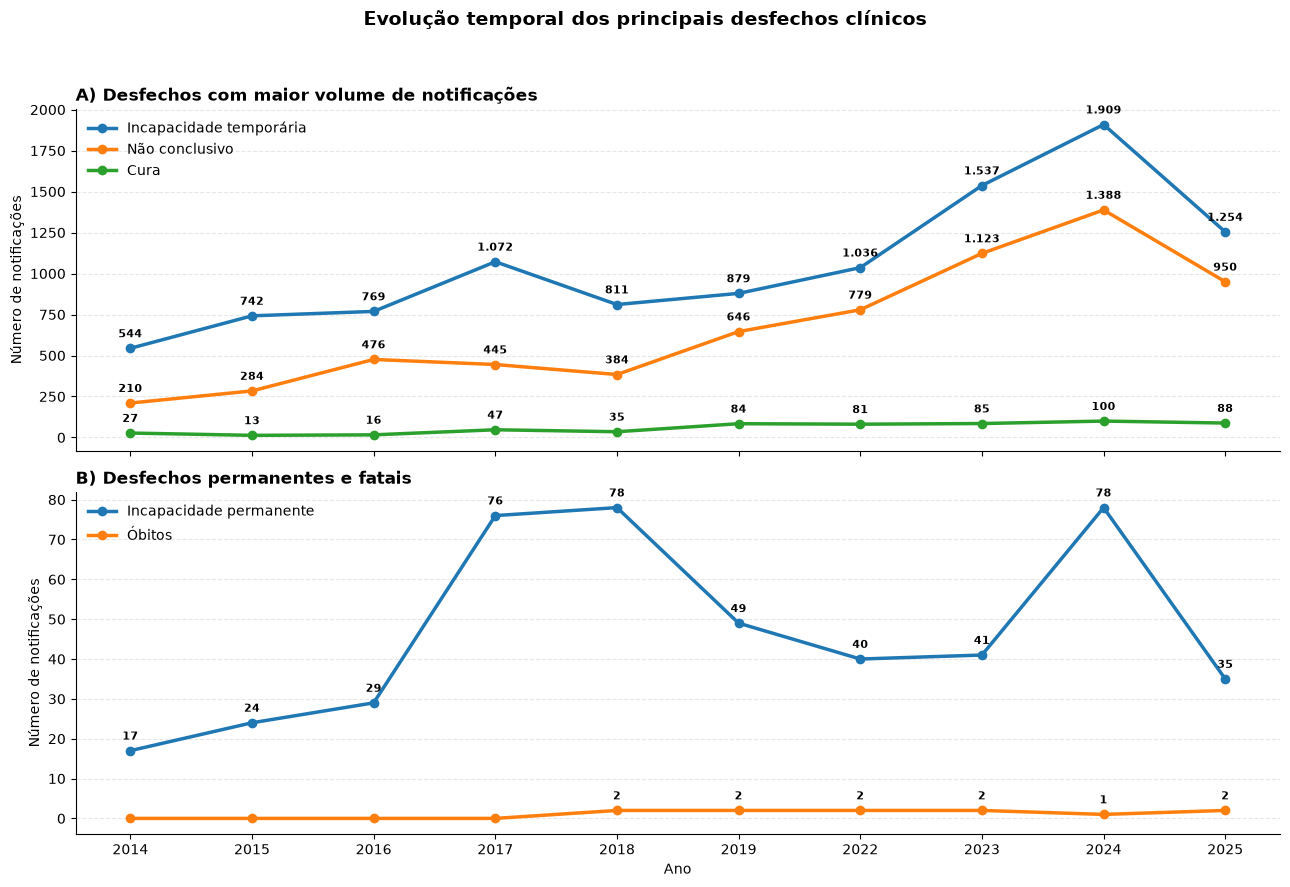

In [82]:
# ============================================================
# FIGURA — Evolução dos principais desfechos clínicos
# Painel A: grandes volumes | Painel B: desfechos raros
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

base_fig = df_epi.copy()

base_fig['EVOLUCAO'] = pd.to_numeric(base_fig['EVOLUCAO'], errors='coerce')

def agrupar_evolucao(x):
    if x == 1:
        return 'Cura'
    elif x == 3:
        return 'Incapacidade temporária'
    elif x in [4, 5]:
        return 'Incapacidade permanente'
    elif x in [6, 7]:
        return 'Óbitos'
    elif x in [2, 8, 9] or pd.isna(x):
        return 'Não conclusivo'
    else:
        return 'Não conclusivo'

base_fig['grupo_evolucao'] = base_fig['EVOLUCAO'].apply(agrupar_evolucao)

evolucao_ano = (
    pd.crosstab(base_fig['NU_ANO'], base_fig['grupo_evolucao'])
    .fillna(0)
)

for col in ['Incapacidade temporária', 'Não conclusivo', 'Cura',
            'Incapacidade permanente', 'Óbitos']:
    if col not in evolucao_ano.columns:
        evolucao_ano[col] = 0

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

# -----------------------------
# Painel A — grandes volumes
# -----------------------------
grandes = ['Incapacidade temporária', 'Não conclusivo', 'Cura']

for col in grandes:
    axes[0].plot(
        evolucao_ano.index,
        evolucao_ano[col],
        marker='o',
        linewidth=2.5,
        label=col
    )

    for x, y in zip(evolucao_ano.index, evolucao_ano[col]):
        if y > 0:
            axes[0].annotate(
                f'{int(y):,}'.replace(',', '.'),
                (x, y),
                xytext=(0, 8),
                textcoords='offset points',
                ha='center',
                fontsize=8,
                fontweight='bold'
            )

axes[0].set_title(
    'A) Desfechos com maior volume de notificações',
    loc='left',
    fontsize=12,
    fontweight='bold'
)

axes[0].set_ylabel('Número de notificações')
axes[0].grid(axis='y', linestyle='--', alpha=0.3)
axes[0].legend(frameon=False, loc='upper left')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# -----------------------------
# Painel B — desfechos raros
# -----------------------------
raros = ['Incapacidade permanente', 'Óbitos']

for col in raros:
    axes[1].plot(
        evolucao_ano.index,
        evolucao_ano[col],
        marker='o',
        linewidth=2.5,
        label=col
    )

    for x, y in zip(evolucao_ano.index, evolucao_ano[col]):
        if y > 0:
            axes[1].annotate(
                f'{int(y):,}'.replace(',', '.'),
                (x, y),
                xytext=(0, 8),
                textcoords='offset points',
                ha='center',
                fontsize=8,
                fontweight='bold'
            )

axes[1].set_title(
    'B) Desfechos permanentes e fatais',
    loc='left',
    fontsize=12,
    fontweight='bold'
)

axes[1].set_xlabel('Ano')
axes[1].set_ylabel('Número de notificações')
axes[1].set_xticks(evolucao_ano.index)
axes[1].grid(axis='y', linestyle='--', alpha=0.3)
axes[1].legend(frameon=False, loc='upper left')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

fig.suptitle(
    'Evolução temporal dos principais desfechos clínicos',
    fontsize=14,
    fontweight='bold',
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    'Figura_Evolucao_Desfechos_Paineis.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Este bloco exibe a contagem de valores (e seus percentuais) da coluna 'EVOLUCAO' no DataFrame `df` (não `df_modelo`), incluindo valores ausentes, e ordena-os pelo índice. É uma verificação rápida da distribuição bruta dos desfechos, sem o agrupamento feito nas visualizações anteriores.

A Figura acima apresenta a evolução temporal dos principais desfechos clínicos dos casos de transtornos mentais relacionados ao trabalho notificados no Brasil entre 2014 e 2024. Observa-se que a incapacidade temporária foi o desfecho predominante ao longo de todo o período analisado, apresentando crescimento expressivo após 2022. O número de notificações evoluiu de 564 casos em 2014 para 2.617 em 2024, correspondendo a um aumento superior a quatro vezes no período.

Os casos classificados como não conclusivos também apresentaram tendência de crescimento, passando de 223 registros em 2014 para 1.747 em 2024. Em contraste, os casos com evolução para cura permaneceram em patamares significativamente inferiores, variando entre 18 e 133 registros anuais.

Os desfechos mais graves, representados pelas incapacidades permanentes e pelos óbitos, mantiveram frequência relativamente baixa ao longo da série histórica. As incapacidades permanentes oscilaram entre 21 e 91 casos anuais, enquanto os óbitos permaneceram inferiores a cinco registros por ano.

Em conjunto, os resultados sugeram um aumento substancial das notificações de transtornos mentais relacionados ao trabalho na última década, com predominância de afastamentos temporários e crescimento acentuado a partir dos anos mais recentes, possivelmente refletindo maior reconhecimento dos riscos psicossociais, ampliação da vigilância em saúde do trabalhador e maior sensibilidade dos sistemas de notificação para agravos relacionados à saúde mental.

**2 = cura não confirmada
8 = outro
9 = ignorado**

Não conclusivo

A categoria não conclusiva reúne registros classificados como cura não confirmada, outro desfecho ou evolução ignorada, representando casos sem definição clínica inequívoca no encerramento da notificação.

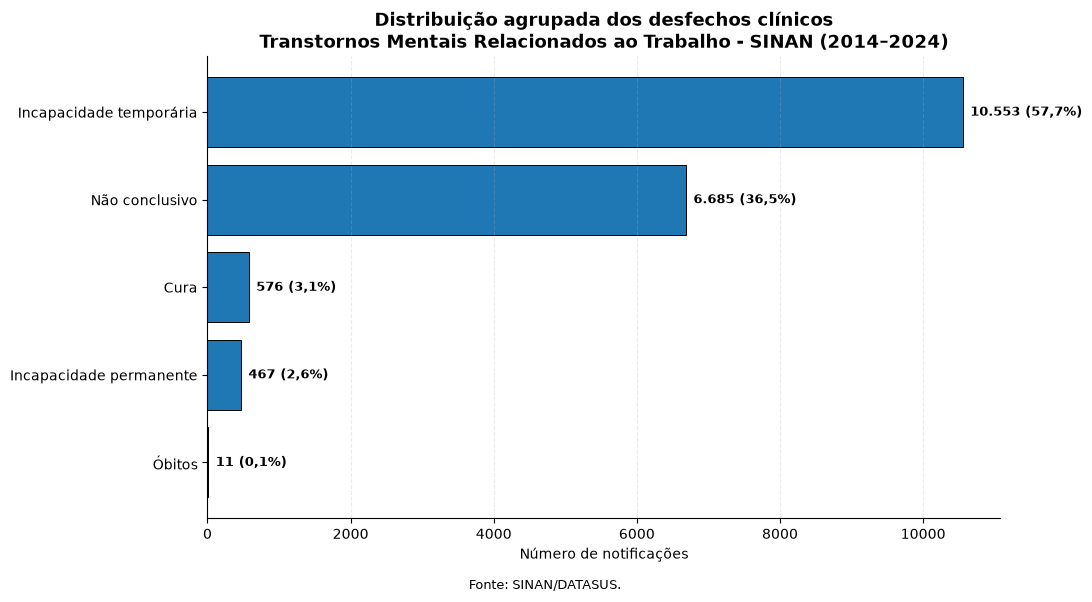

,Evolução,Frequência,Percentual
0,Incapacidade temporária,10553,57.691887
1,Não conclusivo,6685,36.546031
2,Cura,576,3.148918
3,Incapacidade permanente,467,2.553029
4,Óbitos,11,0.060136


In [83]:
# ============================================================
# FIGURA — Distribuição agrupada dos desfechos clínicos
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Base epidemiológica
dados_evolucao = df_epi.copy()

dados_evolucao['EVOLUCAO'] = pd.to_numeric(
    dados_evolucao['EVOLUCAO'],
    errors='coerce'
)

# Agrupamento dos desfechos
def agrupar_evolucao(x):
    if x == 1:
        return 'Cura'
    elif x == 3:
        return 'Incapacidade temporária'
    elif x in [4, 5]:
        return 'Incapacidade permanente'
    elif x in [6, 7]:
        return 'Óbitos'
    elif x in [2, 8, 9] or pd.isna(x):
        return 'Não conclusivo'
    else:
        return 'Não conclusivo'

dados_evolucao['evolucao_grupo'] = dados_evolucao['EVOLUCAO'].apply(
    agrupar_evolucao
)

tabela_evolucao = (
    dados_evolucao['evolucao_grupo']
    .value_counts()
    .reset_index()
)

tabela_evolucao.columns = ['Evolução', 'Frequência']

tabela_evolucao['Percentual'] = (
    tabela_evolucao['Frequência']
    / tabela_evolucao['Frequência'].sum()
    * 100
)

# Ordem do menor para maior para barra horizontal
tabela_plot = tabela_evolucao.sort_values('Frequência')

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    tabela_plot['Evolução'],
    tabela_plot['Frequência'],
    edgecolor='black',
    linewidth=0.7
)

for barra, freq, perc in zip(
    barras,
    tabela_plot['Frequência'],
    tabela_plot['Percentual']
):
    ax.text(
        barra.get_width() + max(tabela_plot['Frequência']) * 0.01,
        barra.get_y() + barra.get_height() / 2,
        f'{freq:,.0f} ({perc:.1f}%)'.replace(',', 'X').replace('.', ',').replace('X', '.'),
        va='center',
        fontsize=9,
        fontweight='bold'
    )

ax.set_title(
    'Distribuição agrupada dos desfechos clínicos\n'
    'Transtornos Mentais Relacionados ao Trabalho - SINAN (2014–2024)',
    fontsize=13,
    fontweight='bold'
)

ax.set_xlabel('Número de notificações')
ax.set_ylabel('')

ax.grid(axis='x', linestyle='--', alpha=0.25)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.figtext(
    0.5,
    0.01,
    'Fonte: SINAN/DATASUS.',
    ha='center',
    fontsize=9
)

plt.tight_layout(rect=[0, 0.03, 1, 1])

plt.savefig(
    'Figura_Desfechos_Clinicos_Agrupados.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

tabela_evolucao

In [84]:
# ============================================================
# BLOCO 10 — Remoção de variáveis sem capacidade preditiva
# ============================================================

variaveis_remover = [
    'ID_AGRAVO',      # apenas 1 categoria
    'idade',          # derivada de NU_IDADE_N
    'raca_cor',       # derivada de CS_RACA
    'faixa_etaria'    # derivada de idade
]

variaveis_remover = [
    v for v in variaveis_remover
    if v in df.columns
]

df = df_epi.drop(
    columns=variaveis_remover,
    errors='ignore'
)


print('\nDimensão atual:')
print(df.shape)


Dimensão atual:
(18292, 67)


Este bloco realiza a seleção dos casos elegíveis para análise ou modelagem. Ele copia o DataFrame `df_epi` para `df_modelo` (que já contém os CIDs filtrados). Em seguida, exibe as dimensões da base elegível, o número de diagnósticos distintos e os 20 diagnósticos mais frequentes, incluindo aqueles sem informação explícita.

In [86]:
# ============================================================
# BLOCO 11 — Seleção dos casos elegíveis
# ============================================================

print('=' * 70)
print('SELEÇÃO DOS CASOS ELEGÍVEIS')
print('=' * 70)

print('Base epidemiológica antes da seleção:')
print(df_epi.shape)

df_modelo = df_epi.copy()

print('\nBase elegível para análise/modelagem:')
print(df_modelo.shape)

print('\nDiagnósticos distintos:')
print(
    df_modelo['CID_CHAVE']
    .nunique(dropna=True)
)

print('\nVinte diagnósticos mais frequentes:')

display(
    df_modelo['CID_CHAVE']
    .fillna('Diagnóstico não informado')
    .value_counts()
    .head(20)
    .rename_axis('Diagnóstico')
    .reset_index(name='Número de casos')
)

SELEÇÃO DOS CASOS ELEGÍVEIS
Base epidemiológica antes da seleção:
(18292, 68)

Base elegível para análise/modelagem:
(18292, 68)

Diagnósticos distintos:
197

Vinte diagnósticos mais frequentes:


,Diagnóstico,Número de casos
0,F431,2079
1,F41,1878
2,F411,1772
3,F412,1613
4,F32,1117
5,F432,1115
6,F43,1047
7,F430,1003
8,F322,903
9,F410,782


Este bloco exibe a contagem de ocorrências do primeiro caractere da coluna `DIAG_ESP` no DataFrame `df_epi`. Isso pode ser útil para entender a distribuição dos diagnósticos por capítulo principal da CID-10, especialmente para identificar se há diagnósticos começando com 'F' (transtornos mentais) ou 'Z' (fatores que influenciam o estado de saúde).

**2.188 registros sem diagnóstico específico**

**21.003 - 2.188 = 18.815**

Inicialmente, a base analítica foi restrita aos diagnósticos pertencentes ao Capítulo V da CID-10 (F00–F99), correspondente aos transtornos mentais e comportamentais. Após a exclusão dos registros sem diagnóstico específico e dos casos classificados em outros capítulos da CID-10, obteve-se uma amostra de aproximadamente 15.961 notificações, utilizada nas análises preliminares.

Entretanto, durante a revisão metodológica do estudo, observou-se que essa estratégia poderia excluir condições diretamente relacionadas aos riscos psicossociais do trabalho, especialmente códigos da categoria Z, como Z73.0 (esgotamento vital/burnout) e Z56.6 (outros problemas relacionados ao emprego). Embora esses códigos não pertençam formalmente ao Capítulo V da CID-10, eles descrevem circunstâncias e condições associadas ao adoecimento mental no contexto laboral.

A ampliação da base analítica mostrou-se particularmente relevante diante das recentes atualizações da Norma Regulamentadora nº 1 (NR-1), que reforçam a necessidade de identificação, avaliação e gerenciamento dos riscos psicossociais nos ambientes de trabalho. Nesse contexto, a exclusão automática de diagnósticos pertencentes a outros capítulos da CID-10 poderia subestimar manifestações relacionadas ao sofrimento psíquico ocupacional, reduzindo a capacidade do estudo de representar adequadamente os fatores associados ao adoecimento mental dos trabalhadores.

Dessa forma, optou-se por reavaliar os critérios de elegibilidade, incorporando diagnósticos que, embora classificados fora do Capítulo V, apresentam reconhecida relação com fatores psicossociais e organizacionais do trabalho. Essa decisão resultou em uma ampliação do número de registros analisados, permitindo uma abordagem mais abrangente e alinhada às diretrizes contemporâneas de saúde mental do trabalhador e vigilância dos riscos psicossociais.


**Tabela X – Principais grupos diagnósticos excluídos na filtragem inicial por Capítulo V da CID-10 e justificativa para reinclusão**

| Grupo CID-10           | Frequência | Exemplo de código   | Descrição resumida                                                        | Justificativa para reinclusão                                                                                                                   |
| ---------------------- | ---------: | ------------------- | ------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------- |
| F00–F99                |     15.961 | F43.1, F32.0, F41.1 | Transtornos mentais e comportamentais                                     | Mantidos em todas as etapas por constituírem o núcleo do estudo                                                                                 |
| Z00–Z99                |      2.156 | Z73.0, Z56.6        | Fatores que influenciam o estado de saúde e contato com serviços de saúde | Incluem burnout, esgotamento ocupacional e problemas relacionados ao emprego, diretamente associados aos riscos psicossociais previstos na NR-1 |
| R00–R99                |        310 | R45, R53            | Sintomas, sinais e achados clínicos não classificados em outra parte      | Podem representar manifestações iniciais de sofrimento psíquico relacionadas ao trabalho                                                        |
| Y00–Y98                |        156 | Y96                 | Causas externas relacionadas ao trabalho                                  | Permitem identificar circunstâncias ocupacionais associadas ao adoecimento                                                                      |
| T00–T98                |         51 | T74                 | Consequências de lesões e outras causas externas                          | Possíveis eventos associados ao contexto ocupacional                                                                                            |
| Demais capítulos (A–X) |        175 | Diversos            | Outras condições registradas no SINAN                                     | Mantidos para avaliação de consistência e abrangência da vigilância epidemiológica                                                              |

**Total de registros após remoção de diagnósticos sem especificação (DIAG_ESP ausente): 18.809**

**Total de registros mantidos quando considerado apenas o Capítulo V (F00–F99): 15.961**

**Registros adicionais potencialmente relacionados aos riscos psicossociais e ao contexto laboral: 2.848**


Observa-se que a restrição exclusiva aos códigos F00–F99 resultaria na exclusão de 2.848 notificações. Dentre elas, destacam-se os códigos Z73.0 (burnout/esgotamento vital) e Z56.6 (problemas relacionados ao emprego), que possuem elevada pertinência para estudos sobre saúde mental do trabalhador e riscos psicossociais, especialmente após as atualizações da NR-1 que reforçam a necessidade de identificação e gestão desses fatores nos ambientes laborais.

In [ ]:
df_epi['DIAG_ESP'].str[0].value_counts()

Este bloco inspeciona a distribuição da variável 'EVOLUCAO' na base `df_modelo`. Ele exibe a contagem de cada categoria de evolução (incluindo valores ausentes) e seus respectivos percentuais, ordenados pelo índice. Isso fornece uma visão detalhada da frequência de cada desfecho clínico.

In [88]:
# ============================================================
# BLOCO 12 — Inspeção e interpretação da variável de evolução
# ============================================================

print('=' * 70)
print('DISTRIBUIÇÃO DA EVOLUÇÃO DOS CASOS')
print('=' * 70)

mapa_evolucao = {
    1: 'Cura',
    2: 'Cura não confirmada',
    3: 'Incapacidade temporária',
    4: 'Incapacidade permanente parcial',
    5: 'Incapacidade permanente total',
    6: 'Óbito por doença relacionada ao trabalho',
    7: 'Óbito por outra causa',
    8: 'Outro',
    9: 'Ignorado'
}

evolucao_num = pd.to_numeric(
    df_modelo['EVOLUCAO'],
    errors='coerce'
)

tabela_evolucao = (
    evolucao_num
    .value_counts(dropna=False)
    .rename_axis('CODIGO')
    .reset_index(name='FREQUENCIA')
)

tabela_evolucao['EVOLUCAO'] = (
    tabela_evolucao['CODIGO']
    .map(mapa_evolucao)
    .fillna('Não informado')
)

tabela_evolucao['PERCENTUAL'] = (
    100 *
    tabela_evolucao['FREQUENCIA'] /
    len(df_modelo)
)

tabela_evolucao['_ORDEM'] = (
    tabela_evolucao['CODIGO']
    .fillna(10)
)

tabela_evolucao = (
    tabela_evolucao
    .sort_values('_ORDEM')
    [['CODIGO', 'EVOLUCAO', 'FREQUENCIA', 'PERCENTUAL']]
    .reset_index(drop=True)
)

tabela_evolucao['CODIGO'] = (
    tabela_evolucao['CODIGO']
    .apply(
        lambda x:
        '—' if pd.isna(x)
        else str(int(x))
    )
)

display(
    tabela_evolucao.style
    .format({
        'FREQUENCIA': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)

DISTRIBUIÇÃO DA EVOLUÇÃO DOS CASOS


CODIGO,EVOLUCAO,FREQUENCIA,PERCENTUAL
1,Cura,576,3.15%
2,Cura não confirmada,"1,995",10.91%
3,Incapacidade temporária,"10,553",57.69%
4,Incapacidade permanente parcial,394,2.15%
5,Incapacidade permanente total,73,0.40%
6,Óbito por doença relacionada ao trabalho,7,0.04%
7,Óbito por outra causa,4,0.02%
8,Outro,"1,710",9.35%
9,Ignorado,"1,969",10.76%
—,Não informado,"1,011",5.53%


Este bloco é um placeholder para uma imagem que provavelmente deveria ter sido exibida anteriormente, mas falhou ao carregar. Não há código para reescrever aqui.

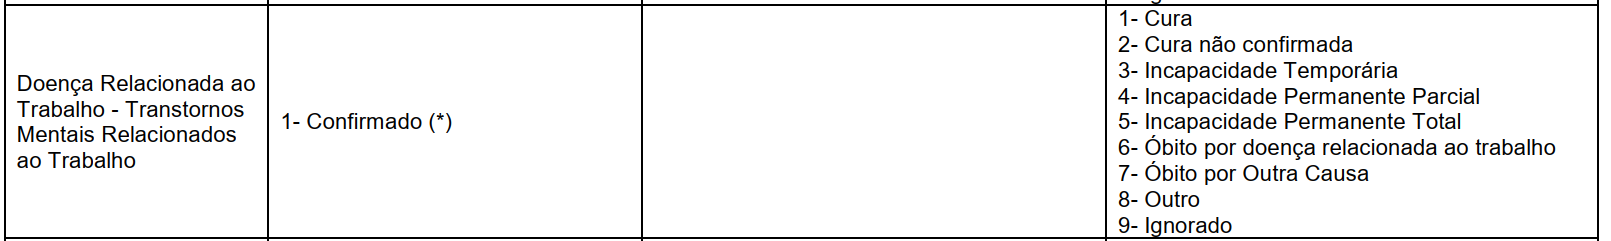

Este bloco realiza a seleção das variáveis preditoras para o modelo. Ele define uma lista de variáveis a serem removidas, incluindo a variável alvo (`EVOLUCAO`), suas derivadas, datas brutas, identificadores geográficos granulares e textos livres. Em seguida, cria `X` (preditores) e `y` (variável alvo `desfecho_grave`) e exibe as dimensões e as variáveis preditoras restantes.

In [ ]:
# ============================================================
# BLOCO 14 — Seleção das variáveis preditoras
# ============================================================

print('='*70)
print('SELEÇÃO DAS VARIÁVEIS PREDITORAS')
print('='*70)

variaveis_remover = [
    # Alvo e derivados
    'EVOLUCAO',
    'desfecho_grave',
    'evolucao_desc',

    # Datas brutas
    'DT_NOTIFIC',
    'DT_DIAG',

    # Identificadores geográficos muito granulares
    'ID_MUNICIP',
    'ID_MN_RESI',
    'MUN_EMP',

    # Textos livres
    'CONDUT_DES',
    'AFAST_DESG',

    # Variáveis derivadas redundantes
    'raca_cor',
    'faixa_etaria',
    'NU_IDADE_N',

    # Constante
    'ID_AGRAVO'
]

X = df_modelo.drop(
    columns=[c for c in variaveis_remover if c in df_modelo.columns]
).copy()

y = df_modelo['desfecho_grave'].copy()

print(f'Total de registros: {X.shape[0]:,}')
print(f'Total de preditores: {X.shape[1]}')

print('\nVariáveis candidatas:')
for i, col in enumerate(X.columns, start=1):
    print(f'{i:02d} - {col}')

Este bloco gera um resumo das variáveis candidatas a preditoras (`X`). Para cada variável, ele mostra o nome, o tipo de dado, o percentual de valores nulos e o número de valores únicos. O resumo é exibido ordenado pelo percentual de nulos de forma decrescente, o que ajuda a identificar variáveis com problemas de completude.

In [ ]:
# ============================================================
# BLOCO 15 — Perfil das variáveis candidatas
# ============================================================

print('='*70)
print('PERFIL DAS VARIÁVEIS CANDIDATAS')
print('='*70)

resumo = pd.DataFrame({
    'variavel': X.columns,
    'tipo': X.dtypes.astype(str).values,
    'nulos (%)': (X.isna().mean()*100).round(2).values,
    'unicos': [X[c].nunique(dropna=True) for c in X.columns]
})

display(
    resumo.sort_values(
        'nulos (%)',
        ascending=False
    )
)

Este bloco realiza uma associação preliminar entre variáveis categóricas selecionadas e a variável alvo `desfecho_grave`. Para cada variável, ele calcula a frequência total, o número de casos graves e o percentual de casos graves por categoria, exibindo os resultados ordenados pelo percentual de grave de forma decrescente. Isso ajuda a entender quais categorias estão mais associadas ao desfecho.

In [ ]:
# ============================================================
# BLOCO 16 — Associação preliminar com o desfecho
# ============================================================

print('='*70)
print('ASSOCIAÇÃO PRELIMINAR COM O DESFECHO')
print('='*70)

variaveis_associacao = [
    'CS_SEXO',
    'CS_RACA',
    'CS_ESCOL_N',
    'SIT_TRAB',
    'REGIME',
    'TERCEIRIZA',
    'ALCOOL',
    'PSICO_FARM',
    'DROGAS',
    'FUMA',
    'TRAB_DOE',
    'CAT'
]

for col in variaveis_associacao:

    if col in df_modelo.columns:

        print('\n' + '-'*70)
        print(f'Variável: {col}')
        print('-'*70)

        tabela = (
            df_modelo
            .groupby(col, dropna=False)['desfecho_grave']
            .agg(
                total='count',
                graves='sum',
                perc_grave='mean'
            )
            .reset_index()
        )

        tabela['perc_grave'] = (
            tabela['perc_grave'] * 100
        ).round(2)

        tabela = tabela.sort_values(
            'perc_grave',
            ascending=False
        )

        display(tabela)

Este bloco exibe a contagem de valores da coluna 'EVOLUCAO' no DataFrame `df`, incluindo valores ausentes, e os ordena pelo índice. É uma verificação adicional da distribuição dos desfechos.

In [80]:
df['EVOLUCAO'].value_counts(dropna=False).sort_index()

EVOLUCAO
      1528
1      880
2     2594
3    13697
4      501
5      114
6       17
7        5
8     2347
9     2668
Name: count, dtype: int64

Este bloco calcula a força de associação entre as variáveis categóricas e o desfecho `desfecho_grave` utilizando o teste qui-quadrado e o coeficiente V de Cramer. Ele itera sobre uma lista de variáveis categóricas, cria tabelas de contingência e calcula as estatísticas. Os resultados, incluindo o valor do qui-quadrado, p-valor e V de Cramer, são armazenados e exibidos em um DataFrame, ordenados pela força da associação (V de Cramer).

Este bloco remove variáveis do DataFrame `df` que foram consideradas sem capacidade preditiva ou redundantes para o modelo. Ele exclui variáveis como 'ID_AGRAVO' (constante), 'idade', 'raca_cor' e 'faixa_etaria' (derivadas de outras variáveis), e exibe a nova dimensão do DataFrame após a remoção.

In [ ]:
# ============================================================
# BLOCO 17 — Associação preliminar com o desfecho
# ============================================================

from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

print('='*70)
print('ASSOCIAÇÃO PRELIMINAR COM O DESFECHO')
print('='*70)

variaveis_categoricas = [
    'CS_SEXO',
    'CS_RACA',
    'CS_ESCOL_N',
    'SIT_TRAB',
    'REGIME',
    'TERCEIRIZA',
    'ALCOOL',
    'PSICO_FARM',
    'DROGAS',
    'FUMA',
    'TRAB_DOE',
    'CAT'
]

resultados = []

for var in variaveis_categoricas:

    if var not in df_modelo.columns:
        continue

    tabela = pd.crosstab(
        df_modelo[var],
        df_modelo['desfecho_grave']
    )

    try:

        chi2, p, _, _ = chi2_contingency(tabela)

        n = tabela.sum().sum()

        cramers_v = np.sqrt(
            chi2 /
            (
                n *
                (
                    min(
                        tabela.shape[0]-1,
                        tabela.shape[1]-1
                    )
                )
            )
        )

        resultados.append([
            var,
            round(chi2, 2),
            round(p, 6),
            round(cramers_v, 4)
        ])

    except:
        pass

resultado_assoc = pd.DataFrame(
    resultados,
    columns=[
        'Variável',
        'Qui-quadrado',
        'p-valor',
        'Cramers_V'
    ]
)

resultado_assoc = resultado_assoc.sort_values(
    'Cramers_V',
    ascending=False
)

display(resultado_assoc)

Este bloco cria um gráfico de barras horizontais para visualizar a força de associação entre as variáveis categóricas e o desfecho grave, utilizando o V de Cramer. As barras representam o valor do V de Cramer, e os rótulos exibem o valor do V e o p-valor correspondente. O gráfico é ordenado pela força da associação e salvo em formato PNG, oferecendo uma representação visual clara das variáveis mais relacionadas ao desfecho.

In [ ]:
# ============================================================
# FIGURA — Força de associação das variáveis com o desfecho
# ============================================================

import matplotlib.pyplot as plt

figura_assoc = resultado_assoc.copy()

# Ordenar para barra horizontal
figura_assoc = figura_assoc.sort_values(
    'Cramers_V',
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    figura_assoc['Variável'],
    figura_assoc['Cramers_V'],
    edgecolor='black',
    linewidth=0.7
)

for barra, valor, pvalor in zip(
    barras,
    figura_assoc['Cramers_V'],
    figura_assoc['p-valor']
):
    texto_p = 'p < 0,001' if pvalor < 0.001 else f'p = {pvalor:.3f}'.replace('.', ',')

    ax.text(
        barra.get_width() + max(figura_assoc['Cramers_V']) * 0.02,
        barra.get_y() + barra.get_height() / 2,
        f'V = {valor:.3f} | {texto_p}'.replace('.', ','),
        va='center',
        fontsize=9,
        fontweight='bold'
    )

ax.set_title(
    "Força de associação entre variáveis categóricas e desfecho grave\n"
    "Teste qui-quadrado e Cramér's V",
    fontsize=13,
    fontweight='bold'
)

ax.set_xlabel("Cramér's V")
ax.set_ylabel('')

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.25
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.figtext(
    0.5,
    0.01,
    "Nota: Cramér's V mede a força da associação; valores próximos de zero indicam associação fraca.",
    ha='center',
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    'Figura_Associacao_CramersV_Desfecho.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Este bloco imprime a lista ordenada de todas as colunas presentes no DataFrame `df_modelo`. É útil para uma visão geral rápida de todas as variáveis disponíveis na base de dados após o pré-processamento.

A Figura X apresenta a força de associação entre as variáveis categóricas analisadas e o desfecho clínico grave, estimada por meio do coeficiente de Cramér's V. Observou-se que a variável situação de trabalho (SIT_TRAB) apresentou a maior associação com o desfecho (V = 0,215; p < 0,001), indicando que diferentes condições ocupacionais estão relacionadas a diferentes probabilidades de evolução clínica desfavorável.

As variáveis escolaridade (CS_ESCOL_N), regime de trabalho (REGIME) e emissão de Comunicação de Acidente de Trabalho (CAT) também apresentaram associação estatisticamente significativa, embora de menor magnitude. De modo geral, os valores observados foram baixos, sugerindo que nenhuma variável isoladamente explica de forma substancial a ocorrência de desfechos graves.

Por outro lado, as variáveis relacionadas ao consumo de álcool (ALCOOL) e drogas (DROGAS) não apresentaram associação estatisticamente significativa com o desfecho (p > 0,05), indicando ausência de evidência de relação na amostra analisada.

Esses resultados reforçam a natureza multifatorial dos transtornos mentais relacionados ao trabalho, sugerindo que a ocorrência de incapacidades permanentes e óbitos depende da interação de múltiplos fatores sociodemográficos, ocupacionais e clínicos, justificando a utilização de modelos de aprendizado de máquina capazes de capturar relações complexas e não lineares entre as variáveis.


In [ ]:
print(sorted(df_modelo.columns.tolist()))

Este bloco prepara os dados para a modelagem, definindo a variável alvo `y` (`desfecho_grave`) e criando o conjunto de preditoras `X` ao remover diversas colunas consideradas redundantes, de identificação ou que não seriam usadas na modelagem. Ele também separa as colunas em numéricas e categóricas, e exibe as dimensões dos conjuntos resultantes, a distribuição da variável alvo e os percentuais de valores ausentes nas preditoras.

In [ ]:
# ============================================================
# BLOCO 18 — Preparação para modelagem
# ============================================================

print('='*70)
print('PREPARAÇÃO PARA MODELAGEM')
print('='*70)

# Conferência: X e y devem vir do df_modelo já filtrado no bloco da variável-alvo.
y = df_modelo['desfecho_grave'].copy()

X = df_modelo.drop(
    columns=[
        'EVOLUCAO','CS_GESTANT', 'UF_EMP',
        'desfecho_grave',
        'evolucao_desc',
        'DT_NOTIFIC',
        'DT_DIAG',
        'ID_MUNICIP',
        'ID_MN_RESI',
        'MUN_EMP',
        'CONDUT_DES',
        'AFAST_DESG',
        'sexo_desc',
        'raca_cor_desc',
        'escolaridade_desc',
        'alcool_desc',
        'psicofarmaco_desc',
        'drogas_desc',
        'fuma_desc',
        'trabalho_relacionado_desc',
        'afastamento_desc',
        'mudanca_trabalho_desc',
        'cat_desc',
        'capes_desc',
        'raca_cor',
        'faixa_etaria',
        'NU_IDADE_N'
    ],
    errors='ignore'
).copy()

colunas_numericas = X.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

colunas_categoricas = X.select_dtypes(
    include=['object', 'string', 'category', 'bool']
).columns.tolist()

print(f'Total de registros para modelagem: {X.shape[0]:,}')
print(f'Total de variáveis preditoras: {X.shape[1]}')

print(f'\nVariáveis numéricas ({len(colunas_numericas)}):')
print(colunas_numericas)

print(f'\nVariáveis categóricas ({len(colunas_categoricas)}):')
print(colunas_categoricas)

print('\nDistribuição da variável-alvo:')
display(
    y.value_counts()
    .rename(index={0: 'Não grave', 1: 'Grave'})
    .rename('quantidade')
    .to_frame()
)

print('\nProporção da variável-alvo:')
display(
    (y.value_counts(normalize=True) * 100)
    .round(2)
    .rename(index={0: 'Não grave', 1: 'Grave'})
    .rename('percentual')
    .to_frame()
)

print('\nPercentual de valores ausentes nas variáveis preditoras:')
display(
    (X.isna().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
    .rename('missing_%')
    .to_frame()
    .head(20)
)

Este bloco divide os dados em conjuntos de treino e teste de forma estratificada. Isso significa que a proporção das classes da variável alvo (`desfecho_grave`) é mantida tanto no conjunto de treino quanto no de teste, garantindo que ambos representem adequadamente a distribuição original. Ele exibe as dimensões dos conjuntos e a distribuição da variável alvo em cada um.

In [ ]:
# ============================================================
# BLOCO 19 — Divisão treino/teste estratificada
# ============================================================

from sklearn.model_selection import train_test_split

print('='*70)
print('DIVISÃO TREINO/TESTE')
print('='*70)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print('Treino:')
print(X_train.shape)
display(
    y_train.value_counts()
    .rename(index={0: 'Não grave', 1: 'Grave'})
    .rename('quantidade')
    .to_frame()
)

print('\nTeste:')
print(X_test.shape)
display(
    y_test.value_counts()
    .rename(index={0: 'Não grave', 1: 'Grave'})
    .rename('quantidade')
    .to_frame()
)

print('\nProporção no treino (%):')
display(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
    .rename(index={0: 'Não grave', 1: 'Grave'})
    .rename('percentual')
    .to_frame()
)

print('\nProporção no teste (%):')
display(
    (y_test.value_counts(normalize=True) * 100)
    .round(2)
    .rename(index={0: 'Não grave', 1: 'Grave'})
    .rename('percentual')
    .to_frame()
)

Este bloco define as pipelines de pré-processamento para variáveis numéricas e categóricas. Para as numéricas, utiliza um `SimpleImputer` com estratégia de mediana. Para as categóricas, usa um `SimpleImputer` com a estratégia de valor mais frequente seguido de um `OneHotEncoder`. Em seguida, cria um `ColumnTransformer` para aplicar esses pipelines às respectivas colunas, preparando os dados para os modelos de Machine Learning.

In [ ]:
# ============================================================
# BLOCO 20 — Pré-processamento dos dados
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

print('='*70)
print('PRÉ-PROCESSAMENTO DOS DADOS')
print('='*70)

# Atualiza listas após a divisão
colunas_numericas = X_train.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

colunas_categoricas = X_train.select_dtypes(
    include=['object', 'string', 'category', 'bool']
).columns.tolist()

# Pipeline para variáveis numéricas
pipeline_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Pipeline para variáveis categóricas
pipeline_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Pré-processador
preprocessador = ColumnTransformer(
    transformers=[
        ('num', pipeline_numerico, colunas_numericas),
        ('cat', pipeline_categorico, colunas_categoricas)
    ]
)

print(f'Variáveis numéricas: {len(colunas_numericas)}')
print(colunas_numericas)

print(f'\nVariáveis categóricas: {len(colunas_categoricas)}')
print(colunas_categoricas)

print('\nPré-processador criado com sucesso.')

Este bloco realiza uma limpeza final nos conjuntos de treino (`X_train`) e teste (`X_test`) para garantir a compatibilidade com os modelos do `sklearn`. Ele substitui `pd.NA` por `np.nan`, converte colunas categóricas para o tipo 'object' preenchendo valores ausentes com 'Missing', e garante que as colunas numéricas sejam do tipo numérico. Isso assegura que o pré-processador e os modelos possam lidar com os dados corretamente.

In [ ]:
# ============================================================
# BLOCO 20.1 — Limpeza final de tipos para sklearn
# ============================================================

import numpy as np
import pandas as pd

X_train = X_train.copy()
X_test = X_test.copy()

# 1) Trocar todos os pd.NA por np.nan
X_train = X_train.mask(X_train.isna(), np.nan)
X_test = X_test.mask(X_test.isna(), np.nan)

# 2) Forçar categóricas para object e substituir ausentes por texto
for col in X_train.columns:
    if str(X_train[col].dtype) in ['string', 'object', 'category', 'bool']:
        X_train[col] = X_train[col].astype('object').where(X_train[col].notna(), 'Missing')
        X_test[col] = X_test[col].astype('object').where(X_test[col].notna(), 'Missing')

# 3) Garantir numéricas como número
for col in X_train.columns:
    if col not in X_train.select_dtypes(include=['object']).columns:
        X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
        X_test[col] = pd.to_numeric(X_test[col], errors='coerce')

print('Limpeza final concluída.')
print(X_train.dtypes.value_counts())

print('\nTotal de ausentes após limpeza:')
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

Este bloco recria o `ColumnTransformer` com base nos tipos de dados atualizados após a limpeza final. Ele redefine as listas de colunas numéricas e categóricas (agora incluindo apenas 'object' para categóricas) e configura as pipelines de imputação e codificação One-Hot. O `preprocessador` final está pronto para ser integrado aos pipelines dos modelos de Machine Learning.

In [ ]:
# ============================================================
# BLOCO 20.2 — Pré-processador final
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

colunas_numericas = X_train.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

colunas_categoricas = X_train.select_dtypes(
    include=['object']
).columns.tolist()

pipeline_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

pipeline_categorico = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer(
    transformers=[
        ('num', pipeline_numerico, colunas_numericas),
        ('cat', pipeline_categorico, colunas_categoricas)
    ]
)

print('Pré-processador final criado.')
print('Numéricas:', len(colunas_numericas), colunas_numericas)
print('Categóricas:', len(colunas_categoricas), colunas_categoricas)

Este bloco define uma função chamada `avaliar_modelo` que calcula e exibe diversas métricas de avaliação para um modelo de classificação. As métricas incluem Acurácia, Precisão, Recall, F1-score e AUC-ROC. Além disso, a função imprime a matriz de confusão e o relatório de classificação, fornecendo uma visão abrangente do desempenho do modelo nos dados de teste.

In [ ]:
# ============================================================
# BLOCO 21 — Função de avaliação dos modelos
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

import pandas as pd

resultados_modelos = []

def avaliar_modelo(nome, modelo, X_test, y_test):

    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    resultados_modelos.append({
        'Modelo': nome,
        'Acurácia': acc,
        'Precisão': prec,
        'Recall': rec,
        'F1-score': f1,
        'AUC-ROC': auc
    })

    print('='*70)
    print(nome)
    print('='*70)
    print(f'Acurácia : {acc:.3f}')
    print(f'Precisão : {prec:.3f}')
    print(f'Recall   : {rec:.3f}')
    print(f'F1-score : {f1:.3f}')
    print(f'AUC-ROC  : {auc:.3f}')

    print('\nMatriz de confusão:')
    display(pd.DataFrame(
        confusion_matrix(y_test, y_pred),
        index=['Real não grave', 'Real grave'],
        columns=['Previsto não grave', 'Previsto grave']
    ))

    print('\nRelatório de classificação:')
    print(classification_report(
        y_test,
        y_pred,
        target_names=['Não grave', 'Grave']
    ))

Este bloco implementa e avalia um modelo de Regressão Logística. Ele cria uma `Pipeline` que primeiro aplica o pré-processamento (`preprocessador`) e depois treina o modelo de `LogisticRegression` com `class_weight='balanced'` para lidar com desbalanceamento de classes. O modelo é então treinado com os dados de treino e avaliado com a função `avaliar_modelo` nos dados de teste.

In [ ]:
# ============================================================
# BLOCO 22 — Regressão Logística
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

modelo_log = Pipeline(steps=[
    ('preprocessamento', preprocessador),
    ('modelo', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

modelo_log.fit(X_train, y_train)

avaliar_modelo(
    'Regressão Logística',
    modelo_log,
    X_test,
    y_test
)

Este bloco implementa e avalia um modelo de Árvore de Decisão (`DecisionTreeClassifier`). Similar aos anteriores, ele usa uma `Pipeline` para aplicar o pré-processamento e, em seguida, treinar o classificador com `max_depth=8` e `class_weight='balanced'`. O modelo é treinado e, posteriormente, avaliado nos dados de teste usando a função `avaliar_modelo`.

In [ ]:
# ============================================================
# BLOCO 23 — Decision Tree
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

modelo_dt = Pipeline(steps=[
    ('preprocessamento', preprocessador),
    ('modelo', DecisionTreeClassifier(
        max_depth=8,
        class_weight='balanced',
        random_state=42
    ))
])

modelo_dt.fit(X_train, y_train)

avaliar_modelo(
    'Decision Tree',
    modelo_dt,
    X_test,
    y_test
)

Este bloco implementa e avalia um modelo de Random Forest (`RandomForestClassifier`). Uma `Pipeline` é utilizada para o pré-processamento e o treinamento do modelo, configurado com `n_estimators=500`, `max_depth=15` e `class_weight='balanced'`. O modelo é treinado nos dados de treino e avaliado nos dados de teste pela função `avaliar_modelo`.

In [ ]:
# ============================================================
# BLOCO 24 — Random Forest
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

modelo_rf = Pipeline(steps=[
    ('preprocessamento', preprocessador),
    ('modelo', RandomForestClassifier(
        n_estimators=500,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

modelo_rf.fit(X_train, y_train)

avaliar_modelo(
    'Random Forest',
    modelo_rf,
    X_test,
    y_test
)

Este bloco implementa e avalia um modelo LightGBM (`LGBMClassifier`). Ele segue a mesma estrutura de `Pipeline`, aplicando o pré-processamento e, em seguida, treinando o `LGBMClassifier` com parâmetros como `n_estimators=500`, `learning_rate=0.05` e `class_weight='balanced'`. Após o treinamento, o modelo é avaliado usando a função `avaliar_modelo` nos dados de teste.

In [ ]:
# ============================================================
# BLOCO 25 — LightGBM
# ============================================================

from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

modelo_lgbm = Pipeline(steps=[
    ('preprocessamento', preprocessador),
    ('modelo', LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        verbose=-1
    ))
])

modelo_lgbm.fit(X_train, y_train)

avaliar_modelo(
    'LightGBM',
    modelo_lgbm,
    X_test,
    y_test
)

Este bloco realiza uma comparação final dos modelos treinados. Ele coleta os resultados de avaliação de todos os modelos (armazenados na lista `resultados_modelos`), cria um DataFrame com essas informações e os ordena pelo valor da métrica AUC-ROC de forma decrescente. O DataFrame resultante é exibido, permitindo uma visualização clara do desempenho comparativo de cada modelo.

In [ ]:
# ============================================================
# BLOCO 26 — Comparação final dos modelos
# ============================================================

comparacao_modelos = (
    pd.DataFrame(resultados_modelos)
    .sort_values('AUC-ROC', ascending=False)
    .reset_index(drop=True)
)

display(comparacao_modelos.round(3))

Este bloco gera um gráfico de barras horizontais para visualizar a comparação dos modelos com base na métrica AUC-ROC. Os modelos são ordenados pelo seu valor de AUC-ROC, e os valores são exibidos sobre as barras. O gráfico fornece uma representação visual clara de qual modelo obteve o melhor desempenho em termos de AUC-ROC, e é salvo em formato PNG.

In [ ]:
# ============================================================
# BLOCO 27 — Figura comparativa dos modelos
# ============================================================

import matplotlib.pyplot as plt

comparacao_plot = comparacao_modelos.sort_values('AUC-ROC')

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    comparacao_plot['Modelo'],
    comparacao_plot['AUC-ROC'],
    edgecolor='black',
    linewidth=0.7
)

for barra, valor in zip(barras, comparacao_plot['AUC-ROC']):
    ax.text(
        barra.get_width() + 0.005,
        barra.get_y() + barra.get_height()/2,
        f'{valor:.3f}'.replace('.', ','),
        va='center',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title(
    'Comparação dos modelos segundo AUC-ROC',
    fontsize=13,
    fontweight='bold'
)

ax.set_xlabel('AUC-ROC')
ax.set_ylabel('')
ax.set_xlim(0, 1)

ax.grid(axis='x', linestyle='--', alpha=0.25)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

plt.savefig(
    'Figura_Comparacao_Modelos_AUC.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Este bloco exibe a contagem dos 20 valores mais frequentes na coluna 'DIAG_ESP' do DataFrame `df_modelo`, mas apenas para os diagnósticos que começam com a letra 'Z'. Isso é útil para identificar e inspecionar os códigos CID da categoria 'Z' que estão presentes na base de dados, como 'Z73' (problemas relacionados a dificuldades de adaptação à vida) ou 'Z56' (problemas relacionados ao emprego e desemprego).

In [ ]:
(
    df_modelo[
        df_modelo['DIAG_ESP'].str.startswith('Z')
    ]['DIAG_ESP']
    .value_counts()
    .head(20)
)

Este bloco exibe a contagem de ocorrências do primeiro caractere da coluna 'DIAG_ESP' no DataFrame `df_modelo`. Isso ajuda a entender a distribuição dos diagnósticos por capítulo principal da CID-10 (por exemplo, 'F' para transtornos mentais, 'Z' para fatores que influenciam o estado de saúde).

In [ ]:
df_modelo['DIAG_ESP'].str[0].value_counts()

Este bloco imprime os 50 primeiros valores únicos e não nulos da coluna 'DIAG_ESP' do DataFrame `df_modelo`, ordenados alfabeticamente. Isso permite uma inspeção rápida dos diagnósticos específicos registrados na base.

In [ ]:
sorted(df_modelo['DIAG_ESP'].dropna().unique())[:50]

Este bloco define duas listas de variáveis preditoras: `variaveis_modelo_epidemiologico` (mais conservadora) e `variaveis_modelo_completo` (incluindo variáveis administrativas/laborais adicionais). Ele garante que apenas as variáveis existentes no DataFrame `df_modelo` sejam mantidas nas listas e exibe o número de variáveis e suas respectivas listas para cada modelo conceitual. Isso estabelece os conjuntos de preditores a serem usados em diferentes abordagens de modelagem.

In [90]:
# ============================================================
# BLOCO 8 — Seleção conceitual das variáveis preditoras
# ============================================================

# Modelo A — Epidemiológico/conservador:
# usa variáveis que fazem sentido como características do caso antes do desfecho.
variaveis_modelo_epidemiologico = [
    'NU_ANO',
    'idade',
    'CS_SEXO',
    'CS_RACA',
    'CS_ESCOL_N',
    'SG_UF',
    'UF_EMP',
    'ID_OCUPA_N',
    'SIT_TRAB',
    'CNAE',
    'REGIME',
    'TERCEIRIZA',
    'NUTEMPO',
    'TPTEMPO',
    'NUTEMPORIS',
    'TPTEMPORIS',
    'ID_AGRAVO',
    'DIAG_ESP',
    'ALCOOL',
    'PSICO_FARM',
    'DROGAS',
    'FUMA',
    'TEMPO_FUMA',
    'TRAB_DOE'
]

# Modelo B — Completo:
# acrescenta variáveis administrativas/laborais que podem melhorar desempenho,
# mas devem ser interpretadas com cautela por possível temporalidade posterior ao desfecho.
variaveis_modelo_completo = variaveis_modelo_epidemiologico + [
    'AFAST_TRAB',
    'MUDA_TRAB',
    'CAT',
    'CAPES',
    'INDIVIDUAL',
    'COLETIVA',
    'NENHUM'
]

# Mantém somente variáveis realmente existentes na base.
variaveis_modelo_epidemiologico = [v for v in variaveis_modelo_epidemiologico if v in df_modelo.columns]
variaveis_modelo_completo = [v for v in variaveis_modelo_completo if v in df_modelo.columns]

print('='*70)
print('SELEÇÃO CONCEITUAL DE VARIÁVEIS')
print('='*70)
print(f'Modelo epidemiológico: {len(variaveis_modelo_epidemiologico)} variáveis')
print(variaveis_modelo_epidemiologico)

print(f'\nModelo completo: {len(variaveis_modelo_completo)} variáveis')
print(variaveis_modelo_completo)

SELEÇÃO CONCEITUAL DE VARIÁVEIS
Modelo epidemiológico: 23 variáveis
['NU_ANO', 'CS_SEXO', 'CS_RACA', 'CS_ESCOL_N', 'SG_UF', 'UF_EMP', 'ID_OCUPA_N', 'SIT_TRAB', 'CNAE', 'REGIME', 'TERCEIRIZA', 'NUTEMPO', 'TPTEMPO', 'NUTEMPORIS', 'TPTEMPORIS', 'ID_AGRAVO', 'DIAG_ESP', 'ALCOOL', 'PSICO_FARM', 'DROGAS', 'FUMA', 'TEMPO_FUMA', 'TRAB_DOE']

Modelo completo: 30 variáveis
['NU_ANO', 'CS_SEXO', 'CS_RACA', 'CS_ESCOL_N', 'SG_UF', 'UF_EMP', 'ID_OCUPA_N', 'SIT_TRAB', 'CNAE', 'REGIME', 'TERCEIRIZA', 'NUTEMPO', 'TPTEMPO', 'NUTEMPORIS', 'TPTEMPORIS', 'ID_AGRAVO', 'DIAG_ESP', 'ALCOOL', 'PSICO_FARM', 'DROGAS', 'FUMA', 'TEMPO_FUMA', 'TRAB_DOE', 'AFAST_TRAB', 'MUDA_TRAB', 'CAT', 'CAPES', 'INDIVIDUAL', 'COLETIVA', 'NENHUM']


Este bloco monta duas bases de dados tratadas para modelagem: `base_modelo_epidemiologico` (contendo apenas as variáveis epidemiológicas) e `base_modelo_completo` (incluindo variáveis administrativas/laborais). Ele adiciona a variável alvo (`desfecho_grave`) a ambas as bases e exibe suas dimensões, além dos percentuais de valores ausentes em cada uma, auxiliando na escolha da base mais adequada para a modelagem.

In [89]:
# ============================================================
# BLOCO 9 — Montagem das bases tratadas para modelagem
# ============================================================

# Base A: mais defensável para o TCC.
base_modelo_epidemiologico = df_modelo[variaveis_modelo_epidemiologico + ['desfecho_grave']].copy()

# Base B: alternativa completa para comparação posterior.
base_modelo_completo = df_modelo[variaveis_modelo_completo + ['desfecho_grave']].copy()

print('='*70)
print('BASES TRATADAS')
print('='*70)
print(f'Base epidemiológica: {base_modelo_epidemiologico.shape[0]:,} linhas x {base_modelo_epidemiologico.shape[1]:,} colunas')
print(f'Base completa:        {base_modelo_completo.shape[0]:,} linhas x {base_modelo_completo.shape[1]:,} colunas')

print('\nMissing na base epidemiológica:')
display((base_modelo_epidemiologico.isna().mean()*100).round(2).sort_values(ascending=False).rename('missing_%').to_frame())

print('\nMissing na base completa:')
display((base_modelo_completo.isna().mean()*100).round(2).sort_values(ascending=False).rename('missing_%').to_frame())

NameError: name 'variaveis_modelo_epidemiologico' is not defined

Este bloco separa a base escolhida (neste caso, `base_modelo_epidemiologico`) em conjuntos de preditoras (`X`) e a variável alvo (`y`). Ele também identifica e lista as colunas numéricas e categóricas dentro de `X`. Por fim, exibe as dimensões dos conjuntos `X` e `y` e a distribuição da variável alvo, tanto em contagens absolutas quanto em percentuais, confirmando a preparação final dos dados para a modelagem.

In [ ]:
# ============================================================
# BLOCO 10 — Separação entre X e y
# ============================================================

# Escolha principal recomendada para iniciar a modelagem:
base_escolhida = base_modelo_epidemiologico.copy()

X = base_escolhida.drop(columns='desfecho_grave')
y = base_escolhida['desfecho_grave']

colunas_numericas = X.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).columns.tolist()
colunas_categoricas = X.select_dtypes(include=['object', 'string', 'category', 'bool']).columns.tolist()

print('='*70)
print('MATRIZ FINAL PARA MODELAGEM')
print('='*70)
print(f'X: {X.shape[0]:,} linhas x {X.shape[1]:,} variáveis')
print(f'y: {y.shape[0]:,} registros')

print(f'\nNuméricas ({len(colunas_numericas)}):')
print(colunas_numericas)

print(f'\nCategóricas ({len(colunas_categoricas)}):')
print(colunas_categoricas)

print('\nDistribuição do alvo:')
display(y.value_counts().rename('quantidade').to_frame())
display((y.value_counts(normalize=True)*100).round(2).rename('percentual').to_frame())

NameError: name 'base_modelo_epidemiologico' is not defined

## Decisão metodológica sugerida

Para o texto do TCC, a base **epidemiológica** é a mais defensável como modelo principal, porque reduz risco de vazamento de informação e usa variáveis mais próximas do perfil sociodemográfico, ocupacional, clínico e de exposição.

A base **completa** pode ser usada depois como análise de sensibilidade: se ela aumentar muito a AUC, isso deve ser interpretado com cautela, porque variáveis como CAT, afastamento e mudança de trabalho podem refletir eventos administrativos ou laborais posteriores ao adoecimento.

In [ ]:
# ============================================================
# BLOCO 15.4B — GERAR GRÁFICOS DE CORRESPONDÊNCIA CORRIGIDOS
# ============================================================

# ------------------------------------------------------------
# 1. Base histórica
# ------------------------------------------------------------

df_ca = df_modelagem_hist.copy()

TARGET = "TARGET_DESFECHO_ADVERSO"


# ------------------------------------------------------------
# 2. Verificações de segurança
# ------------------------------------------------------------

if TARGET not in df_ca.columns:
    raise KeyError(
        f"A variável {TARGET} não foi encontrada em df_modelagem_hist."
    )

if df_ca[TARGET].isna().any():
    raise ValueError(
        "Existem registros sem target definido na base de modelagem."
    )

if (
    pd.to_numeric(
        df_ca["NU_ANO"],
        errors="coerce"
    ) == 2025
).any():
    raise ValueError(
        "ERRO: 2025 apareceu na base histórica."
    )


print("=" * 100)
print("BLOCO 15.4B — GRÁFICOS DE CORRESPONDÊNCIA CORRIGIDOS")
print("=" * 100)

print(f"\nRegistros utilizados: {len(df_ca):,}")
print("✓ Base histórica reconstruída.")
print("✓ Target definido.")
print("✓ 2025 permanece reservado.")


# ------------------------------------------------------------
# 3. Variáveis
# ------------------------------------------------------------

variaveis_ca = [
    "CS_SEXO",
    "DROGAS",
    "CS_ESCOL_N",
    "FUMA",
    "CS_RACA",
    "SIT_TRAB",
    "ALCOOL",
    "PSICO_FARM",
    "SG_UF",
    "NU_ANO"
]


variaveis_ca = [
    v
    for v in variaveis_ca
    if v in df_ca.columns
]


print(
    f"\nVariáveis que terão gráficos gerados: "
    f"{len(variaveis_ca)}"
)

for v in variaveis_ca:
    print("  ✓", v)


# ------------------------------------------------------------
# 4. Gerar gráficos
# ------------------------------------------------------------

resultados_ca_corrigidos = {}


for variavel in variaveis_ca:

    print("\n" + "=" * 100)
    print(f"ANÁLISE DE CORRESPONDÊNCIA — {variavel}")
    print("=" * 100)

    resultado_plot = plot_correspondencia_1d(
        df_ca,
        variavel
    )

    resultados_ca_corrigidos[
        variavel
    ] = resultado_plot


# ------------------------------------------------------------
# 5. Finalização
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("BLOCO 15.4B CONCLUÍDO")
print("=" * 100)

print(
    f"✓ {len(resultados_ca_corrigidos)} gráficos gerados."
)

print(
    "✓ Nenhuma variável foi alterada."
)

print(
    "✓ 2025 permaneceu fora da análise."
)

NameError: name 'df_modelagem_hist' is not defined

In [62]:
# ============================================================
# CHECKPOINT — ESTADO ATUAL DO NOTEBOOK
# ============================================================

objetos_importantes = [
    "df",
    "df_epi",
    "df_modelo",
    "df_analitico",
    "df_analitico_completo",
    "df_historico",
    "df_holdout_2025",
    "df_modelagem_hist",
    "df_ca",
    "df_15_2b",
    "df_15_2b_rotulado",
    "df_dicionario_analitico",
    "df_validacao_dicionario",
    "resultados_ca_corrigidos"
]

print("=" * 80)
print("CHECKPOINT — OBJETOS DISPONÍVEIS")
print("=" * 80)

for nome in objetos_importantes:

    if nome in globals():

        obj = globals()[nome]

        if hasattr(obj, "shape"):
            print(
                f"✓ {nome:<30} "
                f"{obj.shape[0]:>8,} linhas × "
                f"{obj.shape[1]:>3} colunas"
            )
        else:
            print(f"✓ {nome:<30} existe")

    else:
        print(f"✗ {nome:<30} NÃO existe")


print("\n" + "=" * 80)
print("TARGETS")
print("=" * 80)

for target in [
    "TARGET_DESFECHO_ADVERSO",
    "TARGET_INCAPACIDADE",
    "TARGET_INCAPACIDADE_ESTRITO"
]:

    encontrados = []

    for nome in [
        "df_modelagem_hist",
        "df_historico",
        "df_modelo",
        "df_epi",
        "df"
    ]:

        if nome in globals():

            obj = globals()[nome]

            if hasattr(obj, "columns") and target in obj.columns:
                encontrados.append(nome)

    if encontrados:
        print(
            f"✓ {target}: "
            + ", ".join(encontrados)
        )
    else:
        print(f"✗ {target}: não encontrado")


print("\n" + "=" * 80)
print("FIM DO CHECKPOINT")
print("=" * 80)

CHECKPOINT — OBJETOS DISPONÍVEIS
✓ df                               24,356 linhas ×  65 colunas
✗ df_epi                         NÃO existe
✗ df_modelo                      NÃO existe
✗ df_analitico                   NÃO existe
✗ df_analitico_completo          NÃO existe
✗ df_historico                   NÃO existe
✗ df_holdout_2025                NÃO existe
✗ df_modelagem_hist              NÃO existe
✗ df_ca                          NÃO existe
✗ df_15_2b                       NÃO existe
✗ df_15_2b_rotulado              NÃO existe
✗ df_dicionario_analitico        NÃO existe
✗ df_validacao_dicionario        NÃO existe
✗ resultados_ca_corrigidos       NÃO existe

TARGETS
✗ TARGET_DESFECHO_ADVERSO: não encontrado
✗ TARGET_INCAPACIDADE: não encontrado
✗ TARGET_INCAPACIDADE_ESTRITO: não encontrado

FIM DO CHECKPOINT
